# EDA 

In [30]:
import geopandas as gpd
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np
import itertools
import fiona
from sklearn.metrics import confusion_matrix


## 1) EDA of Raw Centralities Measures

### 1.1) SPearman and R2 correlations

In [4]:

# Set the shapefile folder path
folder = r"C:\Users\aaraldi\Desktop\EMC2_Streetscape\FLAVIA_Results_2005\paper_foreground_street_network\0_segment_analysis\shapefiles"

# List of cities
cities = ["nice", "vienna", "gothenburg", "lille", "versilia"]

# Dictionary to store loaded GeoDataFrames
city_data = {}

# Load all shapefiles once
for city in cities:
    file_path = os.path.join(folder, f"s3_segment_analysis_{city}.shp")
    gdf = gpd.read_file(file_path)
    city_data[city] = gdf

In [20]:
def compute_correlations(df, radius_columns, method='spearman'):
    if method == 'spearman':
        corr, _ = spearmanr(df[radius_columns])
        return pd.DataFrame(corr, index=radius_columns, columns=radius_columns)
    elif method == 'r2':
        r2_matrix = np.zeros((len(radius_columns), len(radius_columns)))
        for i, col1 in enumerate(radius_columns):
            for j, col2 in enumerate(radius_columns):
                x = df[[col1]].values
                y = df[[col2]].values
                model = LinearRegression().fit(x, y)
                y_pred = model.predict(x)
                r2_matrix[i, j] = r2_score(y, y_pred)
        return pd.DataFrame(r2_matrix, index=radius_columns, columns=radius_columns)

def analyze_cities_correlation(city_data, cities, radius_columns, corr_methods=['spearman', 'r2']):
    for city in cities:
        print(f"\nProcessing {city}...")
        gdf = city_data[city]

        # check columns
        missing = [col for col in radius_columns if col not in gdf.columns]
        if missing:
            print(f"Missing columns in {city}: {missing}")
            continue

        df = gdf[radius_columns].dropna()

        results = {}
        for method in corr_methods:
            results[method] = compute_correlations(df, radius_columns, method=method)

        for method, corr_matrix in results.items():
            plt.figure(figsize=(10, 8))
            cmap = "coolwarm" if method == "spearman" else "YlGnBu"
            title = "Spearman Rank Correlation" if method == "spearman" else "Linear R² Correlation"
            sns.heatmap(corr_matrix, annot=True, cmap=cmap, fmt=".2f")
            plt.title(f"{title} – {city}")
            plt.tight_layout()
            plt.show()

        print("\nRaw correlation matrices:")
        for method, corr_matrix in results.items():
            print(f"\n{method.capitalize()} Correlation Matrix for {city}:")
            display(corr_matrix)



Processing nice...


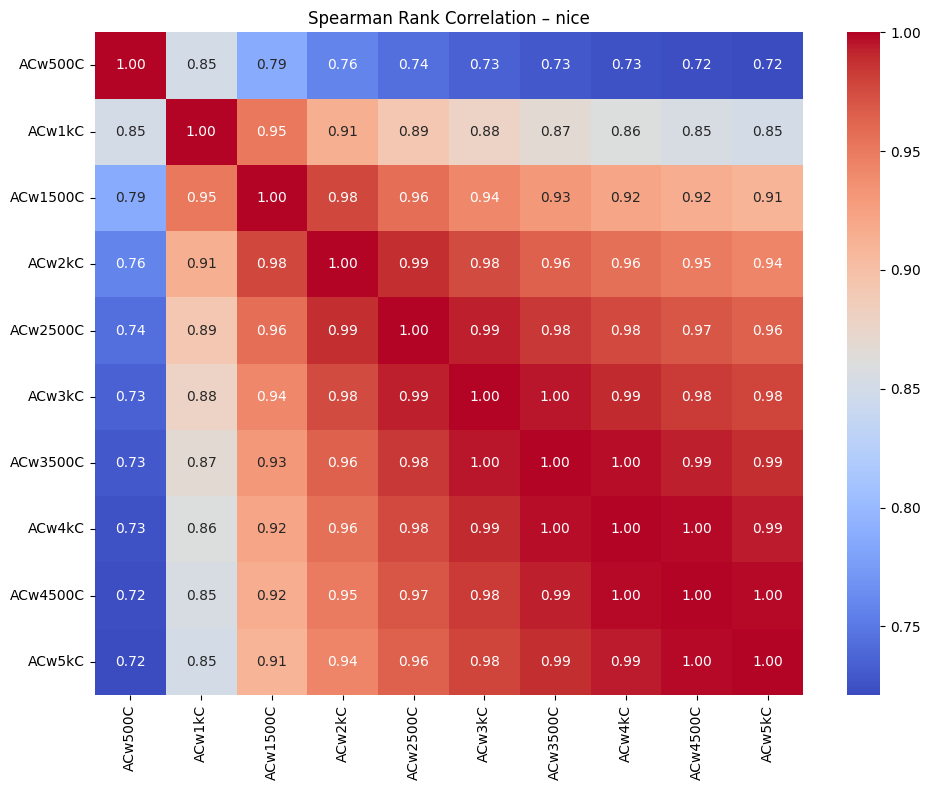

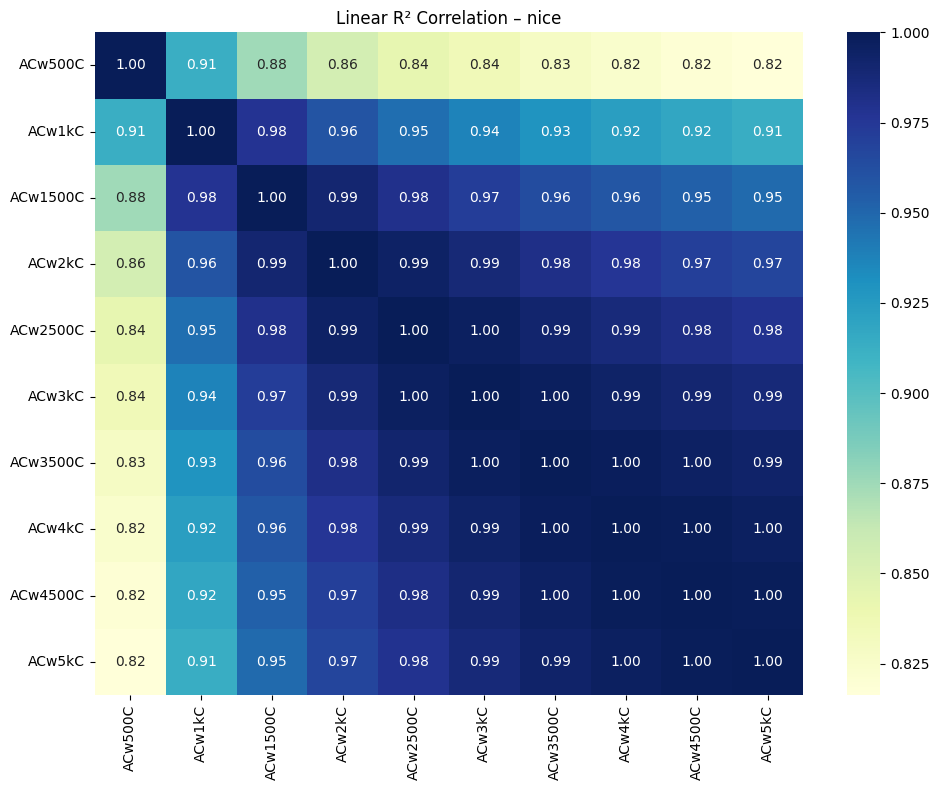


Raw correlation matrices:

Spearman Correlation Matrix for nice:


,ACw500C,ACw1kC,ACw1500C,ACw2kC,ACw2500C,ACw3kC,ACw3500C,ACw4kC,ACw4500C,ACw5kC
ACw500C,1.000000,0.849756,0.786844,0.757520,0.743006,0.734916,0.729199,0.725366,0.722810,0.721160
ACw1kC,0.849756,1.000000,0.951685,0.914577,0.892472,0.878287,0.867727,0.860065,0.854571,0.850611
ACw1500C,0.786844,0.951685,1.000000,0.978055,0.957302,0.942128,0.930517,0.921605,0.915044,0.910050
ACw2kC,0.757520,0.914577,0.978055,1.000000,0.988773,0.975672,0.964717,0.955884,0.949077,0.943541
ACw2500C,0.743006,0.892472,0.957302,0.988773,1.000000,0.993247,0.984325,0.976414,0.969778,0.964286
ACw3kC,0.734916,0.878287,0.942128,0.975672,0.993247,1.000000,0.995583,0.989377,0.983544,0.978425
ACw3500C,0.729199,0.867727,0.930517,0.964717,0.984325,0.995583,1.000000,0.996956,0.992539,0.988090
ACw4kC,0.725366,0.860065,0.921605,0.955884,0.976414,0.989377,0.996956,1.000000,0.997863,0.994458
ACw4500C,0.722810,0.854571,0.915044,0.949077,0.969778,0.983544,0.992539,0.997863,1.000000,0.998308
ACw5kC,0.721160,0.850611,0.910050,0.943541,0.964286,0.978425,0.988090,0.994458,0.998308,1.000000



R2 Correlation Matrix for nice:


,ACw500C,ACw1kC,ACw1500C,ACw2kC,ACw2500C,ACw3kC,ACw3500C,ACw4kC,ACw4500C,ACw5kC
ACw500C,1.000000,0.912517,0.875038,0.855406,0.843301,0.835155,0.828624,0.823550,0.819430,0.816305
ACw1kC,0.912517,1.000000,0.977456,0.959295,0.946455,0.936974,0.929106,0.922776,0.917578,0.913417
ACw1500C,0.875038,0.977456,1.000000,0.990320,0.979918,0.971404,0.964047,0.957858,0.952712,0.948522
ACw2kC,0.855406,0.959295,0.990320,1.000000,0.994648,0.987912,0.981562,0.975987,0.971227,0.967176
ACw2500C,0.843301,0.946455,0.979918,0.994648,1.000000,0.996604,0.991731,0.987024,0.982738,0.978998
ACw3kC,0.835155,0.936974,0.971404,0.987912,0.996604,1.000000,0.997598,0.994061,0.990469,0.987142
ACw3500C,0.828624,0.929106,0.964047,0.981562,0.991731,0.997598,1.000000,0.998285,0.995654,0.992846
ACw4kC,0.823550,0.922776,0.957858,0.975987,0.987024,0.994061,0.998285,1.000000,0.998717,0.996608
ACw4500C,0.819430,0.917578,0.952712,0.971227,0.982738,0.990469,0.995654,0.998717,1.000000,0.998937
ACw5kC,0.816305,0.913417,0.948522,0.967176,0.978998,0.987142,0.992846,0.996608,0.998937,1.000000



Processing vienna...


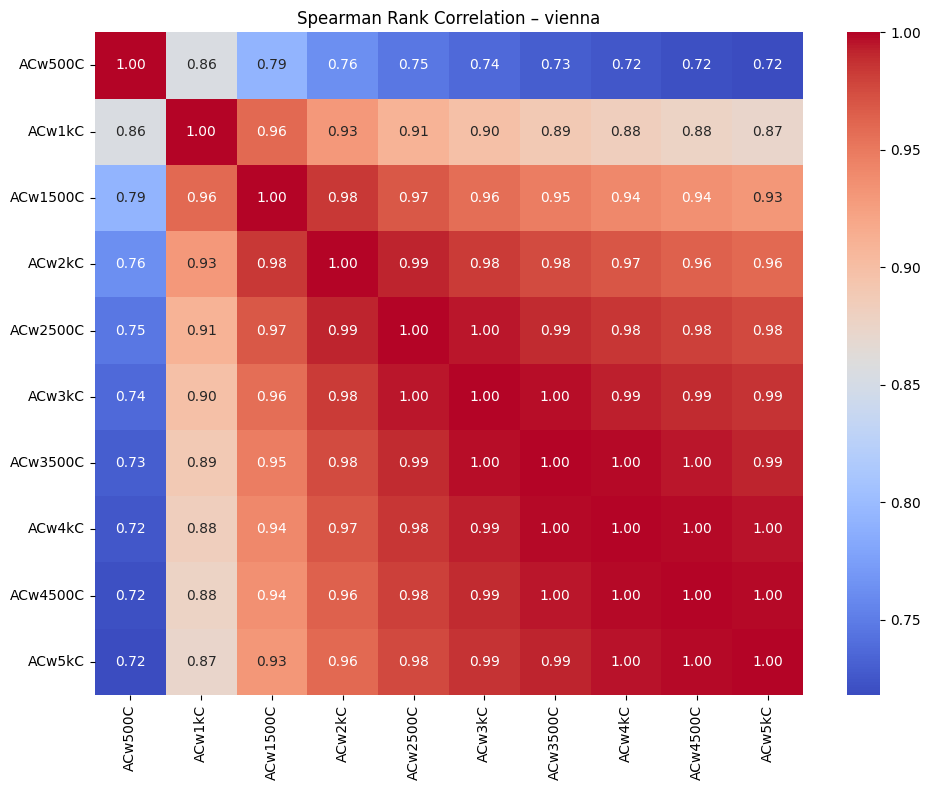

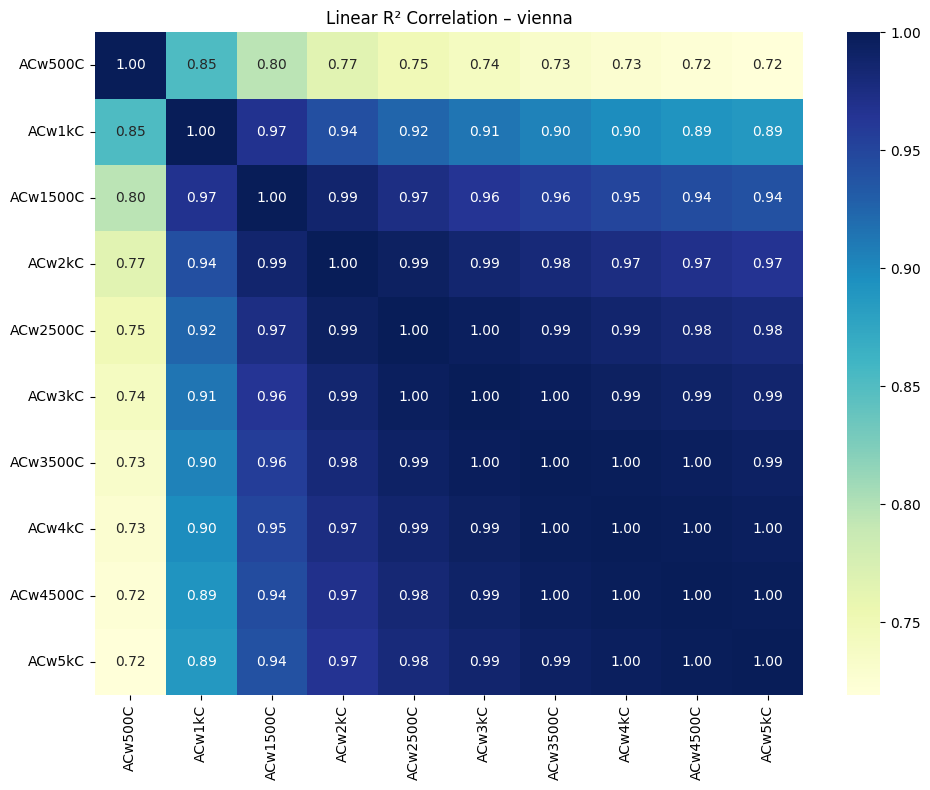


Raw correlation matrices:

Spearman Correlation Matrix for vienna:


,ACw500C,ACw1kC,ACw1500C,ACw2kC,ACw2500C,ACw3kC,ACw3500C,ACw4kC,ACw4500C,ACw5kC
ACw500C,1.000000,0.855131,0.792772,0.762331,0.746239,0.736775,0.729788,0.724626,0.721138,0.717952
ACw1kC,0.855131,1.000000,0.959570,0.929525,0.910462,0.898110,0.889113,0.882151,0.877034,0.872908
ACw1500C,0.792772,0.959570,1.000000,0.983759,0.968087,0.956505,0.947687,0.940820,0.935446,0.931002
ACw2kC,0.762331,0.929525,0.983759,1.000000,0.991758,0.982806,0.975464,0.969414,0.964360,0.959950
ACw2500C,0.746239,0.910462,0.968087,0.991758,1.000000,0.995402,0.989834,0.984820,0.980353,0.976283
ACw3kC,0.736775,0.898110,0.956505,0.982806,0.995402,1.000000,0.997050,0.993315,0.989569,0.985979
ACw3500C,0.729788,0.889113,0.947687,0.975464,0.989834,0.997050,1.000000,0.998018,0.995199,0.992217
ACw4kC,0.724626,0.882151,0.940820,0.969414,0.984820,0.993315,0.998018,1.000000,0.998404,0.996120
ACw4500C,0.721138,0.877034,0.935446,0.964360,0.980353,0.989569,0.995199,0.998404,1.000000,0.998681
ACw5kC,0.717952,0.872908,0.931002,0.959950,0.976283,0.985979,0.992217,0.996120,0.998681,1.000000



R2 Correlation Matrix for vienna:


,ACw500C,ACw1kC,ACw1500C,ACw2kC,ACw2500C,ACw3kC,ACw3500C,ACw4kC,ACw4500C,ACw5kC
ACw500C,1.000000,0.852696,0.795135,0.765825,0.749581,0.740220,0.732996,0.727242,0.722963,0.719117
ACw1kC,0.852696,1.000000,0.968177,0.942384,0.924853,0.913393,0.904793,0.897752,0.892224,0.887536
ACw1500C,0.795135,0.968177,1.000000,0.986927,0.974001,0.964138,0.956317,0.949843,0.944439,0.939704
ACw2kC,0.765825,0.942384,0.986927,1.000000,0.993675,0.986549,0.980368,0.974827,0.969921,0.965453
ACw2500C,0.749581,0.924853,0.974001,0.993675,1.000000,0.996482,0.991963,0.987506,0.983316,0.979351
ACw3kC,0.740220,0.913393,0.964138,0.986549,0.996482,1.000000,0.997622,0.994416,0.991000,0.987601
ACw3500C,0.732996,0.904793,0.956317,0.980368,0.991963,0.997622,1.000000,0.998281,0.995773,0.993029
ACw4kC,0.727242,0.897752,0.949843,0.974827,0.987506,0.994416,0.998281,1.000000,0.998602,0.996553
ACw4500C,0.722963,0.892224,0.944439,0.969921,0.983316,0.991000,0.995773,0.998602,1.000000,0.998835
ACw5kC,0.719117,0.887536,0.939704,0.965453,0.979351,0.987601,0.993029,0.996553,0.998835,1.000000



Processing gothenburg...


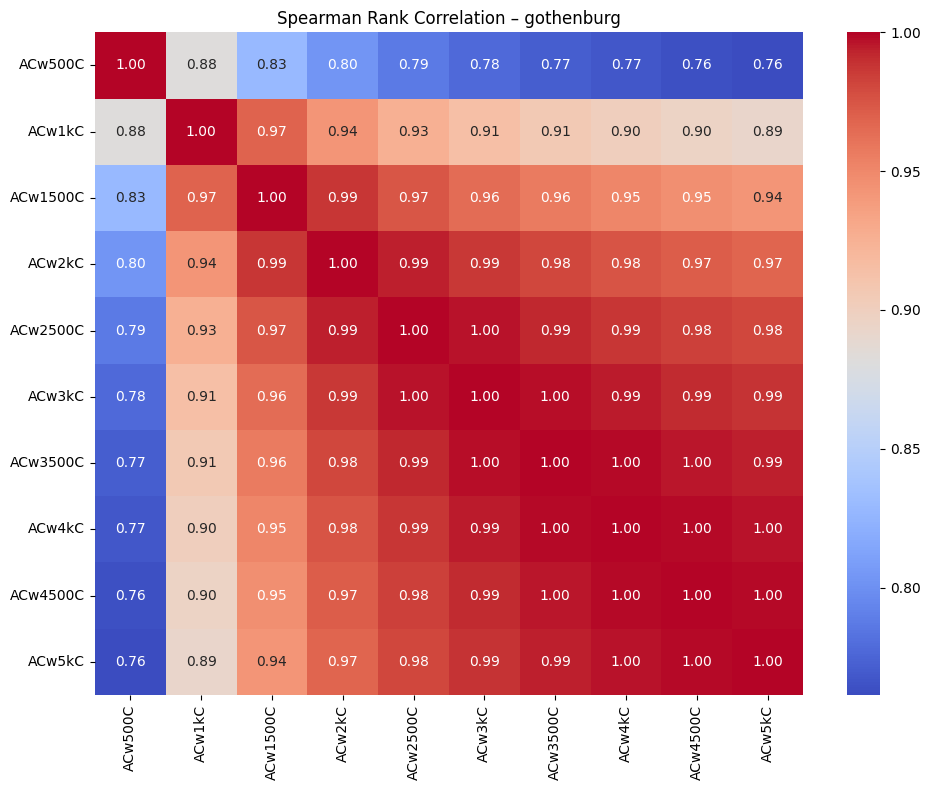

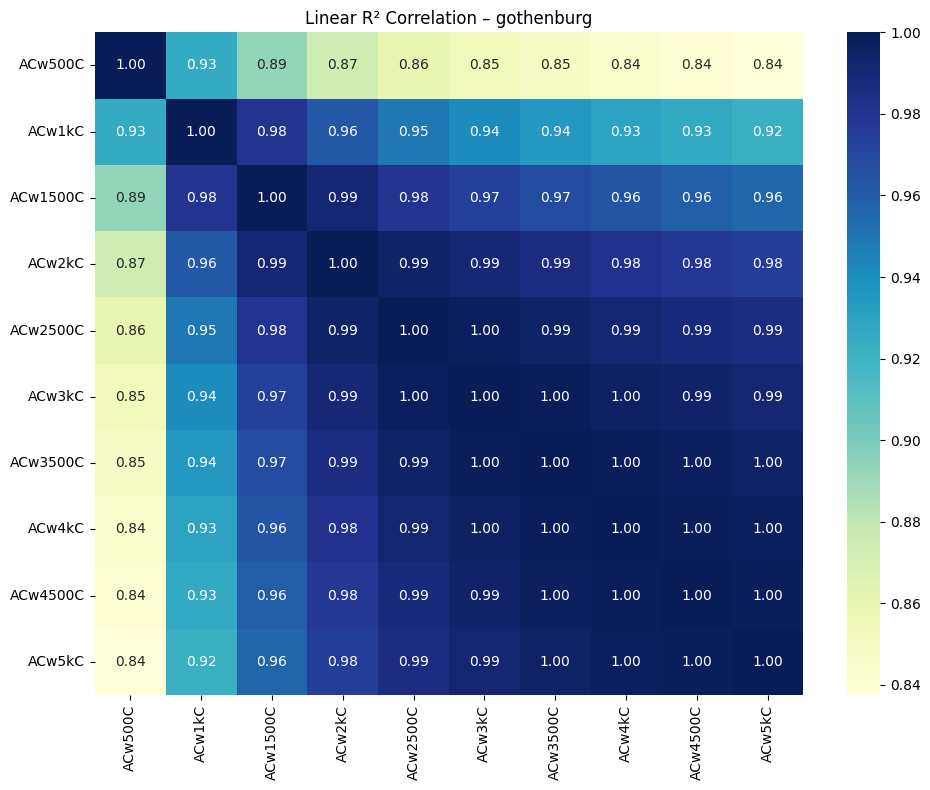


Raw correlation matrices:

Spearman Correlation Matrix for gothenburg:


,ACw500C,ACw1kC,ACw1500C,ACw2kC,ACw2500C,ACw3kC,ACw3500C,ACw4kC,ACw4500C,ACw5kC
ACw500C,1.000000,0.881658,0.828598,0.802861,0.787072,0.777559,0.771142,0.767102,0.763760,0.761330
ACw1kC,0.881658,1.000000,0.968644,0.942600,0.925534,0.914340,0.906492,0.900694,0.896035,0.892388
ACw1500C,0.828598,0.968644,1.000000,0.987017,0.974047,0.964427,0.957076,0.951305,0.946582,0.942866
ACw2kC,0.802861,0.942600,0.987017,1.000000,0.993727,0.986634,0.980586,0.975571,0.971294,0.967769
ACw2500C,0.787072,0.925534,0.974047,0.993727,1.000000,0.996312,0.991786,0.987612,0.983934,0.980753
ACw3kC,0.777559,0.914340,0.964427,0.986634,0.996312,1.000000,0.997636,0.994466,0.991417,0.988638
ACw3500C,0.771142,0.906492,0.957076,0.980586,0.991786,0.997636,1.000000,0.998311,0.996042,0.993787
ACw4kC,0.767102,0.900694,0.951305,0.975571,0.987612,0.994466,0.998311,1.000000,0.998770,0.997070
ACw4500C,0.763760,0.896035,0.946582,0.971294,0.983934,0.991417,0.996042,0.998770,1.000000,0.999056
ACw5kC,0.761330,0.892388,0.942866,0.967769,0.980753,0.988638,0.993787,0.997070,0.999056,1.000000



R2 Correlation Matrix for gothenburg:


,ACw500C,ACw1kC,ACw1500C,ACw2kC,ACw2500C,ACw3kC,ACw3500C,ACw4kC,ACw4500C,ACw5kC
ACw500C,1.000000,0.925501,0.892811,0.874187,0.860698,0.853147,0.847833,0.843861,0.840231,0.837523
ACw1kC,0.925501,1.000000,0.980412,0.962370,0.949133,0.941105,0.935065,0.930164,0.925799,0.922416
ACw1500C,0.892811,0.980412,1.000000,0.990811,0.980378,0.973728,0.968349,0.963749,0.959649,0.956387
ACw2kC,0.874187,0.962370,0.990811,1.000000,0.994847,0.989966,0.985663,0.981757,0.978165,0.975129
ACw2500C,0.860698,0.949133,0.980378,0.994847,1.000000,0.997661,0.994532,0.991383,0.988360,0.985670
ACw3kC,0.853147,0.941105,0.973728,0.989966,0.997661,1.000000,0.998425,0.996131,0.993717,0.991423
ACw3500C,0.847833,0.935065,0.968349,0.985663,0.994532,0.998425,1.000000,0.998830,0.997106,0.995292
ACw4kC,0.843861,0.930164,0.963749,0.981757,0.991383,0.996131,0.998830,1.000000,0.999114,0.997808
ACw4500C,0.840231,0.925799,0.959649,0.978165,0.988360,0.993717,0.997106,0.999114,1.000000,0.999320
ACw5kC,0.837523,0.922416,0.956387,0.975129,0.985670,0.991423,0.995292,0.997808,0.999320,1.000000



Processing lille...


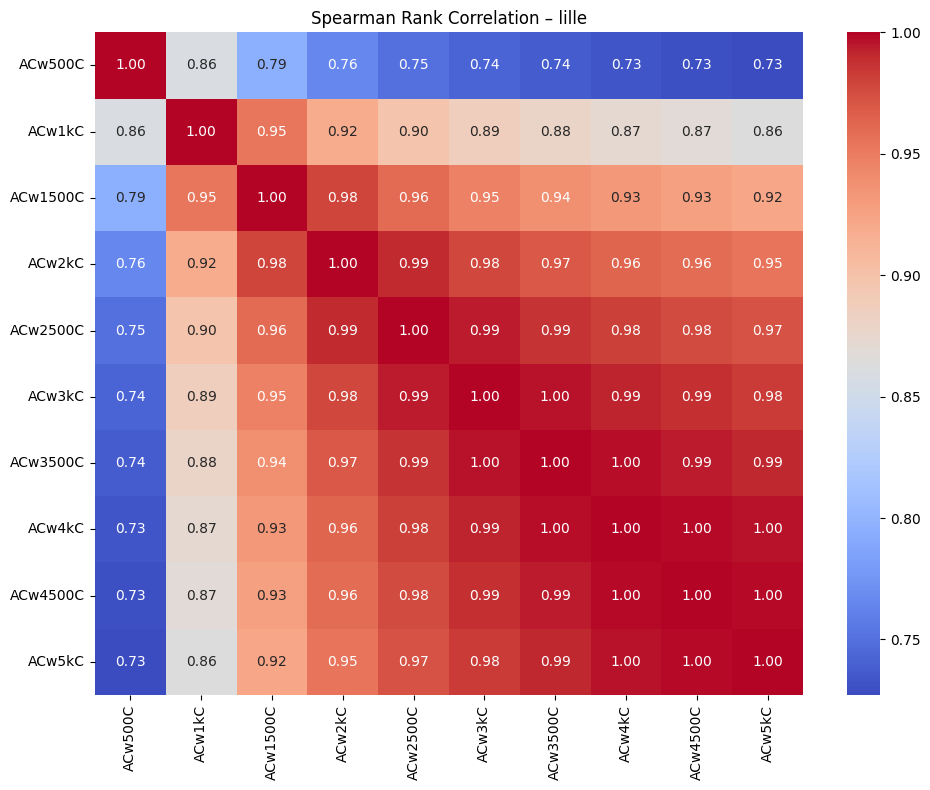

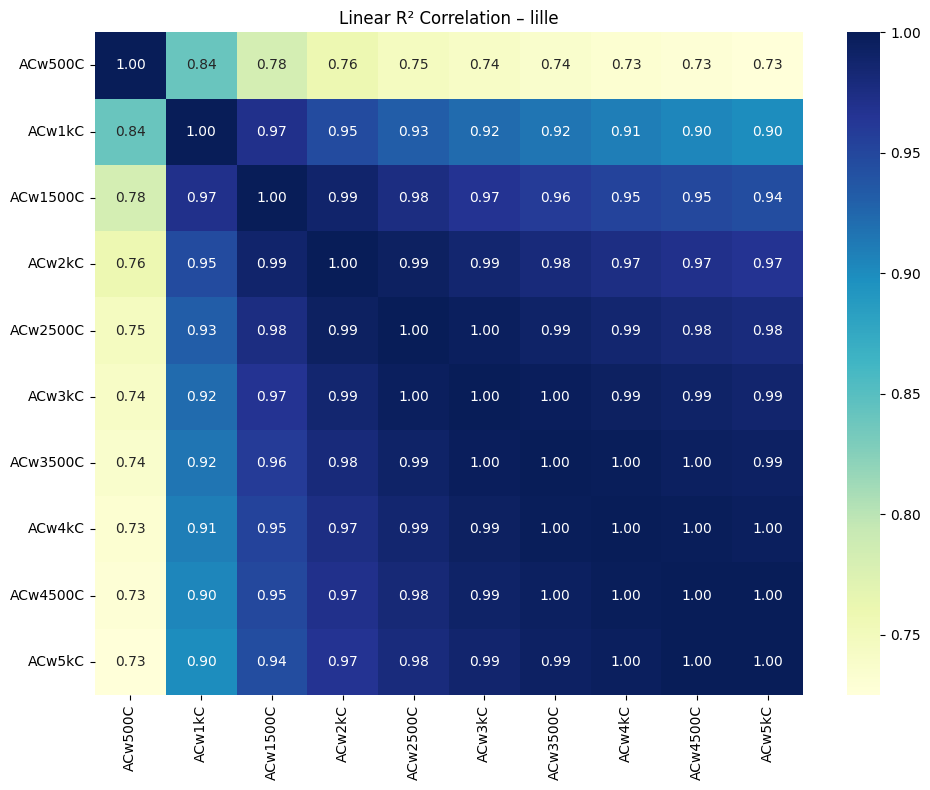


Raw correlation matrices:

Spearman Correlation Matrix for lille:


,ACw500C,ACw1kC,ACw1500C,ACw2kC,ACw2500C,ACw3kC,ACw3500C,ACw4kC,ACw4500C,ACw5kC
ACw500C,1.000000,0.859559,0.794830,0.764798,0.750092,0.742605,0.737596,0.733334,0.729928,0.727114
ACw1kC,0.859559,1.000000,0.953250,0.918827,0.897970,0.886204,0.878699,0.872827,0.868277,0.864431
ACw1500C,0.794830,0.953250,1.000000,0.979738,0.960326,0.947056,0.938445,0.932148,0.927196,0.923111
ACw2kC,0.764798,0.918827,0.979738,1.000000,0.989725,0.978387,0.969721,0.963355,0.958474,0.954424
ACw2500C,0.750092,0.897970,0.960326,0.989725,1.000000,0.994174,0.987010,0.980981,0.976303,0.972413
ACw3kC,0.742605,0.886204,0.947056,0.978387,0.994174,1.000000,0.996393,0.991663,0.987452,0.983862
ACw3500C,0.737596,0.878699,0.938445,0.969721,0.987010,0.996393,1.000000,0.997597,0.994304,0.991183
ACw4kC,0.733334,0.872827,0.932148,0.963355,0.980981,0.991663,0.997597,1.000000,0.998294,0.995896
ACw4500C,0.729928,0.868277,0.927196,0.958474,0.976303,0.987452,0.994304,0.998294,1.000000,0.998743
ACw5kC,0.727114,0.864431,0.923111,0.954424,0.972413,0.983862,0.991183,0.995896,0.998743,1.000000



R2 Correlation Matrix for lille:


,ACw500C,ACw1kC,ACw1500C,ACw2kC,ACw2500C,ACw3kC,ACw3500C,ACw4kC,ACw4500C,ACw5kC
ACw500C,1.000000,0.839974,0.782293,0.758787,0.747453,0.741157,0.736606,0.732251,0.728360,0.725007
ACw1kC,0.839974,1.000000,0.970018,0.947301,0.932220,0.922461,0.915263,0.909243,0.904019,0.899445
ACw1500C,0.782293,0.970018,1.000000,0.988333,0.976111,0.966691,0.959611,0.953781,0.948724,0.944321
ACw2kC,0.758787,0.947301,0.988333,1.000000,0.993881,0.986483,0.980107,0.974786,0.970195,0.966107
ACw2500C,0.747453,0.932220,0.976111,0.993881,1.000000,0.996270,0.991282,0.986592,0.982496,0.978808
ACw3kC,0.741157,0.922461,0.966691,0.986483,0.996270,1.000000,0.997480,0.993925,0.990424,0.987182
ACw3500C,0.736606,0.915263,0.959611,0.980107,0.991282,0.997480,1.000000,0.998182,0.995529,0.992796
ACw4kC,0.732251,0.909243,0.953781,0.974786,0.986592,0.993925,0.998182,1.000000,0.998616,0.996569
ACw4500C,0.728360,0.904019,0.948724,0.970195,0.982496,0.990424,0.995529,0.998616,1.000000,0.998930
ACw5kC,0.725007,0.899445,0.944321,0.966107,0.978808,0.987182,0.992796,0.996569,0.998930,1.000000



Processing versilia...


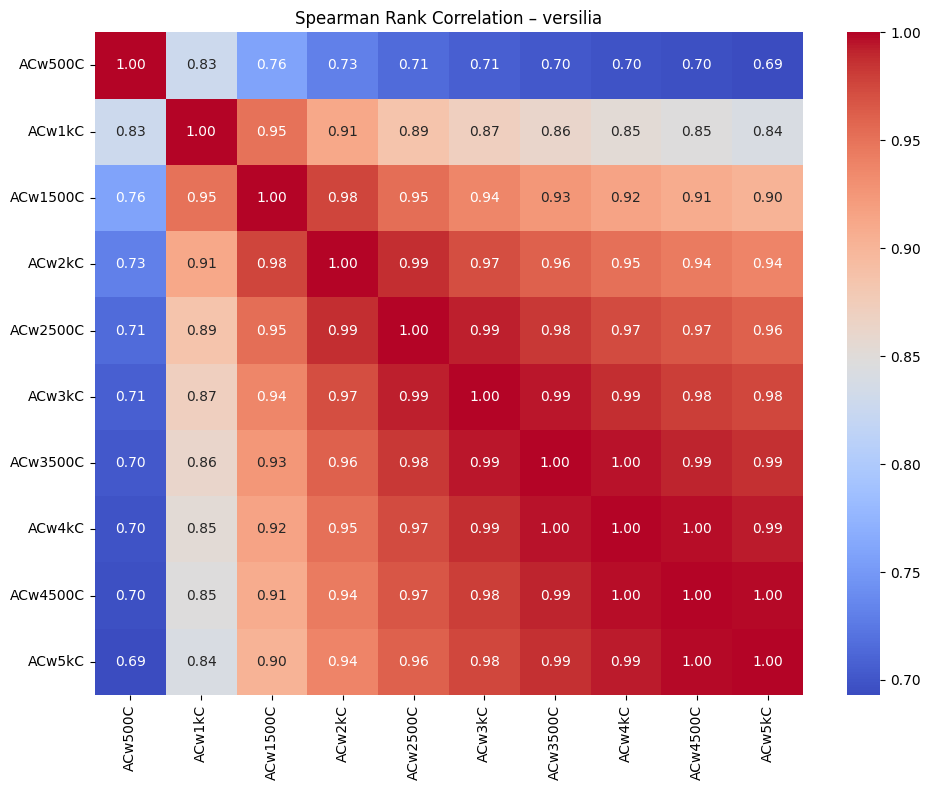

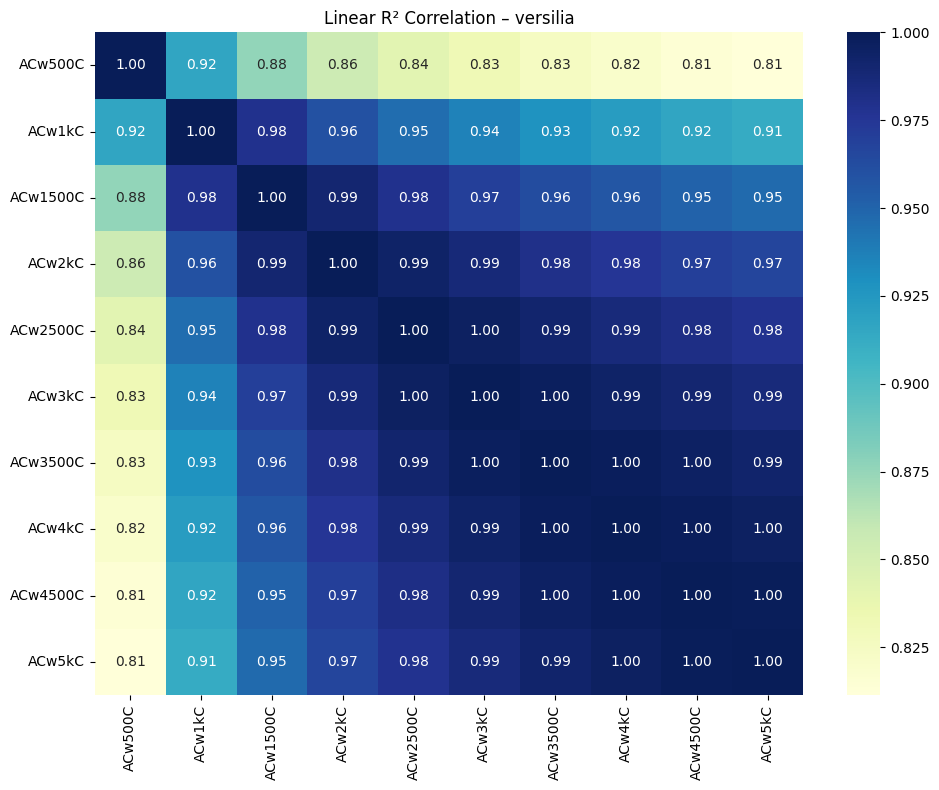


Raw correlation matrices:

Spearman Correlation Matrix for versilia:


,ACw500C,ACw1kC,ACw1500C,ACw2kC,ACw2500C,ACw3kC,ACw3500C,ACw4kC,ACw4500C,ACw5kC
ACw500C,1.000000,0.828403,0.758782,0.730799,0.714803,0.706290,0.702278,0.698695,0.695510,0.693018
ACw1kC,0.828403,1.000000,0.949862,0.911405,0.885492,0.870976,0.861268,0.853149,0.846684,0.841508
ACw1500C,0.758782,0.949862,1.000000,0.976844,0.953007,0.936942,0.925089,0.915625,0.908131,0.902066
ACw2kC,0.730799,0.911405,0.976844,1.000000,0.986821,0.972211,0.960696,0.951195,0.943746,0.937707
ACw2500C,0.714803,0.885492,0.953007,0.986821,1.000000,0.992206,0.982410,0.973567,0.966431,0.960843
ACw3kC,0.706290,0.870976,0.936942,0.972211,0.992206,1.000000,0.994691,0.987088,0.980459,0.975423
ACw3500C,0.702278,0.861268,0.925089,0.960696,0.982410,0.994691,1.000000,0.995979,0.990512,0.986026
ACw4kC,0.698695,0.853149,0.915625,0.951195,0.973567,0.987088,0.995979,1.000000,0.997057,0.993222
ACw4500C,0.695510,0.846684,0.908131,0.943746,0.966431,0.980459,0.990512,0.997057,1.000000,0.997767
ACw5kC,0.693018,0.841508,0.902066,0.937707,0.960843,0.975423,0.986026,0.993222,0.997767,1.000000



R2 Correlation Matrix for versilia:


,ACw500C,ACw1kC,ACw1500C,ACw2kC,ACw2500C,ACw3kC,ACw3500C,ACw4kC,ACw4500C,ACw5kC
ACw500C,1.000000,0.916207,0.875936,0.855074,0.841967,0.832049,0.825349,0.819594,0.814829,0.811378
ACw1kC,0.916207,1.000000,0.978720,0.959881,0.945966,0.936053,0.928529,0.922012,0.916599,0.912356
ACw1500C,0.875936,0.978720,1.000000,0.989914,0.978816,0.969979,0.962786,0.956573,0.951283,0.946956
ACw2kC,0.855074,0.959881,0.989914,1.000000,0.994017,0.986854,0.980612,0.975024,0.970205,0.966153
ACw2500C,0.841967,0.945966,0.978816,0.994017,1.000000,0.996176,0.991208,0.986386,0.982125,0.978509
ACw3kC,0.832049,0.936053,0.969979,0.986854,0.996176,1.000000,0.997358,0.993453,0.989741,0.986622
ACw3500C,0.825349,0.928529,0.962786,0.980612,0.991208,0.997358,1.000000,0.997958,0.995049,0.992396
ACw4kC,0.819594,0.922012,0.956573,0.975024,0.986386,0.993453,0.997958,1.000000,0.998422,0.996271
ACw4500C,0.814829,0.916599,0.951283,0.970205,0.982125,0.989741,0.995049,0.998422,1.000000,0.998750
ACw5kC,0.811378,0.912356,0.946956,0.966153,0.978509,0.986622,0.992396,0.996271,0.998750,1.000000


In [21]:
radius_columns_AC = [
    "ACw500C", "ACw1kC", "ACw1500C", "ACw2kC", "ACw2500C",
    "ACw3kC", "ACw3500C", "ACw4kC", "ACw4500C", "ACw5kC"
]

analyze_cities_correlation(city_data, cities, radius_columns_AC)


Processing nice...


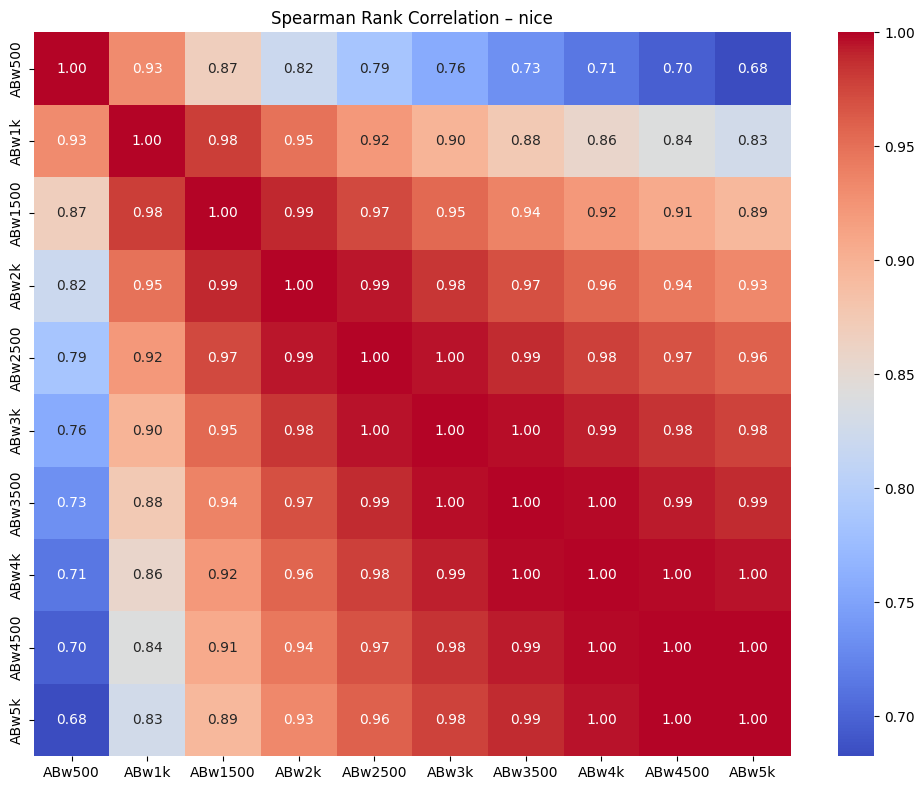

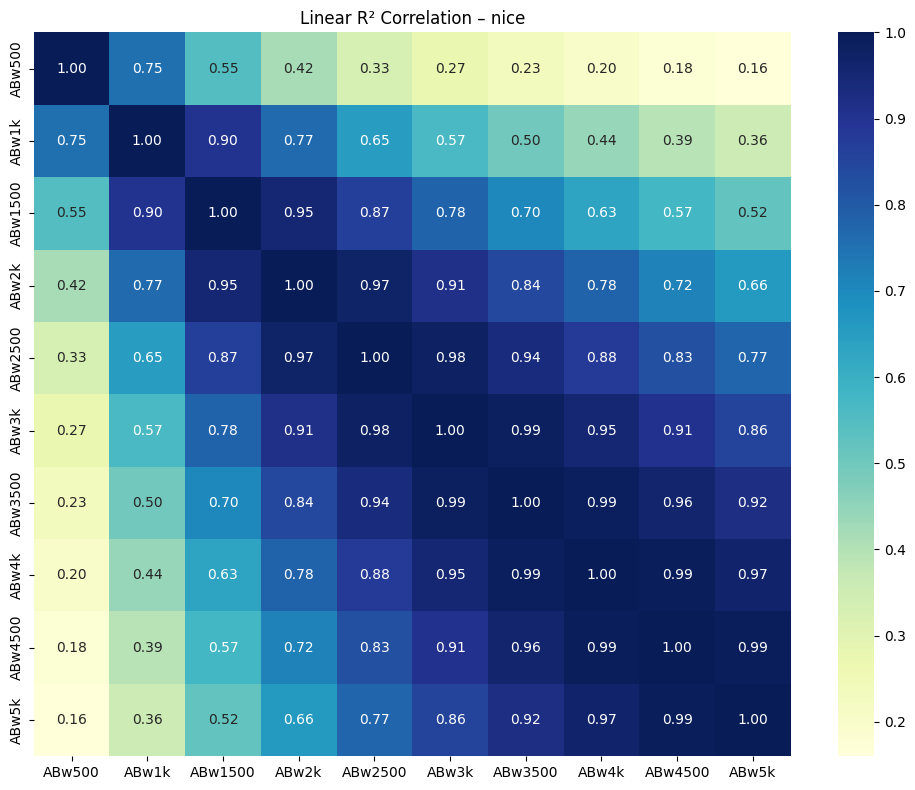


Raw correlation matrices:

Spearman Correlation Matrix for nice:


,ABw500,ABw1k,ABw1500,ABw2k,ABw2500,ABw3k,ABw3500,ABw4k,ABw4500,ABw5k
ABw500,1.000000,0.931751,0.867644,0.820823,0.785642,0.757231,0.733516,0.713797,0.696803,0.682375
ABw1k,0.931751,1.000000,0.979164,0.949024,0.921537,0.897306,0.875841,0.857237,0.840769,0.826490
ABw1500,0.867644,0.979164,1.000000,0.990011,0.972711,0.954592,0.937113,0.921124,0.906479,0.893437
ABw2k,0.820823,0.949024,0.990011,1.000000,0.994204,0.982950,0.970033,0.957195,0.944834,0.933444
ABw2500,0.785642,0.921537,0.972711,0.994204,1.000000,0.996222,0.988247,0.978827,0.968981,0.959442
ABw3k,0.757231,0.897306,0.954592,0.982950,0.996222,1.000000,0.997310,0.991507,0.984338,0.976787
ABw3500,0.733516,0.875841,0.937113,0.970033,0.988247,0.997310,1.000000,0.998068,0.993728,0.988256
ABw4k,0.713797,0.857237,0.921124,0.957195,0.978827,0.991507,0.998068,1.000000,0.998551,0.995215
ABw4500,0.696803,0.840769,0.906479,0.944834,0.968981,0.984338,0.993728,0.998551,1.000000,0.998867
ABw5k,0.682375,0.826490,0.893437,0.933444,0.959442,0.976787,0.988256,0.995215,0.998867,1.000000



R2 Correlation Matrix for nice:


,ABw500,ABw1k,ABw1500,ABw2k,ABw2500,ABw3k,ABw3500,ABw4k,ABw4500,ABw5k
ABw500,1.000000,0.753772,0.549787,0.417452,0.330656,0.274324,0.233443,0.202912,0.179039,0.160094
ABw1k,0.753772,1.000000,0.903966,0.766646,0.652480,0.565496,0.496053,0.440029,0.393982,0.356031
ABw1500,0.549787,0.903966,1.000000,0.951260,0.865750,0.780022,0.701963,0.633805,0.574793,0.524048
ABw2k,0.417452,0.766646,0.951260,1.000000,0.971048,0.911484,0.844121,0.778345,0.716740,0.660941
ABw2500,0.330656,0.652480,0.865750,0.971048,1.000000,0.979686,0.935151,0.881576,0.825375,0.770605
ABw3k,0.274324,0.565496,0.780022,0.911484,0.979686,1.000000,0.985305,0.951082,0.906904,0.858737
ABw3500,0.233443,0.496053,0.701963,0.844121,0.935151,0.985305,1.000000,0.988713,0.960843,0.923402
ABw4k,0.202912,0.440029,0.633805,0.778345,0.881576,0.951082,0.988713,1.000000,0.990668,0.966988
ABw4500,0.179039,0.393982,0.574793,0.716740,0.825375,0.906904,0.960843,0.990668,1.000000,0.992070
ABw5k,0.160094,0.356031,0.524048,0.660941,0.770605,0.858737,0.923402,0.966988,0.992070,1.000000



Processing vienna...


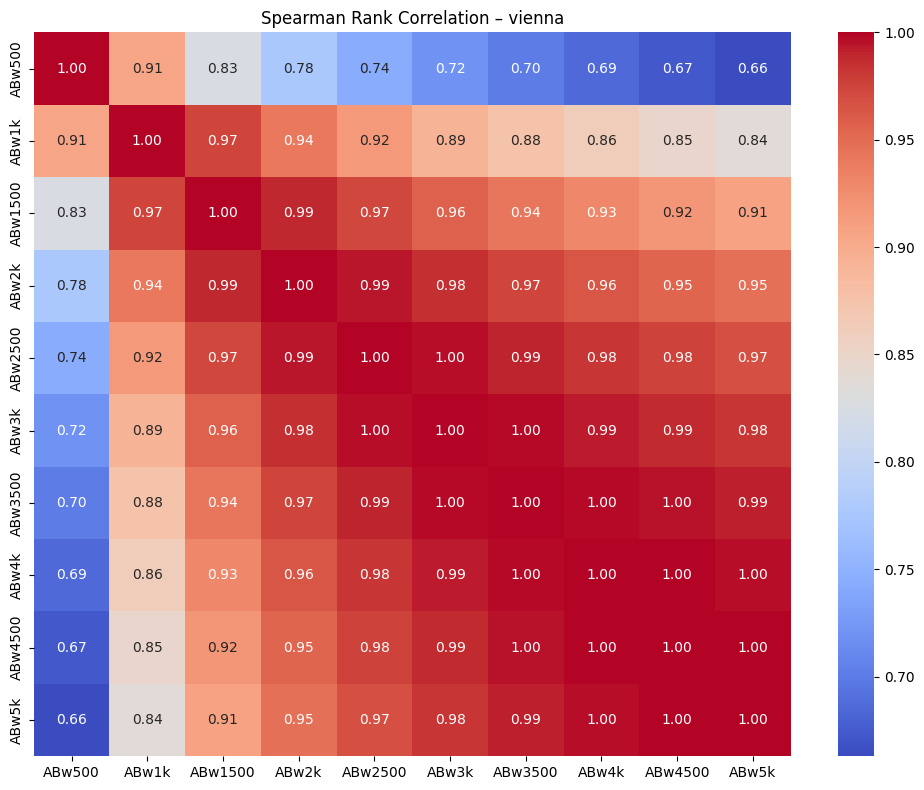

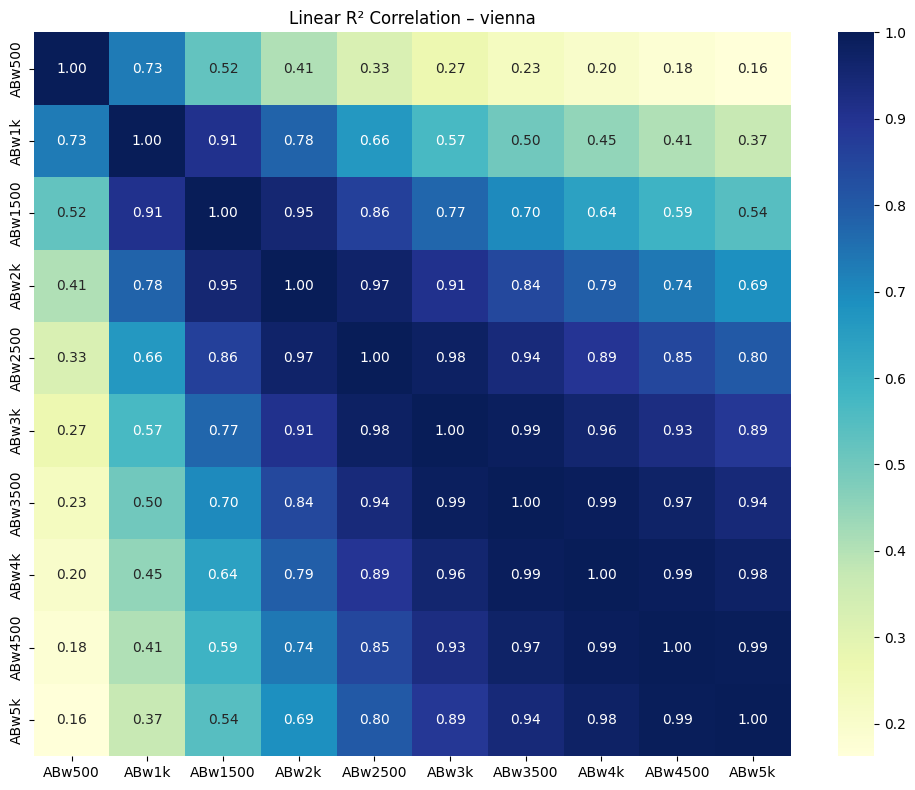


Raw correlation matrices:

Spearman Correlation Matrix for vienna:


,ABw500,ABw1k,ABw1500,ABw2k,ABw2500,ABw3k,ABw3500,ABw4k,ABw4500,ABw5k
ABw500,1.000000,0.906115,0.826049,0.777240,0.744171,0.719852,0.700725,0.685592,0.673251,0.662886
ABw1k,0.906115,1.000000,0.974132,0.941641,0.915040,0.893284,0.875355,0.860575,0.848057,0.837112
ABw1500,0.826049,0.974132,1.000000,0.989450,0.973008,0.956818,0.942336,0.929865,0.918858,0.908869
ABw2k,0.777240,0.941641,0.989450,1.000000,0.994504,0.984518,0.973931,0.964061,0.954797,0.946070
ABw2500,0.744171,0.915040,0.973008,0.994504,1.000000,0.996550,0.989945,0.982669,0.975244,0.967934
ABw3k,0.719852,0.893284,0.956818,0.984518,0.996550,1.000000,0.997693,0.993171,0.987731,0.981958
ABw3500,0.700725,0.875355,0.942336,0.973931,0.989945,0.997693,1.000000,0.998436,0.995088,0.990859
ABw4k,0.685592,0.860575,0.929865,0.964061,0.982669,0.993171,0.998436,1.000000,0.998779,0.996135
ABw4500,0.673251,0.848057,0.918858,0.954797,0.975244,0.987731,0.995088,0.998779,1.000000,0.999025
ABw5k,0.662886,0.837112,0.908869,0.946070,0.967934,0.981958,0.990859,0.996135,0.999025,1.000000



R2 Correlation Matrix for vienna:


,ABw500,ABw1k,ABw1500,ABw2k,ABw2500,ABw3k,ABw3500,ABw4k,ABw4500,ABw5k
ABw500,1.000000,0.728927,0.523053,0.406976,0.325385,0.268387,0.230436,0.202685,0.180687,0.162411
ABw1k,0.728927,1.000000,0.907199,0.779730,0.664007,0.568822,0.500804,0.449044,0.406367,0.369254
ABw1500,0.523053,0.907199,1.000000,0.953040,0.864803,0.773491,0.700112,0.640647,0.589387,0.543065
ABw2k,0.406976,0.779730,0.953040,1.000000,0.969282,0.907019,0.844828,0.788708,0.736940,0.687948
ABw2500,0.325385,0.664007,0.864803,0.969282,1.000000,0.979133,0.938776,0.894065,0.848153,0.801769
ABw3k,0.268387,0.568822,0.773491,0.907019,0.979133,1.000000,0.987400,0.960241,0.925879,0.887195
ABw3500,0.230436,0.500804,0.700112,0.844828,0.938776,0.987400,1.000000,0.991448,0.970748,0.942232
ABw4k,0.202685,0.449044,0.640647,0.788708,0.894065,0.960241,0.991448,1.000000,0.993270,0.975912
ABw4500,0.180687,0.406367,0.589387,0.736940,0.848153,0.925879,0.970748,0.993270,1.000000,0.994262
ABw5k,0.162411,0.369254,0.543065,0.687948,0.801769,0.887195,0.942232,0.975912,0.994262,1.000000



Processing gothenburg...


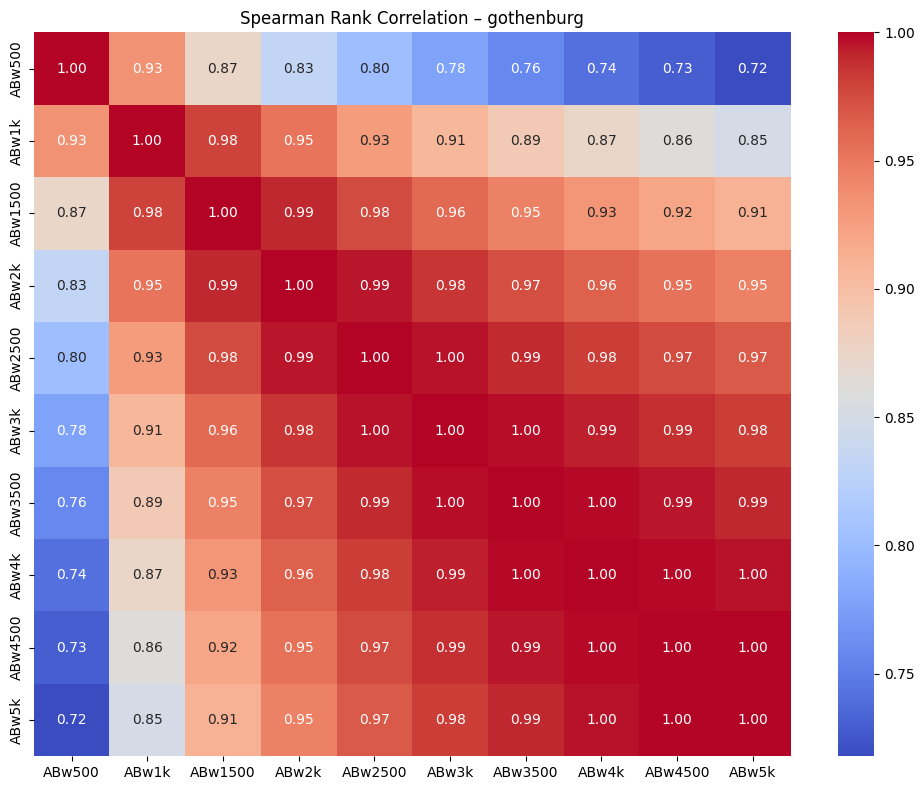

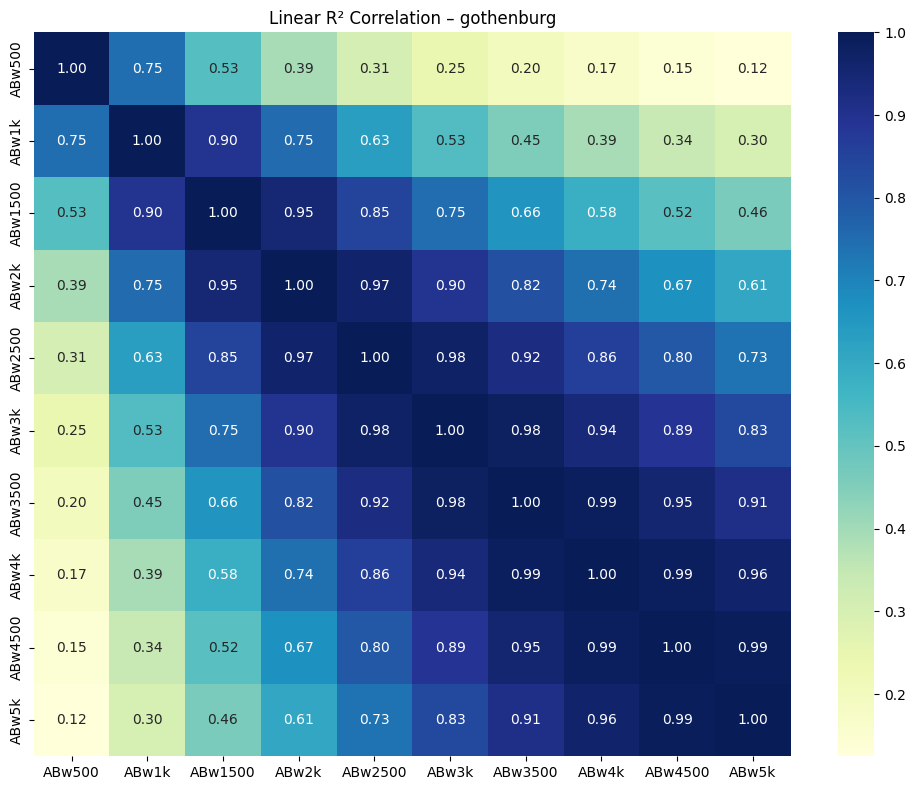


Raw correlation matrices:

Spearman Correlation Matrix for gothenburg:


,ABw500,ABw1k,ABw1500,ABw2k,ABw2500,ABw3k,ABw3500,ABw4k,ABw4500,ABw5k
ABw500,1.000000,0.934611,0.874108,0.833391,0.802469,0.778111,0.758363,0.742028,0.728928,0.717811
ABw1k,0.934611,1.000000,0.979883,0.952684,0.928198,0.907118,0.889263,0.873991,0.861077,0.850056
ABw1500,0.874108,0.979883,1.000000,0.990938,0.975575,0.959903,0.945474,0.932464,0.921001,0.911080
ABw2k,0.833391,0.952684,0.990938,1.000000,0.994759,0.984964,0.974294,0.963850,0.954229,0.945619
ABw2500,0.802469,0.928198,0.975575,0.994759,1.000000,0.996604,0.989928,0.982259,0.974671,0.967502
ABw3k,0.778111,0.907118,0.959903,0.984964,0.996604,1.000000,0.997649,0.992845,0.987309,0.981608
ABw3500,0.758363,0.889263,0.945474,0.974294,0.989928,0.997649,1.000000,0.998327,0.994914,0.990743
ABw4k,0.742028,0.873991,0.932464,0.963850,0.982259,0.992845,0.998327,1.000000,0.998781,0.996165
ABw4500,0.728928,0.861077,0.921001,0.954229,0.974671,0.987309,0.994914,0.998781,1.000000,0.999041
ABw5k,0.717811,0.850056,0.911080,0.945619,0.967502,0.981608,0.990743,0.996165,0.999041,1.000000



R2 Correlation Matrix for gothenburg:


,ABw500,ABw1k,ABw1500,ABw2k,ABw2500,ABw3k,ABw3500,ABw4k,ABw4500,ABw5k
ABw500,1.000000,0.745077,0.526100,0.394312,0.307835,0.247824,0.203268,0.170319,0.145289,0.124786
ABw1k,0.745077,1.000000,0.896778,0.753412,0.631414,0.533660,0.454995,0.392405,0.342258,0.299699
ABw1500,0.526100,0.896778,1.000000,0.945848,0.848650,0.750207,0.661527,0.584744,0.519535,0.462515
ABw2k,0.394312,0.753412,0.945848,1.000000,0.965549,0.895234,0.816907,0.740813,0.671482,0.608247
ABw2500,0.307835,0.631414,0.848650,0.965549,1.000000,0.975677,0.923074,0.860014,0.795918,0.733486
ABw3k,0.247824,0.533660,0.750207,0.895234,0.975677,1.000000,0.982446,0.941691,0.890486,0.834948
ABw3500,0.203268,0.454995,0.661527,0.816907,0.923074,0.982446,1.000000,0.986534,0.954182,0.911262
ABw4k,0.170319,0.392405,0.584744,0.740813,0.860014,0.941691,0.986534,1.000000,0.989362,0.962762
ABw4500,0.145289,0.342258,0.519535,0.671482,0.795918,0.890486,0.954182,0.989362,1.000000,0.991260
ABw5k,0.124786,0.299699,0.462515,0.608247,0.733486,0.834948,0.911262,0.962762,0.991260,1.000000



Processing lille...


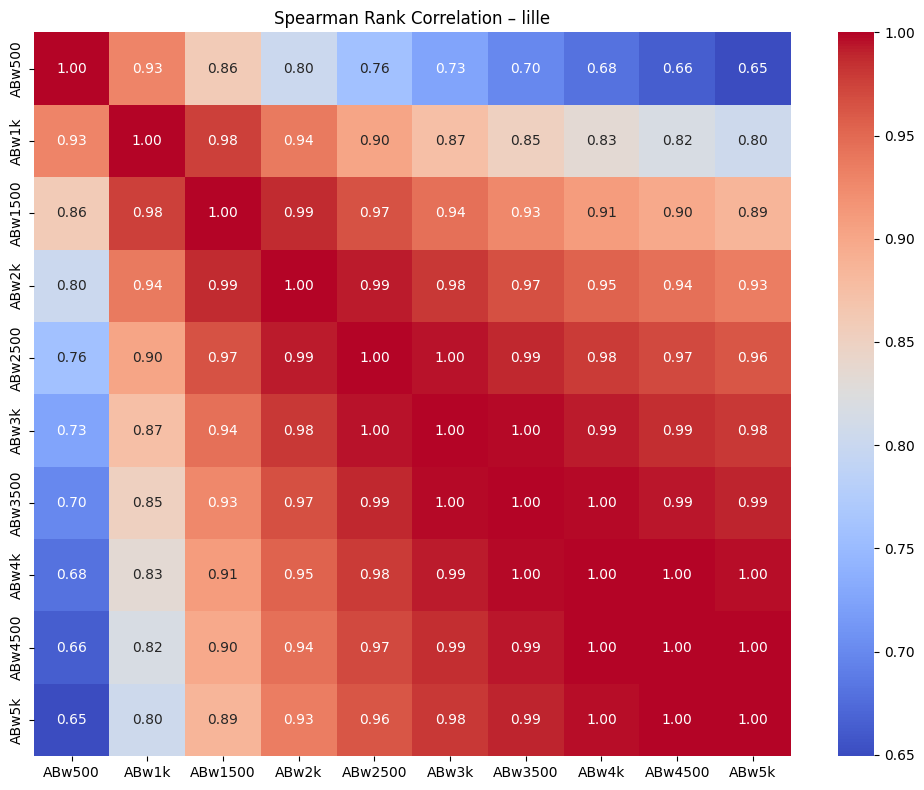

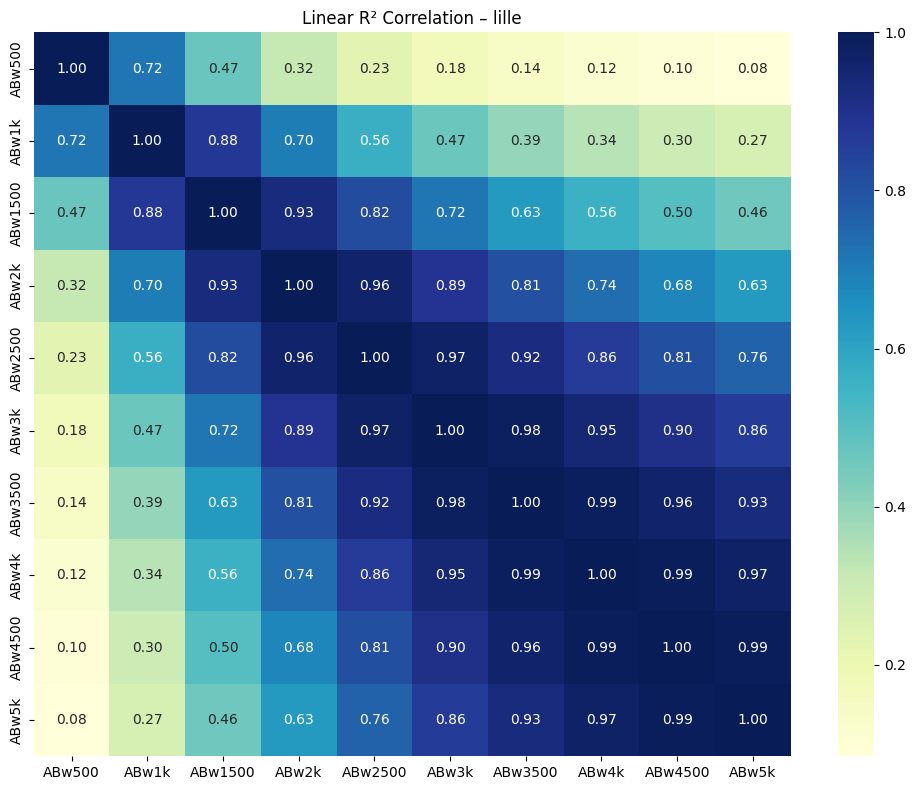


Raw correlation matrices:

Spearman Correlation Matrix for lille:


,ABw500,ABw1k,ABw1500,ABw2k,ABw2500,ABw3k,ABw3500,ABw4k,ABw4500,ABw5k
ABw500,1.000000,0.930050,0.859157,0.801887,0.757528,0.725122,0.699913,0.679613,0.663006,0.649258
ABw1k,0.930050,1.000000,0.975545,0.937729,0.902472,0.874395,0.851705,0.832955,0.817348,0.804207
ABw1500,0.859157,0.975545,1.000000,0.987372,0.965318,0.944465,0.926403,0.910876,0.897593,0.886113
ABw2k,0.801887,0.937729,0.987372,1.000000,0.992764,0.979998,0.966869,0.954710,0.943876,0.934253
ABw2500,0.757528,0.902472,0.965318,0.992764,1.000000,0.995824,0.987824,0.979049,0.970633,0.962853
ABw3k,0.725122,0.874395,0.944465,0.979998,0.995824,1.000000,0.997301,0.991897,0.985788,0.979714
ABw3500,0.699913,0.851705,0.926403,0.966869,0.987824,0.997301,1.000000,0.998156,0.994402,0.989986
ABw4k,0.679613,0.832955,0.910876,0.954710,0.979049,0.991897,0.998156,1.000000,0.998693,0.995938
ABw4500,0.663006,0.817348,0.897593,0.943876,0.970633,0.985788,0.994402,0.998693,1.000000,0.999023
ABw5k,0.649258,0.804207,0.886113,0.934253,0.962853,0.979714,0.989986,0.995938,0.999023,1.000000



R2 Correlation Matrix for lille:


,ABw500,ABw1k,ABw1500,ABw2k,ABw2500,ABw3k,ABw3500,ABw4k,ABw4500,ABw5k
ABw500,1.000000,0.716424,0.467693,0.315278,0.228845,0.175649,0.139978,0.115411,0.097756,0.084380
ABw1k,0.716424,1.000000,0.875625,0.699670,0.564098,0.465458,0.392487,0.338991,0.298670,0.266888
ABw1500,0.467693,0.875625,1.000000,0.931989,0.820316,0.715922,0.628135,0.558494,0.503467,0.458758
ABw2k,0.315278,0.699670,0.931989,1.000000,0.961193,0.886297,0.807441,0.737364,0.678463,0.628675
ABw2500,0.228845,0.564098,0.820316,0.961193,1.000000,0.974575,0.921837,0.864282,0.810755,0.762513
ABw3k,0.175649,0.465458,0.715922,0.886297,0.974575,1.000000,0.982769,0.946335,0.904803,0.863006
ABw3500,0.139978,0.392487,0.628135,0.807441,0.921837,0.982769,1.000000,0.988279,0.962585,0.930706
ABw4k,0.115411,0.338991,0.558494,0.737364,0.864282,0.946335,0.988279,1.000000,0.991694,0.971881
ABw4500,0.097756,0.298670,0.503467,0.678463,0.810755,0.904803,0.962585,0.991694,1.000000,0.993507
ABw5k,0.084380,0.266888,0.458758,0.628675,0.762513,0.863006,0.930706,0.971881,0.993507,1.000000



Processing versilia...


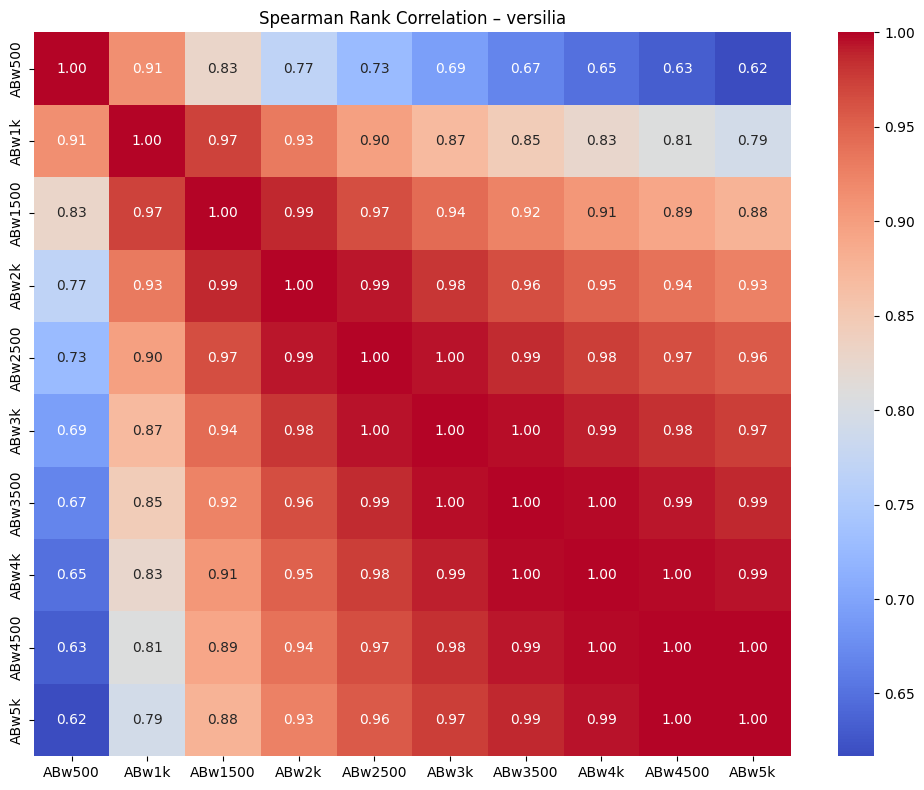

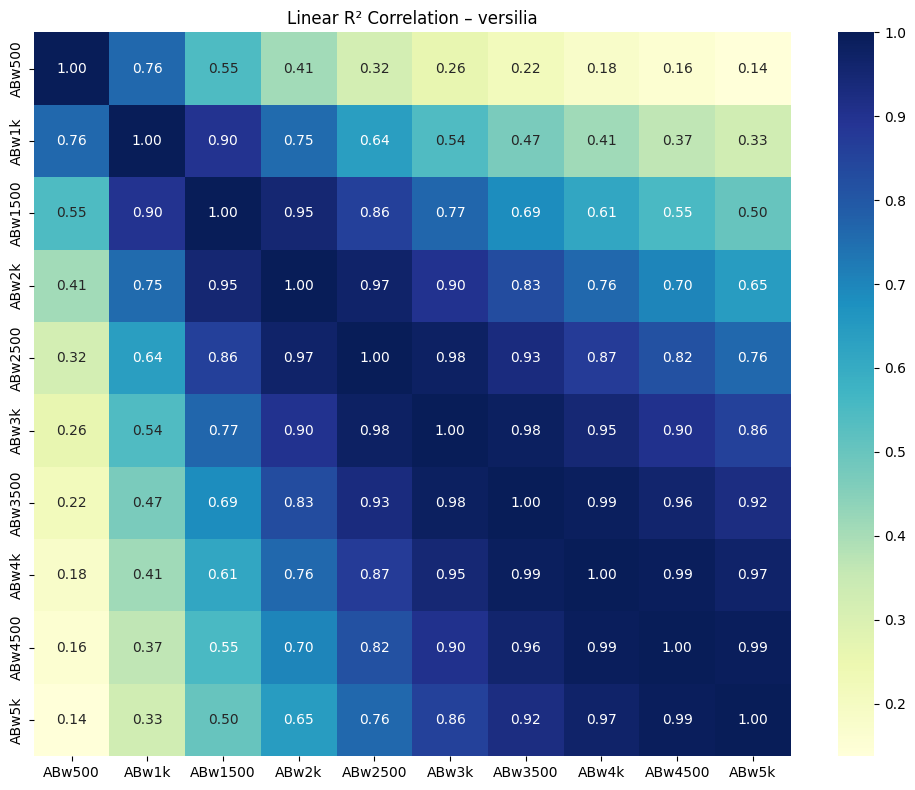


Raw correlation matrices:

Spearman Correlation Matrix for versilia:


,ABw500,ABw1k,ABw1500,ABw2k,ABw2500,ABw3k,ABw3500,ABw4k,ABw4500,ABw5k
ABw500,1.000000,0.914125,0.829201,0.769160,0.726613,0.694430,0.669108,0.649348,0.632019,0.616750
ABw1k,0.914125,1.000000,0.971609,0.931930,0.897652,0.869221,0.845136,0.825426,0.808005,0.792505
ABw1500,0.829201,0.971609,1.000000,0.986940,0.965232,0.943887,0.923987,0.906825,0.891413,0.877477
ABw2k,0.769160,0.931930,0.986940,1.000000,0.992703,0.979344,0.964565,0.950681,0.937733,0.925779
ABw2500,0.726613,0.897652,0.965232,0.992703,1.000000,0.995452,0.986170,0.975846,0.965525,0.955664
ABw3k,0.694430,0.869221,0.943887,0.979344,0.995452,1.000000,0.996811,0.990294,0.982706,0.974908
ABw3500,0.669108,0.845136,0.923987,0.964565,0.986170,0.996811,1.000000,0.997743,0.993060,0.987354
ABw4k,0.649348,0.825426,0.906825,0.950681,0.975846,0.990294,0.997743,1.000000,0.998354,0.994788
ABw4500,0.632019,0.808005,0.891413,0.937733,0.965525,0.982706,0.993060,0.998354,1.000000,0.998741
ABw5k,0.616750,0.792505,0.877477,0.925779,0.955664,0.974908,0.987354,0.994788,0.998741,1.000000



R2 Correlation Matrix for versilia:


,ABw500,ABw1k,ABw1500,ABw2k,ABw2500,ABw3k,ABw3500,ABw4k,ABw4500,ABw5k
ABw500,1.000000,0.760766,0.545638,0.409882,0.322083,0.260886,0.217270,0.183637,0.157506,0.137141
ABw1k,0.760766,1.000000,0.896172,0.754931,0.636630,0.543073,0.470744,0.412553,0.365211,0.326583
ABw1500,0.545638,0.896172,1.000000,0.951139,0.860073,0.766372,0.685189,0.614973,0.554988,0.503980
ABw2k,0.409882,0.754931,0.951139,1.000000,0.968086,0.901849,0.831248,0.763128,0.700972,0.645525
ABw2500,0.322083,0.636630,0.860073,0.968086,1.000000,0.977080,0.929944,0.874049,0.817517,0.763416
ABw3k,0.260886,0.543073,0.766372,0.901849,0.977080,1.000000,0.984538,0.948863,0.904494,0.857124
ABw3500,0.217270,0.470744,0.685189,0.831248,0.929944,0.984538,1.000000,0.988208,0.960497,0.924141
ABw4k,0.183637,0.412553,0.614973,0.763128,0.874049,0.948863,0.988208,1.000000,0.990963,0.968163
ABw4500,0.157506,0.365211,0.554988,0.700972,0.817517,0.904494,0.960497,0.990963,1.000000,0.992291
ABw5k,0.137141,0.326583,0.503980,0.645525,0.763416,0.857124,0.924141,0.968163,0.992291,1.000000


In [22]:
radius_columns_AB = [
    "ABw500", "ABw1k", "ABw1500", "ABw2k", "ABw2500",
    "ABw3k", "ABw3500", "ABw4k", "ABw4500", "ABw5k"
]

analyze_cities_correlation(city_data, cities, radius_columns_AB)


### 1.2) HexbinPlots to observe the actual distribution


Hexbin plot for nice – ABw1k vs ABw5k


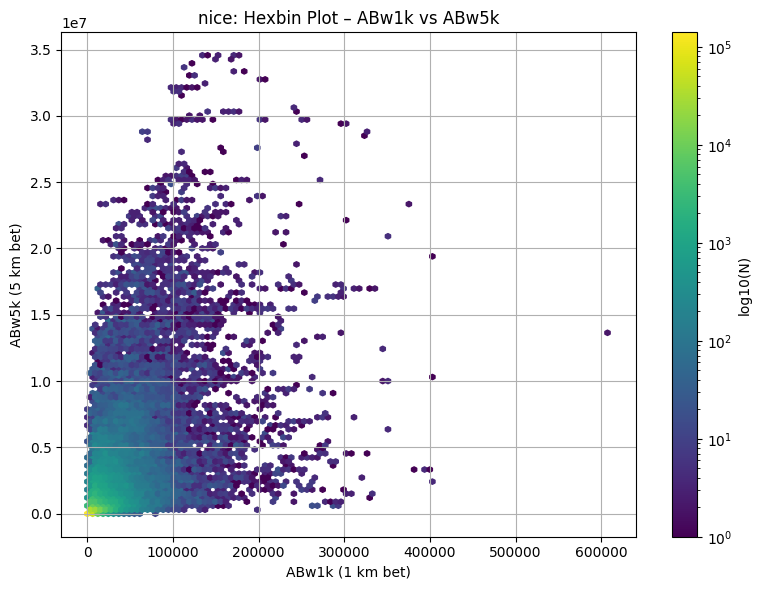


Hexbin plot for vienna – ABw1k vs ABw5k


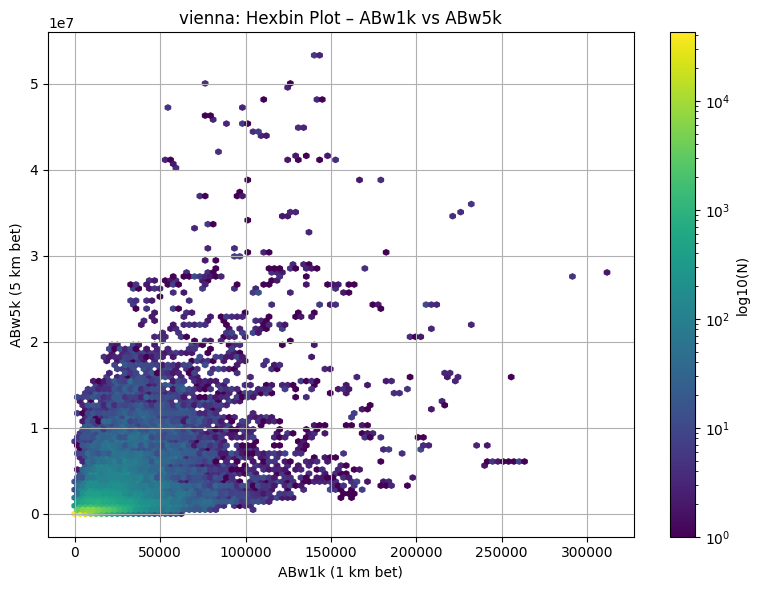


Hexbin plot for gothenburg – ABw1k vs ABw5k


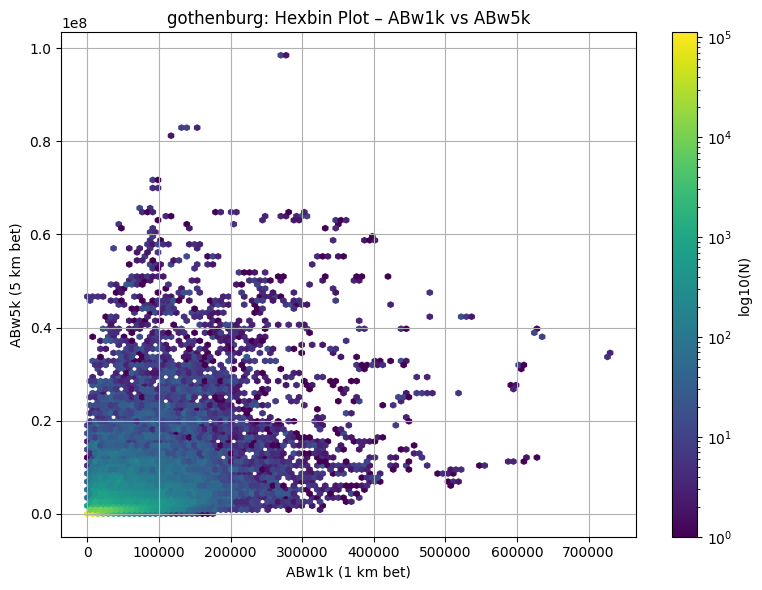


Hexbin plot for lille – ABw1k vs ABw5k


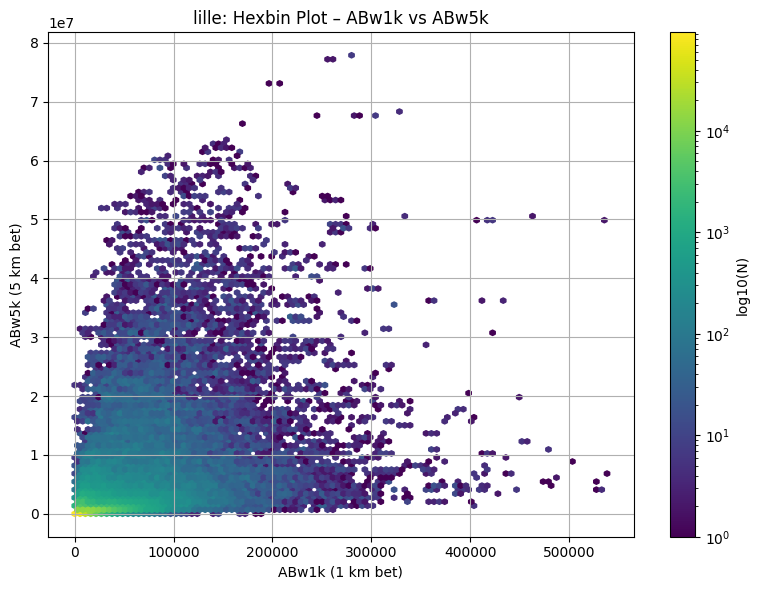


Hexbin plot for versilia – ABw1k vs ABw5k


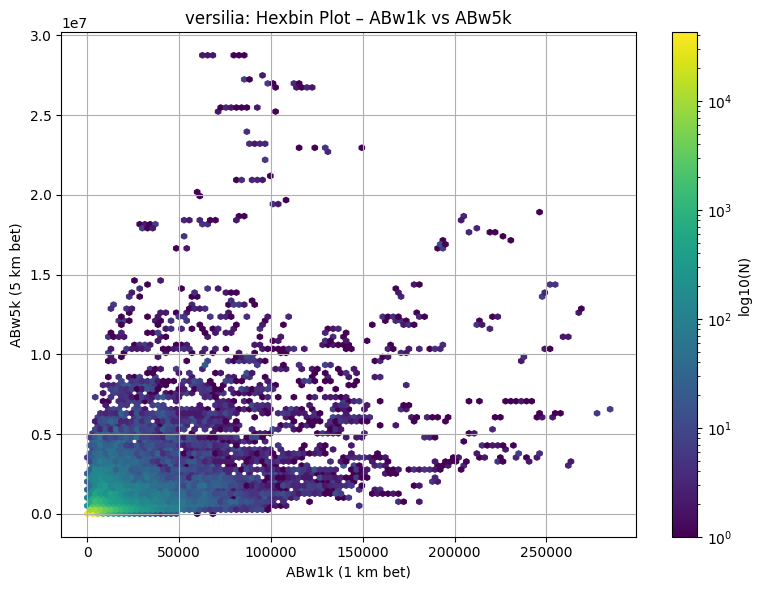

In [24]:
#Betwennesses


for city in cities:
    print(f"\nHexbin plot for {city} – ABw1k vs ABw5k")
    gdf = city_data[city]  # use preloaded data
    df = gdf[["ABw1k", "ABw5k"]].dropna()

    plt.figure(figsize=(8, 6))
    plt.hexbin(df["ABw1k"], df["ABw5k"], gridsize=100, cmap='viridis', bins='log')
    plt.colorbar(label='log10(N)')
    plt.xlabel("ABw1k (1 km bet)")
    plt.ylabel("ABw5k (5 km bet)")
    plt.title(f"{city}: Hexbin Plot – ABw1k vs ABw5k")
    plt.grid(True)
    plt.tight_layout()
    plt.show()



Scatterplot for nice – ACw1kC vs ACw5kC


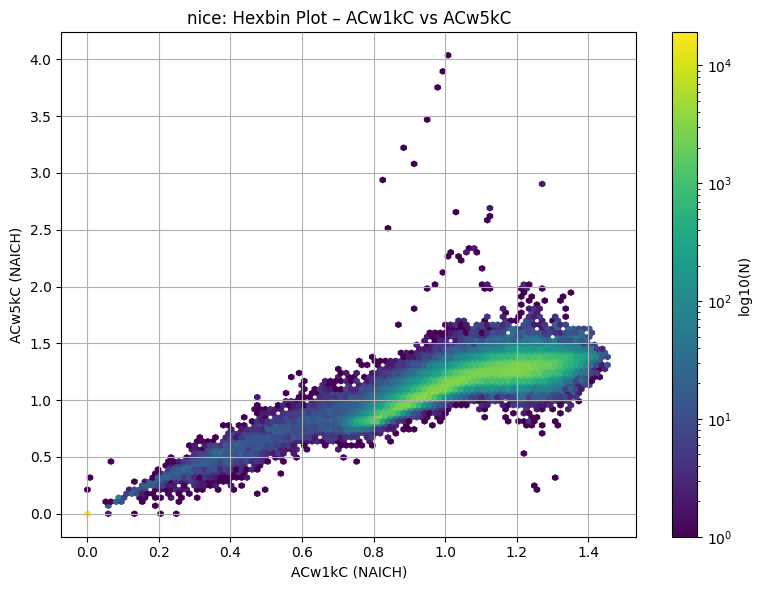


Scatterplot for vienna – ACw1kC vs ACw5kC


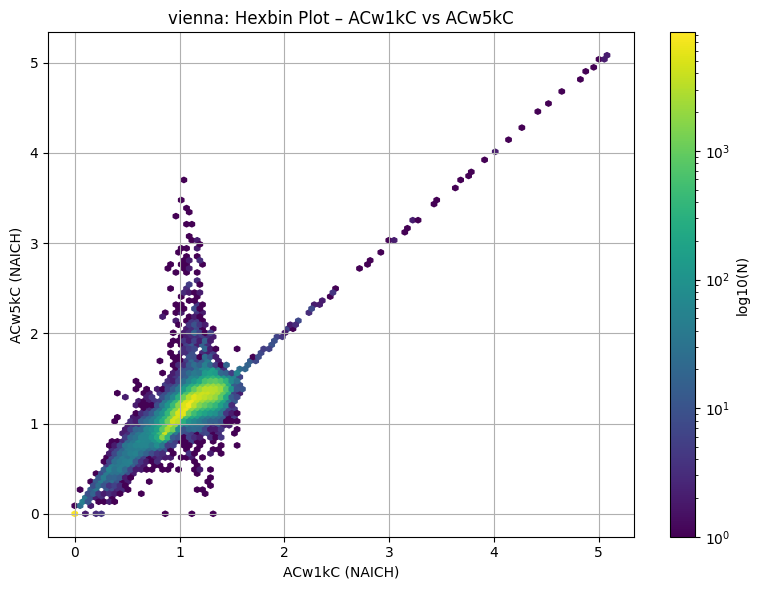


Scatterplot for gothenburg – ACw1kC vs ACw5kC


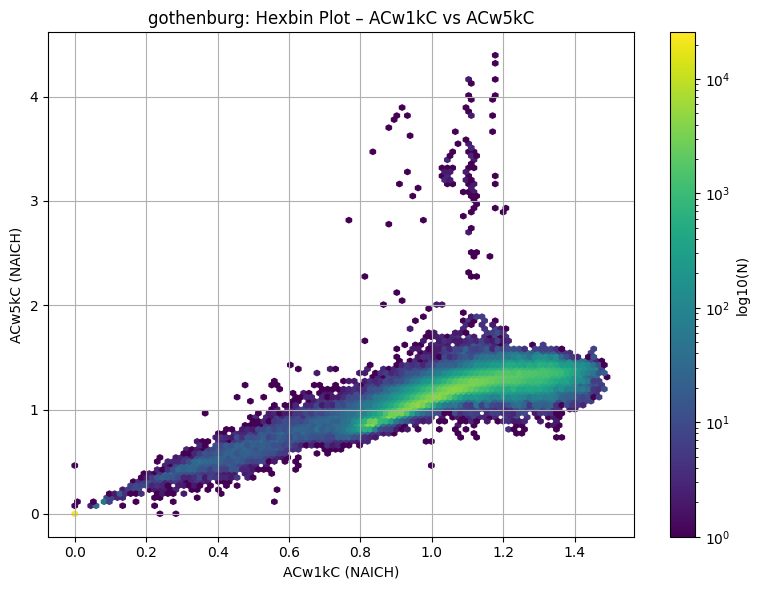


Scatterplot for lille – ACw1kC vs ACw5kC


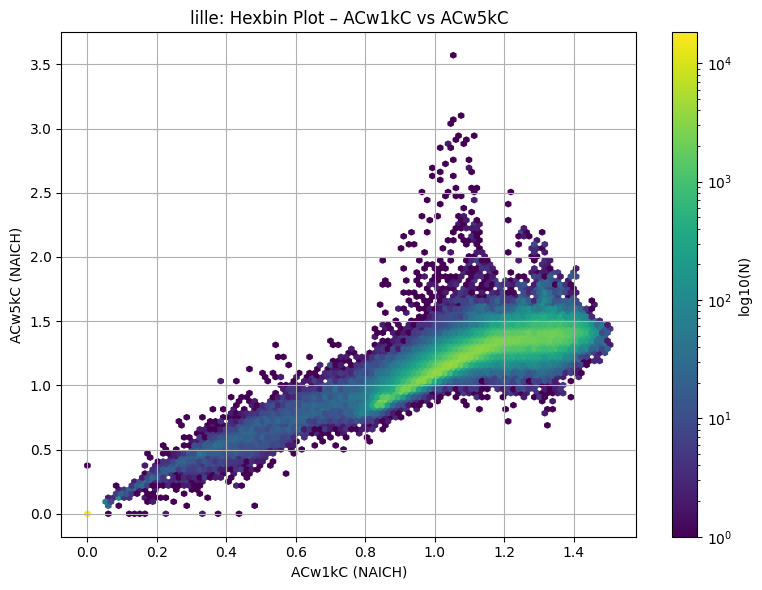


Scatterplot for versilia – ACw1kC vs ACw5kC


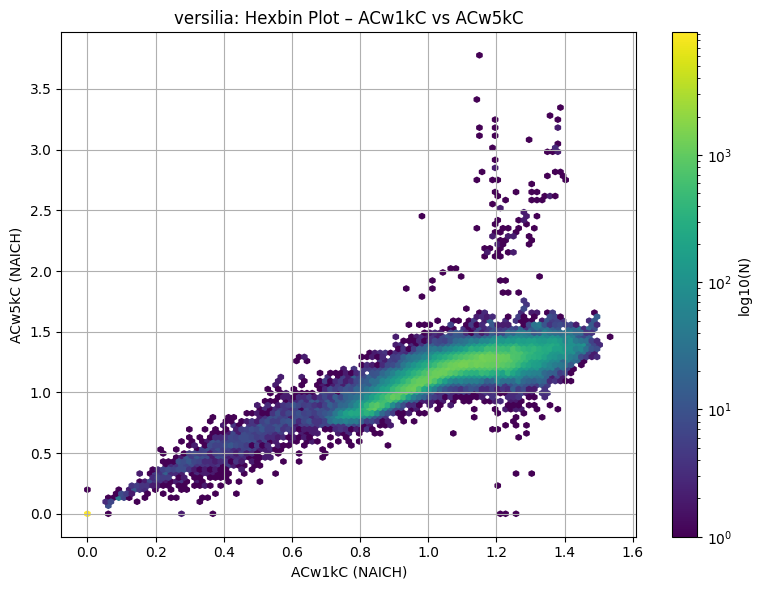

In [26]:
#NAICH   <<<--------- Here you can notice the problems with Vienna 

for city in cities:
    a="ACw1kC"
    b="ACw5kC"
    print(f"\nScatterplot for {city} – ACw1kC vs ACw5kC")
    gdf = city_data[city]  # use preloaded data
    df = gdf[[a, b]].dropna()

    plt.figure(figsize=(8, 6))
    plt.hexbin(df[b], df[a], gridsize=100, cmap='viridis', bins='log')
    plt.colorbar(label='log10(N)')
    plt.xlabel(str(a)+" (NAICH)")
    plt.ylabel(str(b)+" (NAICH)")
    plt.title(f"{city}: Hexbin Plot – "+str(a)+" vs "+str(b))
    plt.grid(True)
    plt.tight_layout()
    plt.show()


### 1.3) PIRAMIDS OF HexbinPlots : assessing the homoteticity at different metropolitan scales


Plotting pyramid for nice


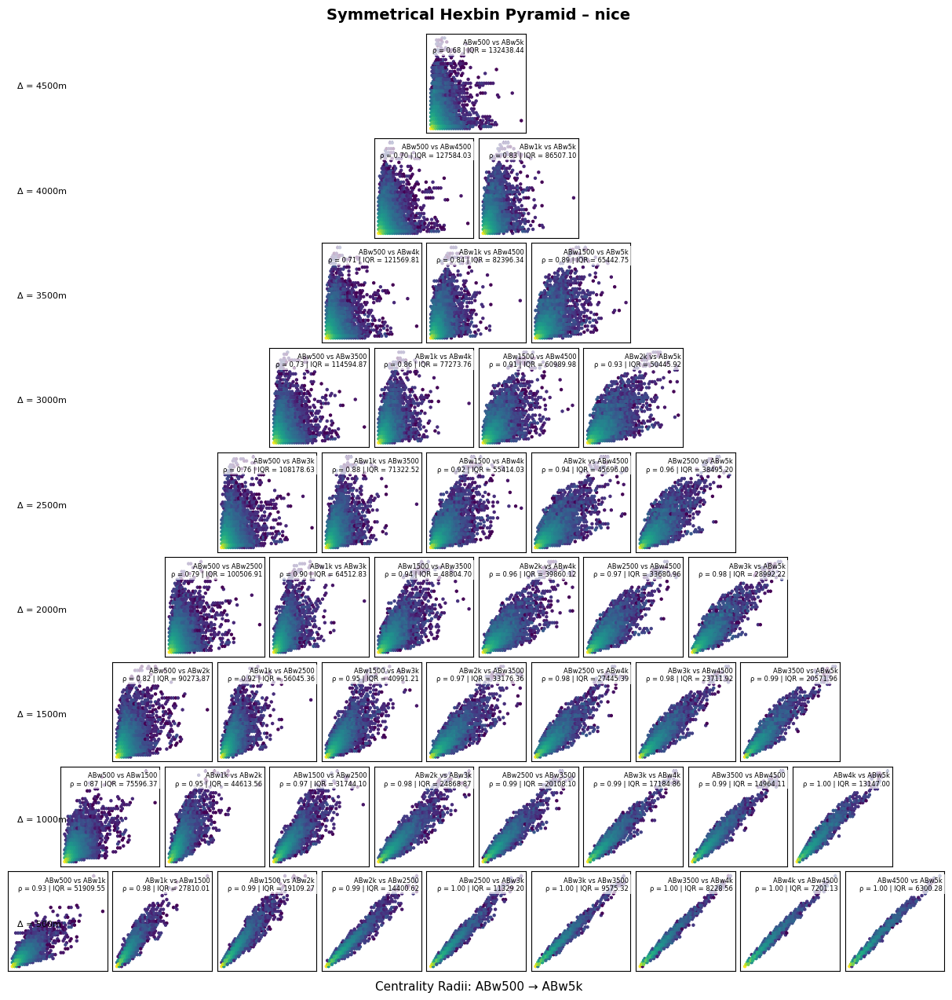


Plotting pyramid for vienna


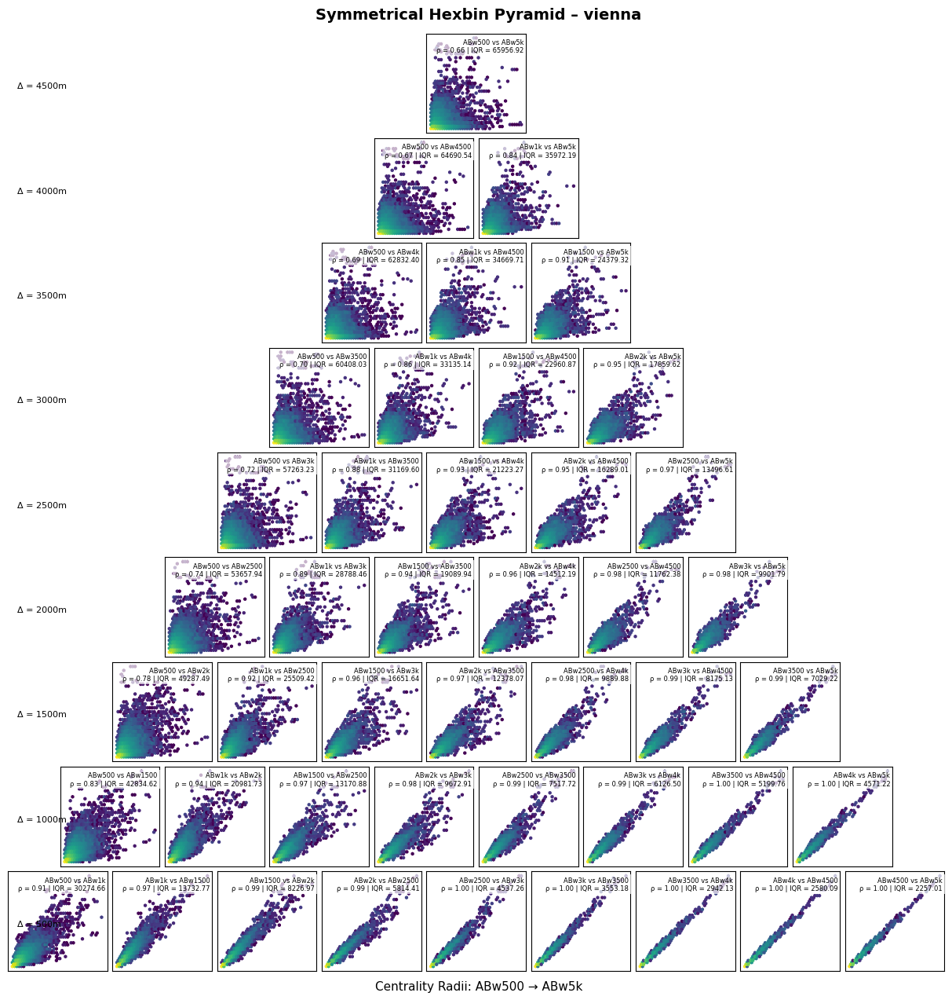


Plotting pyramid for gothenburg


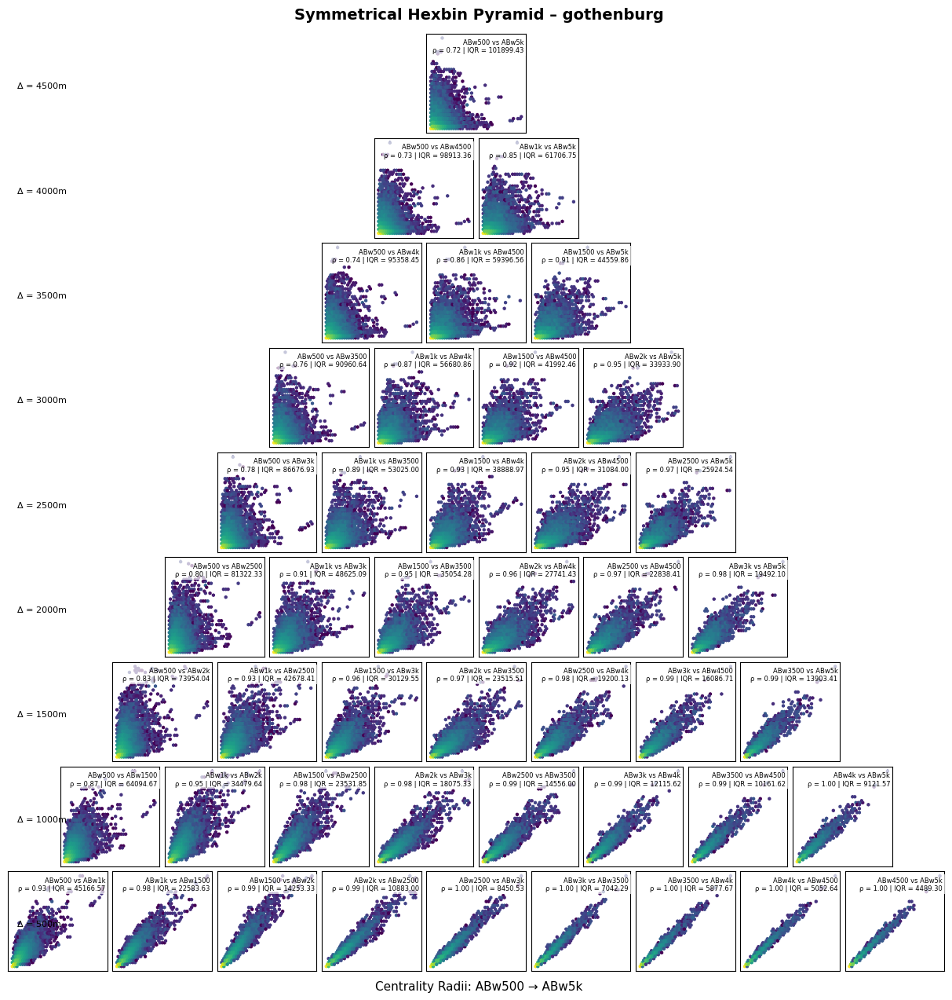


Plotting pyramid for lille


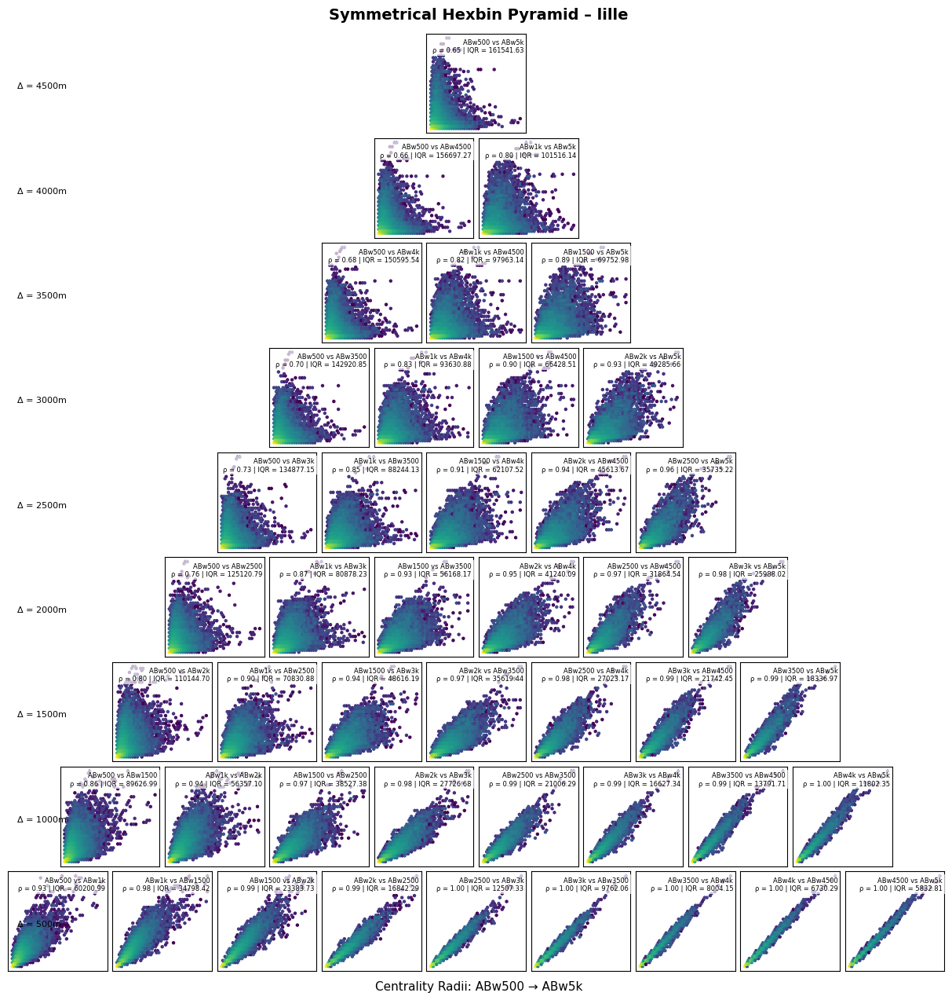


Plotting pyramid for versilia


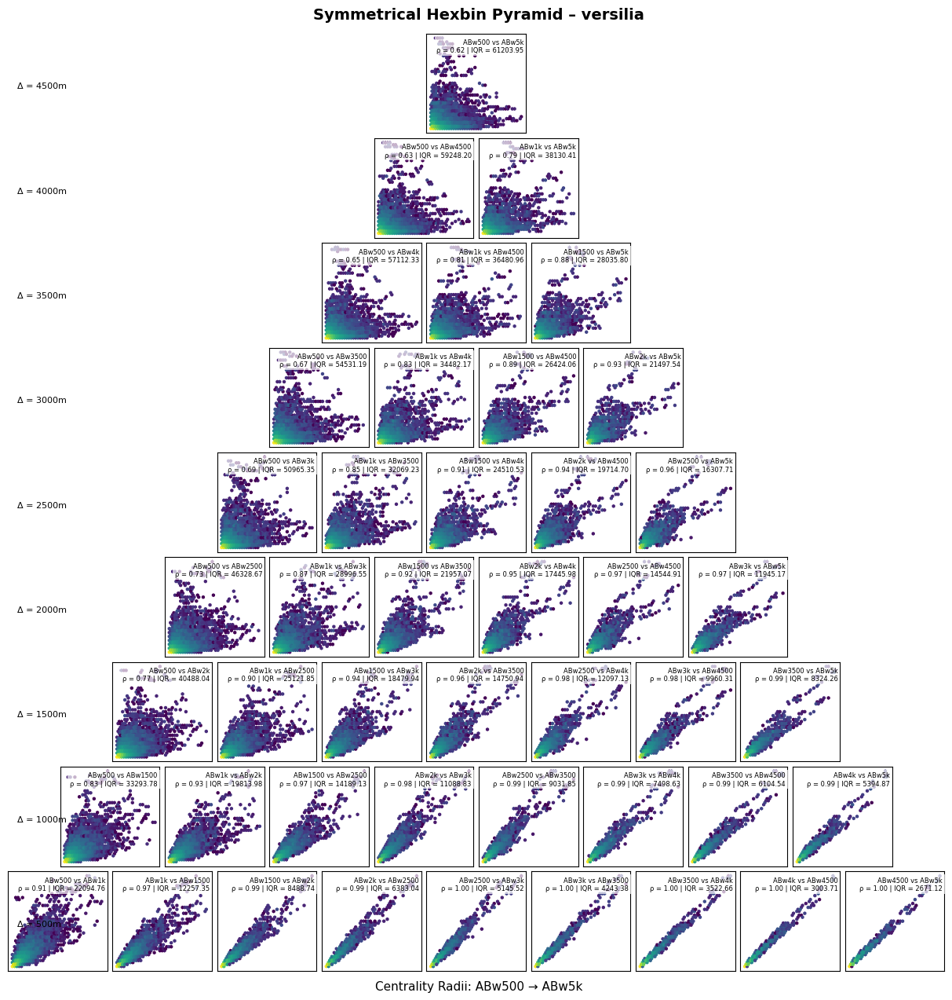

In [28]:


# Define radius columns and mapping
radius_columns = [
    "ABw500", "ABw1k", "ABw1500", "ABw2k", "ABw2500",
    "ABw3k", "ABw3500", "ABw4k", "ABw4500", "ABw5k"
]
radius_values = {
    "ABw500": 500, "ABw1k": 1000, "ABw1500": 1500, "ABw2k": 2000, "ABw2500": 2500,
    "ABw3k": 3000, "ABw3500": 3500, "ABw4k": 4000, "ABw4500": 4500, "ABw5k": 5000
}

# Generate pairings grouped by gap
pair_groups = {}
for col1, col2 in itertools.combinations(radius_columns, 2):
    gap = abs(radius_values[col1] - radius_values[col2])
    pair_groups.setdefault(gap, []).append((col1, col2))

sorted_gaps = sorted(pair_groups.keys(), reverse=True)
max_plots = max(len(pairs) for pairs in pair_groups.values())
n_rows = len(sorted_gaps)

# Plot each city
for city in cities:
    print(f"\nPlotting pyramid for {city}")
    df = city_data[city][radius_columns].dropna()

    plot_size = 1.0 / max_plots
    fig_height = plot_size * n_rows * 1.05
    fig = plt.figure(figsize=(12, 12))  # Square output

    for row_idx, gap in enumerate(sorted_gaps):
        pairs = pair_groups[gap]
        n = len(pairs)
        row_bottom = 1 - ((row_idx + 1) * plot_size)

        for i, (col1, col2) in enumerate(pairs):
            # Compute centered position
            total_plot_width = n * plot_size
            left = (1 - total_plot_width) / 2 + i * plot_size

            ax = fig.add_axes([left, row_bottom, plot_size * 0.95, plot_size * 0.95])  # square plot
            ax.hexbin(df[col1], df[col2], gridsize=40, cmap='viridis', bins='log')
            ax.set_xticks([])
            ax.set_yticks([])

            # Compute Spearman correlation
            rho, _ = spearmanr(df[col1], df[col2])

            # Compute dispersion as IQR of residuals on ranked data
            x_ranked = df[col1].rank().values
            y_ranked = df[col2].rank().values
            coeffs = np.polyfit(x_ranked, y_ranked, deg=1)
            predicted = np.polyval(coeffs, x_ranked)
            residuals = y_ranked - predicted
            q75, q25 = np.percentile(residuals, [75, 25])
            dispersion = q75 - q25  # IQR

            # Internal annotation
            ax.text(0.98, 0.95,
                    f"{col1} vs {col2}\nρ = {rho:.2f} | IQR = {dispersion:.2f}",
                    fontsize=6, ha='right', va='top',
                    transform=ax.transAxes,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2))

        # Gap value label on Y
        fig.text(0.01, row_bottom + plot_size * 0.45, f"Δ = {gap}m", va='center', fontsize=8)

    # Global title and axis info
    fig.text(0.5, 1.01, f"Symmetrical Hexbin Pyramid – {city}", ha='center', fontsize=14, weight='bold')
    fig.text(0.5, -0.02, "Centrality Radii: ABw500 → ABw5k", ha='center', fontsize=11)

    plt.show()



Plotting pyramid for nice


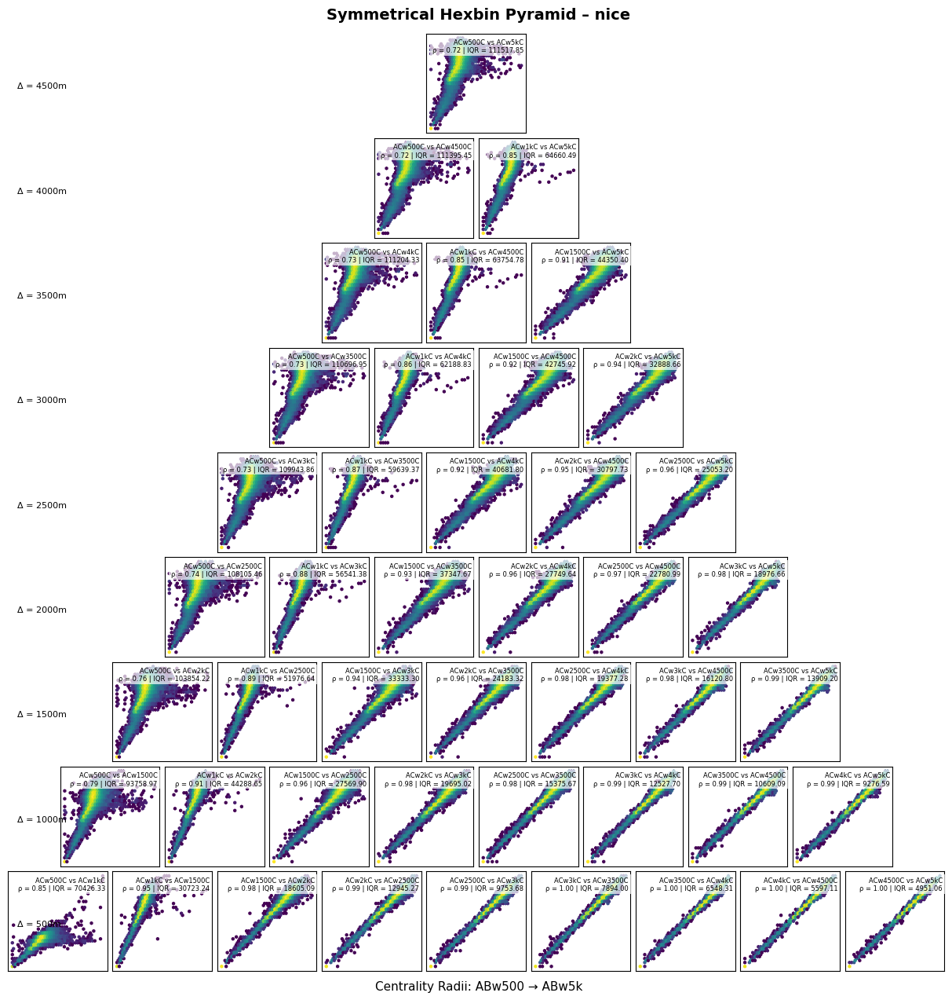


Plotting pyramid for vienna


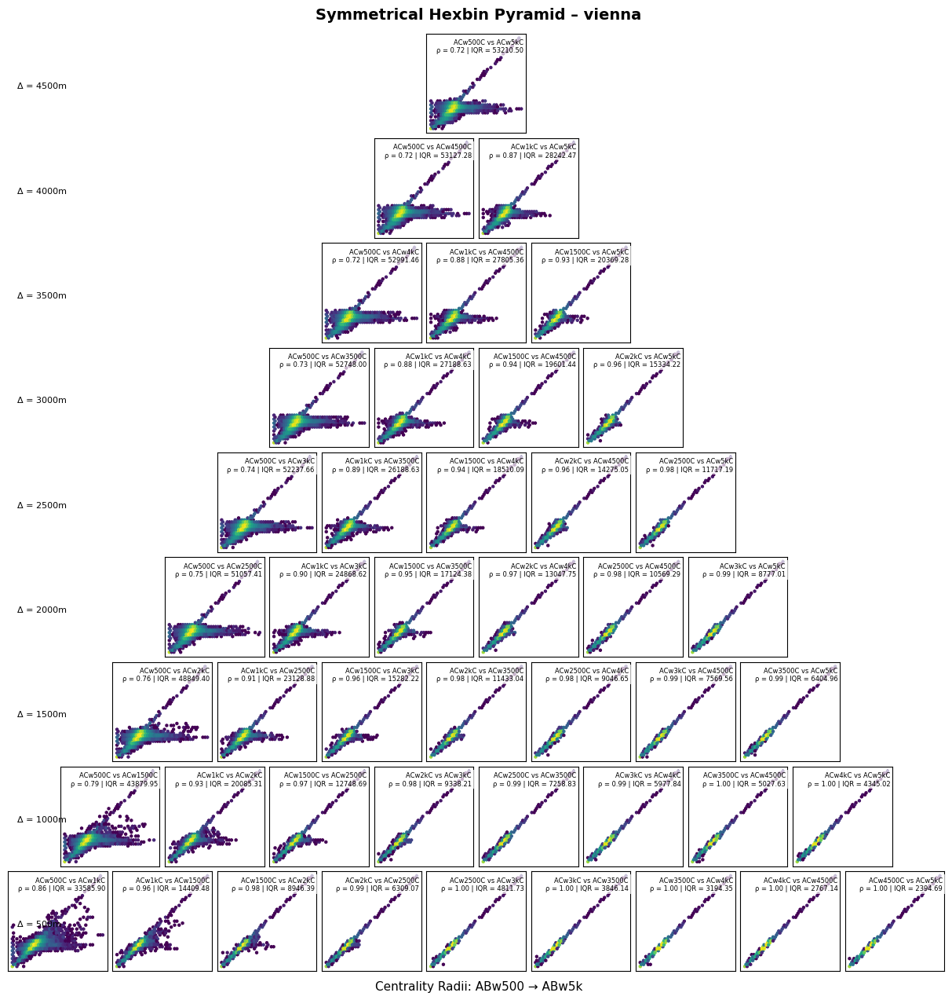


Plotting pyramid for gothenburg


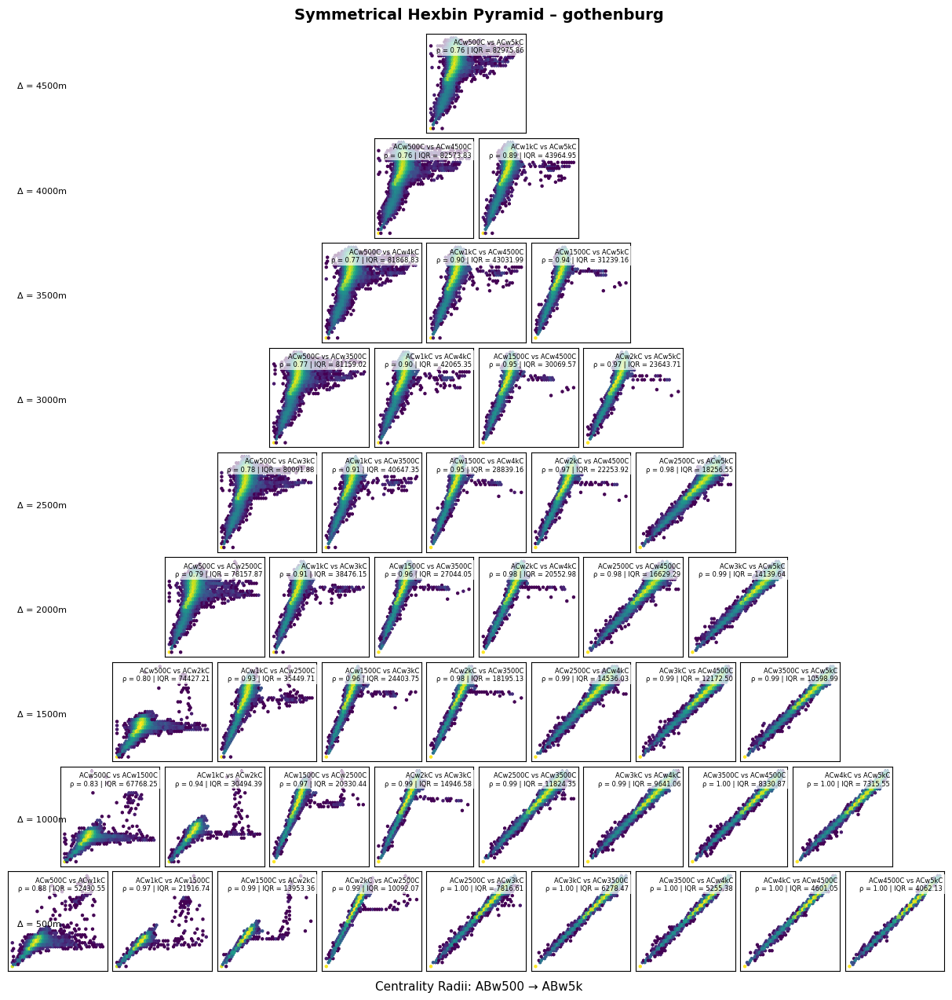


Plotting pyramid for lille


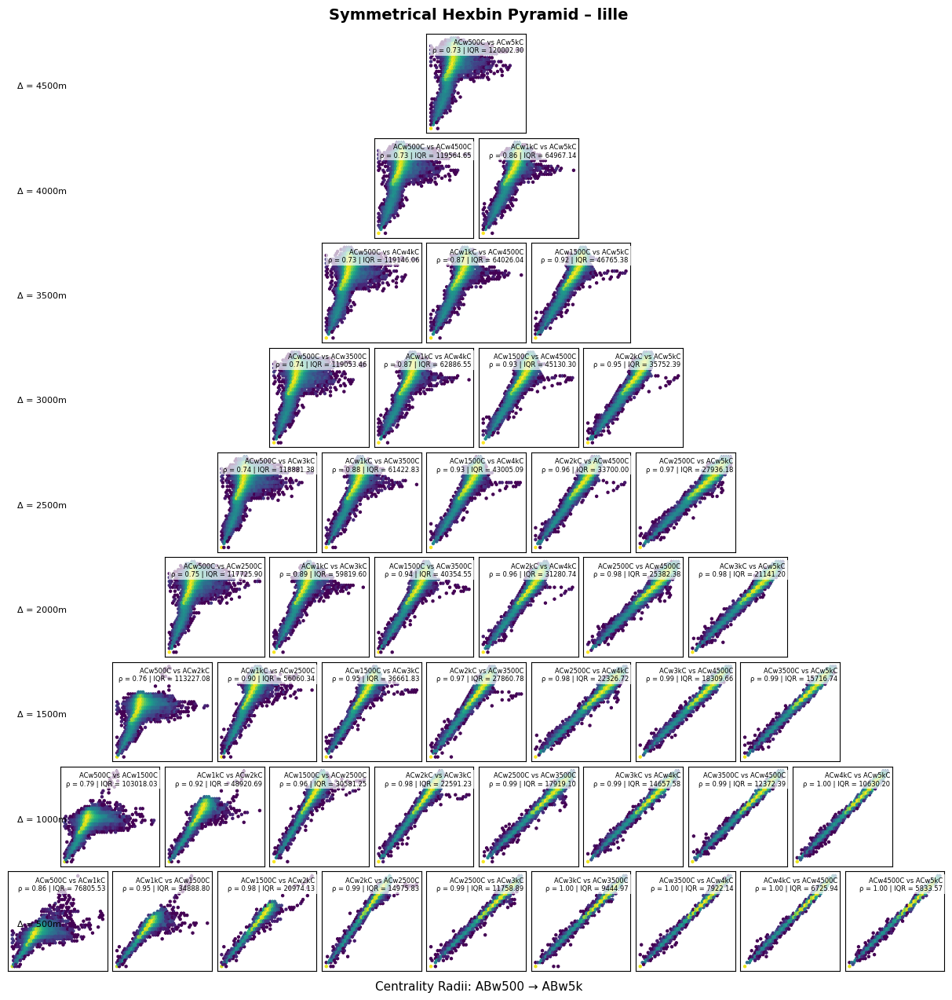


Plotting pyramid for versilia


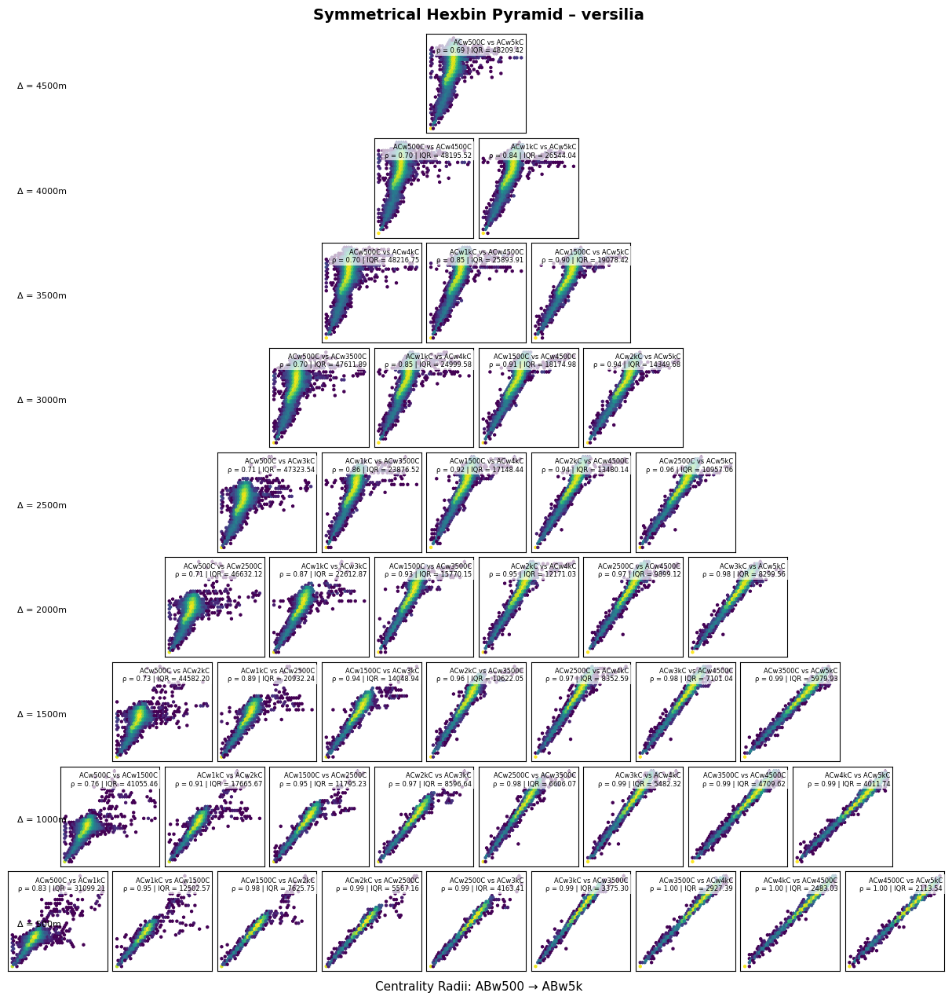

In [58]:

# Define radius columns and mapping
radius_columns = [
    "ACw500C", "ACw1kC", "ACw1500C", "ACw2kC", "ACw2500C",
    "ACw3kC", "ACw3500C", "ACw4kC", "ACw4500C", "ACw5kC"
]
radius_values = {
    "ACw500C": 500, "ACw1kC": 1000, "ACw1500C": 1500, "ACw2kC": 2000, "ACw2500C": 2500,
    "ACw3kC": 3000, "ACw3500C": 3500, "ACw4kC": 4000, "ACw4500C": 4500, "ACw5kC": 5000
}

# Generate pairings grouped by gap
pair_groups = {}
for col1, col2 in itertools.combinations(radius_columns, 2):
    gap = abs(radius_values[col1] - radius_values[col2])
    pair_groups.setdefault(gap, []).append((col1, col2))

sorted_gaps = sorted(pair_groups.keys(), reverse=True)
max_plots = max(len(pairs) for pairs in pair_groups.values())
n_rows = len(sorted_gaps)

# Plot each city
for city in cities:
    print(f"\nPlotting pyramid for {city}")
    df = city_data[city][radius_columns].dropna()

    plot_size = 1.0 / max_plots
    fig_height = plot_size * n_rows * 1.05
    fig = plt.figure(figsize=(12, 12))  # Square output

    for row_idx, gap in enumerate(sorted_gaps):
        pairs = pair_groups[gap]
        n = len(pairs)
        row_bottom = 1 - ((row_idx + 1) * plot_size)

        for i, (col1, col2) in enumerate(pairs):
            # Compute centered position
            total_plot_width = n * plot_size
            left = (1 - total_plot_width) / 2 + i * plot_size

            ax = fig.add_axes([left, row_bottom, plot_size * 0.95, plot_size * 0.95])  # square plot
            ax.hexbin(df[col1], df[col2], gridsize=40, cmap='viridis', bins='log')
            ax.set_xticks([])
            ax.set_yticks([])

            # Compute Spearman correlation
            rho, _ = spearmanr(df[col1], df[col2])

            # Compute dispersion as IQR of residuals on ranked data
            x_ranked = df[col1].rank().values
            y_ranked = df[col2].rank().values
            coeffs = np.polyfit(x_ranked, y_ranked, deg=1)
            predicted = np.polyval(coeffs, x_ranked)
            residuals = y_ranked - predicted
            q75, q25 = np.percentile(residuals, [75, 25])
            dispersion = q75 - q25  # IQR

            # Internal annotation
            ax.text(0.98, 0.95,
                    f"{col1} vs {col2}\nρ = {rho:.2f} | IQR = {dispersion:.2f}",
                    fontsize=6, ha='right', va='top',
                    transform=ax.transAxes,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2))

        # Gap value label on Y
        fig.text(0.01, row_bottom + plot_size * 0.45, f"Δ = {gap}m", va='center', fontsize=8)

    # Global title and axis info
    fig.text(0.5, 1.01, f"Symmetrical Hexbin Pyramid – {city}", ha='center', fontsize=14, weight='bold')
    fig.text(0.5, -0.02, "Centrality Radii: ABw500 → ABw5k", ha='center', fontsize=11)

    plt.show()


In [29]:
# Create a dictionary to store results for each city
results = {}

for city in cities:
    print(f"\nAnalyzing {city}")
    df = city_data[city][radius_columns].dropna()

    city_results = []

    for gap in sorted_gaps:
        for col1, col2 in pair_groups[gap]:
            # Compute Spearman correlation
            rho, _ = spearmanr(df[col1], df[col2])

            # Compute IQR of residuals on ranked data
            x_ranked = df[col1].rank().values
            y_ranked = df[col2].rank().values
            coeffs = np.polyfit(x_ranked, y_ranked, deg=1)
            predicted = np.polyval(coeffs, x_ranked)
            residuals = y_ranked - predicted
            q75, q25 = np.percentile(residuals, [75, 25])
            iqr = q75 - q25

            # Store results
            city_results.append({
                "Gap (m)": gap,
                "From": col1,
                "To": col2,
                "Spearman ρ": round(rho, 4),
                "IQR": round(iqr, 4)
            })

    # Convert to DataFrame and store
    results[city] = pd.DataFrame(city_results)
    print(results[city])



Analyzing nice
    Gap (m)     From       To  Spearman ρ          IQR
0      4500   ABw500    ABw5k      0.6824  132438.4443
1      4000   ABw500  ABw4500      0.6968  127584.0325
2      4000    ABw1k    ABw5k      0.8265   86507.0964
3      3500   ABw500    ABw4k      0.7138  121569.8124
4      3500    ABw1k  ABw4500      0.8408   82396.3413
5      3500  ABw1500    ABw5k      0.8934   65442.7456
6      3000   ABw500  ABw3500      0.7335  114594.8671
7      3000    ABw1k    ABw4k      0.8572   77273.7578
8      3000  ABw1500  ABw4500      0.9065   60989.9846
9      3000    ABw2k    ABw5k      0.9334   50445.9181
10     2500   ABw500    ABw3k      0.7572  108178.6298
11     2500    ABw1k  ABw3500      0.8758   71322.5217
12     2500  ABw1500    ABw4k      0.9211   55414.0333
13     2500    ABw2k  ABw4500      0.9448   45696.0050
14     2500  ABw2500    ABw5k      0.9594   38495.2001
15     2000   ABw500  ABw2500      0.7856  100506.9078
16     2000    ABw1k    ABw3k      0.8973   64512

    Gap (m)     From       To  Spearman ρ         IQR
0      4500   ABw500    ABw5k      0.6167  61203.9476
1      4000   ABw500  ABw4500      0.6320  59248.1967
2      4000    ABw1k    ABw5k      0.7925  38130.4100
3      3500   ABw500    ABw4k      0.6493  57112.3294
4      3500    ABw1k  ABw4500      0.8080  36480.9649
5      3500  ABw1500    ABw5k      0.8775  28035.7972
6      3000   ABw500  ABw3500      0.6691  54531.1885
7      3000    ABw1k    ABw4k      0.8254  34482.1662
8      3000  ABw1500  ABw4500      0.8914  26424.0641
9      3000    ABw2k    ABw5k      0.9258  21497.5363
10     2500   ABw500    ABw3k      0.6944  50965.3478
11     2500    ABw1k  ABw3500      0.8451  32069.2275
12     2500  ABw1500    ABw4k      0.9068  24510.5250
13     2500    ABw2k  ABw4500      0.9377  19714.7009
14     2500  ABw2500    ABw5k      0.9557  16307.7080
15     2000   ABw500  ABw2500      0.7266  46328.6742
16     2000    ABw1k    ABw3k      0.8692  28996.5537
17     2000  ABw1500  ABw350

### 1.4) QUANTIFYING THE overlap of the top 10% quantile streets across radii


In [99]:

# Define the columns
radius_columns = [ "ACw4kC", "ACw4500C", "ACw5kC"
]

def analyze_top10_consistency(city_name, df):
    print(f"--- {city_name} ---")
    
    # Step 1: Compute deciles (1 to 10, where 10 = top 10%)
    deciles = pd.DataFrame(index=df.index)
    for col in radius_columns:
        deciles[col] = pd.qcut(df[col], 10, labels=False, duplicates='drop') + 1  # 1-based labels

    # Step 2: Boolean DataFrame where True = in top 10%
    top10_df = deciles == 10

    # Step 3: Segments that are in top 10% for ALL radii
    always_top10_mask = top10_df.all(axis=1)
    num_always_top10 = always_top10_mask.sum()
    total_segments = len(df)
    percent_always_top10 = 100 * num_always_top10 / total_segments

    print(f"Segments always in top 10% across all radii: {num_always_top10} ({percent_always_top10:.2f}%)")

    # Step 4: For each radius, compute % of top 10% segments that belong to the 'always top 10%' group
    overlap_stats = {}

    for col in radius_columns:
        top10_at_radius = top10_df[col]
        overlap = top10_at_radius & always_top10_mask
        overlap_ratio = 100 * overlap.sum() / top10_at_radius.sum()
        overlap_stats[col] = overlap_ratio
        print(f"{col}: {overlap.sum()} overlap out of {top10_at_radius.sum()} top-10 → {overlap_ratio:.2f}%")

    return always_top10_mask, overlap_stats
results = {}
for city, df in city_data.items():
    always_top10_mask, overlap_stats = analyze_top10_consistency(city, df[radius_columns])
    results[city] = {
        "always_top10_mask": always_top10_mask,
        "overlap_stats": overlap_stats
    }


--- nice ---
Segments always in top 10% across all radii: 38025 (8.61%)
ACw4kC: 38025 overlap out of 44181 top-10 → 86.07%
ACw4500C: 38025 overlap out of 44181 top-10 → 86.07%
ACw5kC: 38025 overlap out of 44180 top-10 → 86.07%
--- vienna ---
Segments always in top 10% across all radii: 18535 (8.82%)
ACw4kC: 18535 overlap out of 21017 top-10 → 88.19%
ACw4500C: 18535 overlap out of 21017 top-10 → 88.19%
ACw5kC: 18535 overlap out of 21017 top-10 → 88.19%
--- gothenburg ---
Segments always in top 10% across all radii: 36254 (8.95%)
ACw4kC: 36254 overlap out of 40529 top-10 → 89.45%
ACw4500C: 36254 overlap out of 40529 top-10 → 89.45%
ACw5kC: 36254 overlap out of 40529 top-10 → 89.45%
--- lille ---
Segments always in top 10% across all radii: 41994 (8.51%)
ACw4kC: 41994 overlap out of 49362 top-10 → 85.07%
ACw4500C: 41994 overlap out of 49361 top-10 → 85.08%
ACw5kC: 41994 overlap out of 49362 top-10 → 85.07%
--- versilia ---
Segments always in top 10% across all radii: 15544 (8.78%)
ACw4kC:

In [31]:
# From here: SAME ANALYSIS as above but with more recent datasets....

In [34]:

# Define file path and load layer
file_path = r"C:\Users\aaraldi\Desktop\EMC2_Streetscape\FLAVIA_Results_2005\paper_foreground_street_network\2_betweenness_reach_results\s4_brl_scal_nms_combined.gpkg"
layer_name = "brl_scal_3_zcores_nms_combined_cities_epsg3857"  # Update this if the actual layer name is different

# Load GeoPackage
gdf = gpd.read_file(file_path, layer=layer_name)



Plotting pyramid for Nice


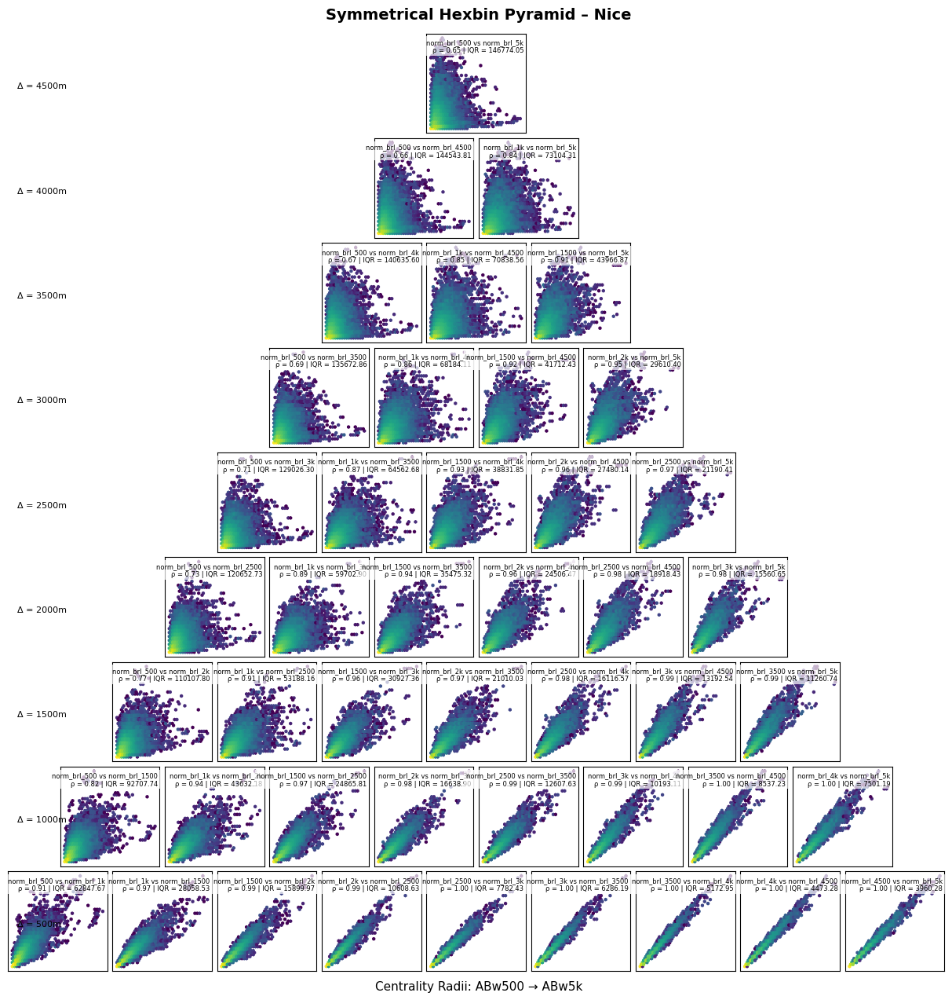


Plotting pyramid for Lille


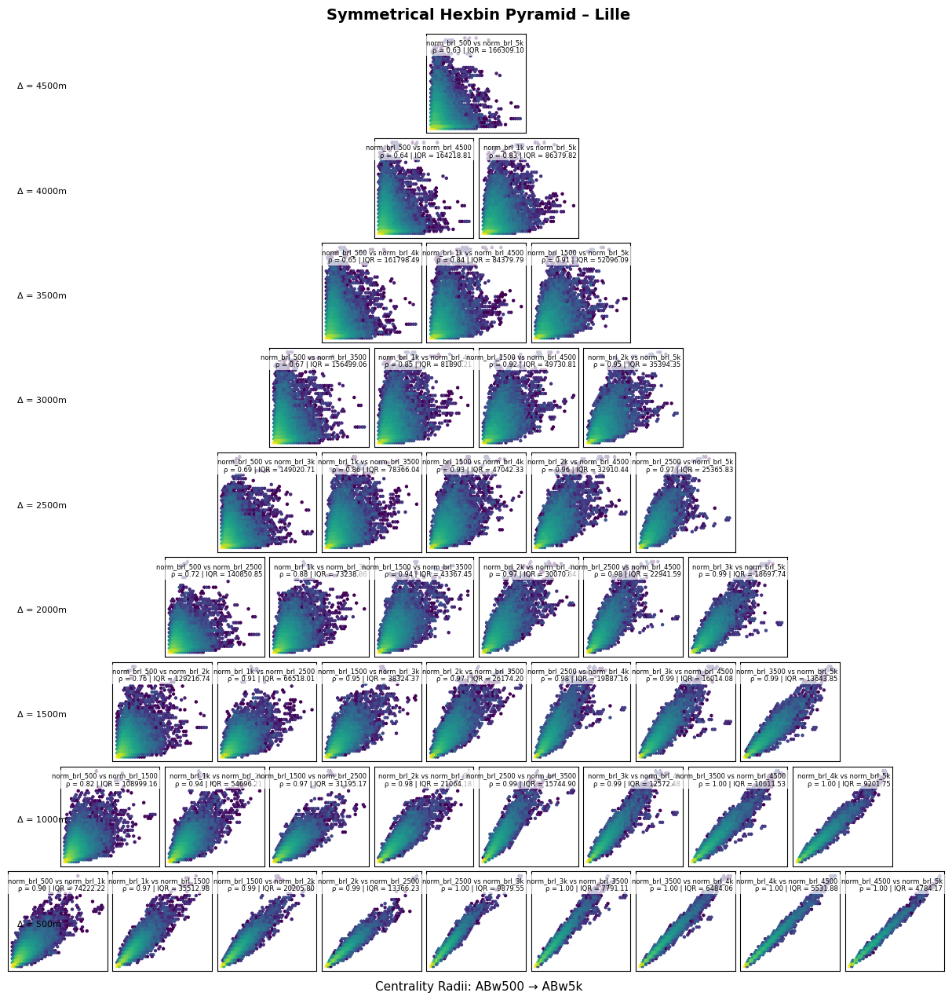


Plotting pyramid for Vienna


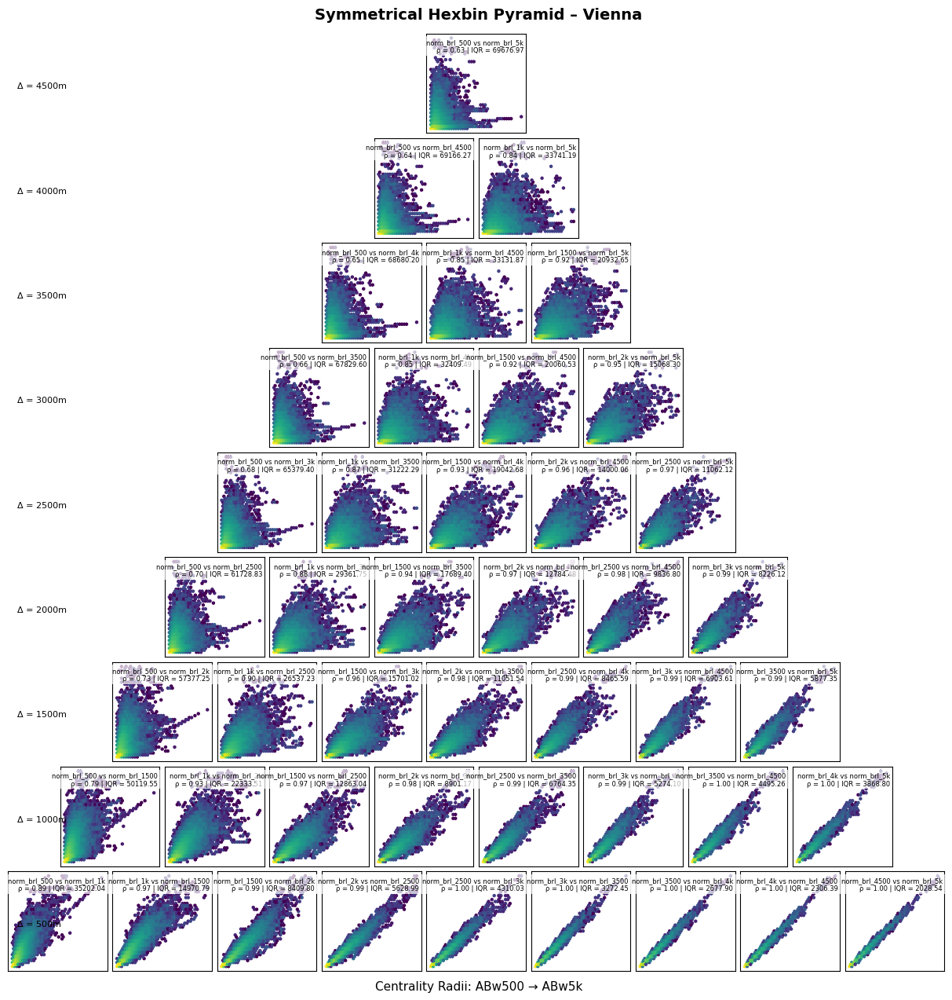


Plotting pyramid for Gothenburg


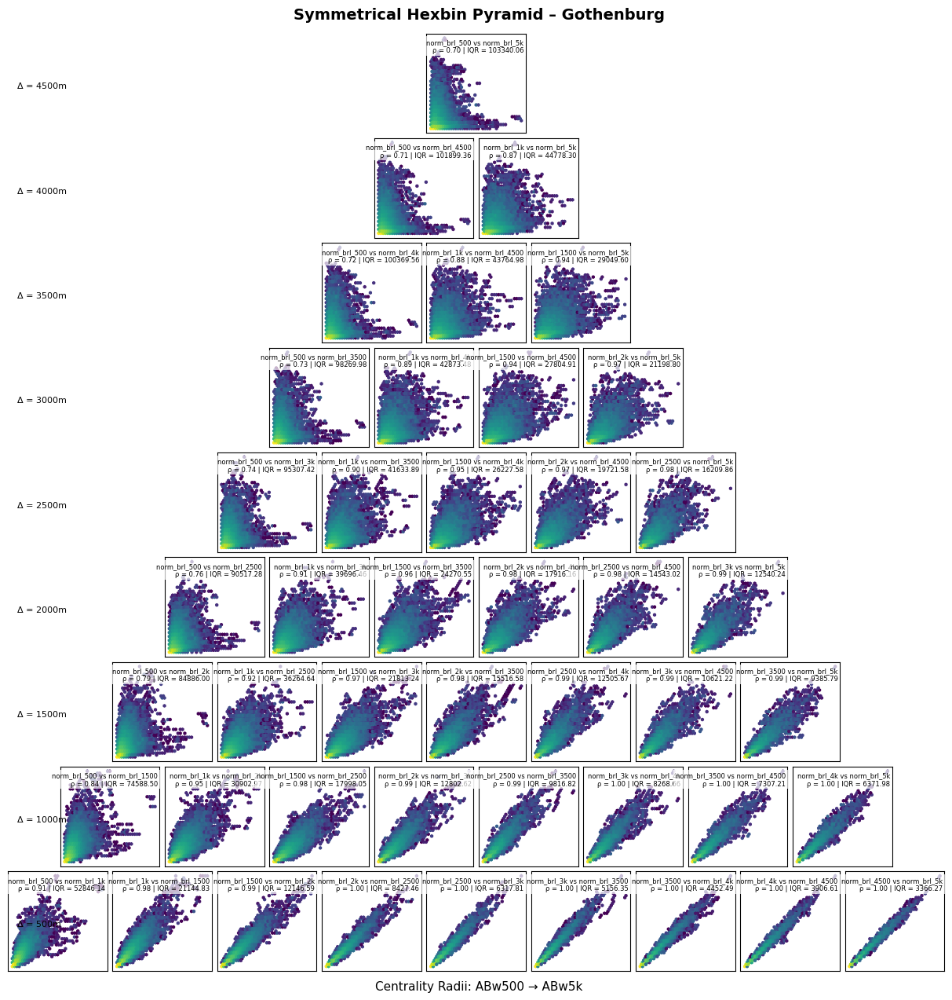


Plotting pyramid for Versilia


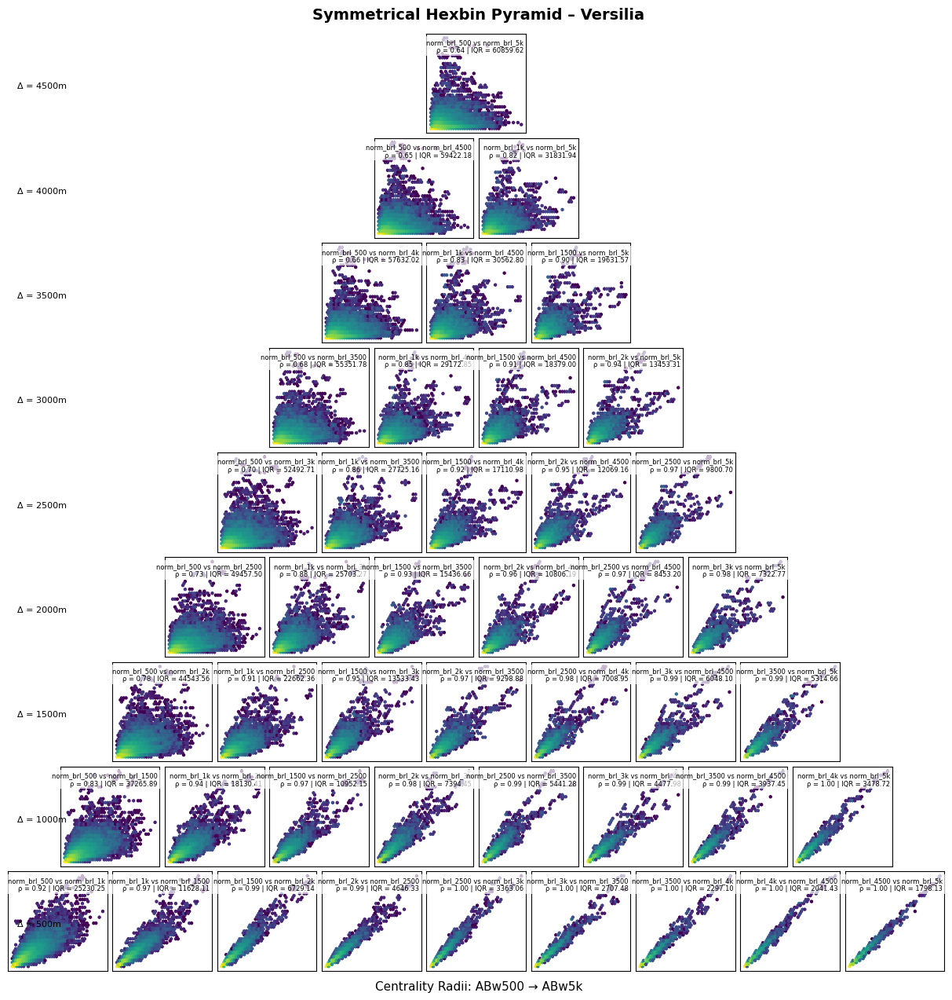

In [35]:

# Define radius columns and mapping
radius_columns = [
        'norm_brl_500', 'norm_brl_1k', 'norm_brl_1500',
       'norm_brl_2k', 'norm_brl_2500', 'norm_brl_3k', 'norm_brl_3500',
       'norm_brl_4k', 'norm_brl_4500', 'norm_brl_5k']
radius_values = {
    "norm_brl_500": 500, "norm_brl_1k": 1000, "norm_brl_1500": 1500, "norm_brl_2k": 2000, "norm_brl_2500": 2500,
    "norm_brl_3k": 3000, "norm_brl_3500": 3500, "norm_brl_4k": 4000, "norm_brl_4500": 4500, "norm_brl_5k": 5000
}

# Generate pairings grouped by gap
pair_groups = {}
for col1, col2 in itertools.combinations(radius_columns, 2):
    gap = abs(radius_values[col1] - radius_values[col2])
    pair_groups.setdefault(gap, []).append((col1, col2))

sorted_gaps = sorted(pair_groups.keys(), reverse=True)
max_plots = max(len(pairs) for pairs in pair_groups.values())
n_rows = len(sorted_gaps)

# Group by city
cities = gdf["city"].dropna().unique()

# Plot each city
for city in cities:
    print(f"\nPlotting pyramid for {city}")
    df = gdf[gdf["city"] == city][radius_columns].dropna()

    if df.empty:
        print(f"Skipping {city} due to missing data.")
        continue

    plot_size = 1.0 / max_plots
    fig_height = plot_size * n_rows * 1.05
    fig = plt.figure(figsize=(12, 12))  # Square output

    for row_idx, gap in enumerate(sorted_gaps):
        pairs = pair_groups[gap]
        n = len(pairs)
        row_bottom = 1 - ((row_idx + 1) * plot_size)

        for i, (col1, col2) in enumerate(pairs):
            total_plot_width = n * plot_size
            left = (1 - total_plot_width) / 2 + i * plot_size

            ax = fig.add_axes([left, row_bottom, plot_size * 0.95, plot_size * 0.95])
            ax.hexbin(df[col1], df[col2], gridsize=40, cmap='viridis', bins='log')
            ax.set_xticks([])
            ax.set_yticks([])

            # Compute Spearman correlation
            rho, _ = spearmanr(df[col1], df[col2])

            # Compute dispersion as IQR of residuals on ranked data
            x_ranked = df[col1].rank().values
            y_ranked = df[col2].rank().values
            coeffs = np.polyfit(x_ranked, y_ranked, deg=1)
            predicted = np.polyval(coeffs, x_ranked)
            residuals = y_ranked - predicted
            q75, q25 = np.percentile(residuals, [75, 25])
            dispersion = q75 - q25  # IQR

            ax.text(0.98, 0.95,
                    f"{col1} vs {col2}\nρ = {rho:.2f} | IQR = {dispersion:.2f}",
                    fontsize=6, ha='right', va='top',
                    transform=ax.transAxes,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2))

        # Gap value label on Y
        fig.text(0.01, row_bottom + plot_size * 0.45, f"Δ = {gap}m", va='center', fontsize=8)

    # Global title and axis info
    fig.text(0.5, 1.01, f"Symmetrical Hexbin Pyramid – {city}", ha='center', fontsize=14, weight='bold')
    fig.text(0.5, -0.02, "Centrality Radii: ABw500 → ABw5k", ha='center', fontsize=11)

    plt.show()


In [36]:

# Define file path and load layer
file_path = r"C:\Users\aaraldi\Desktop\EMC2_Streetscape\FLAVIA_Results_2005\paper_foreground_street_network\4_betweenness_meanrb_scaled_results\s4_mbr_scal_nms_combined.gpkg"
layer_name = "mbr_scal_3_zcores_nms_combined_cities_epsg3857"  # Update this if the actual layer name is different

# Load GeoPackage
gdf = gpd.read_file(file_path, layer=layer_name)


Plotting pyramid for Nice


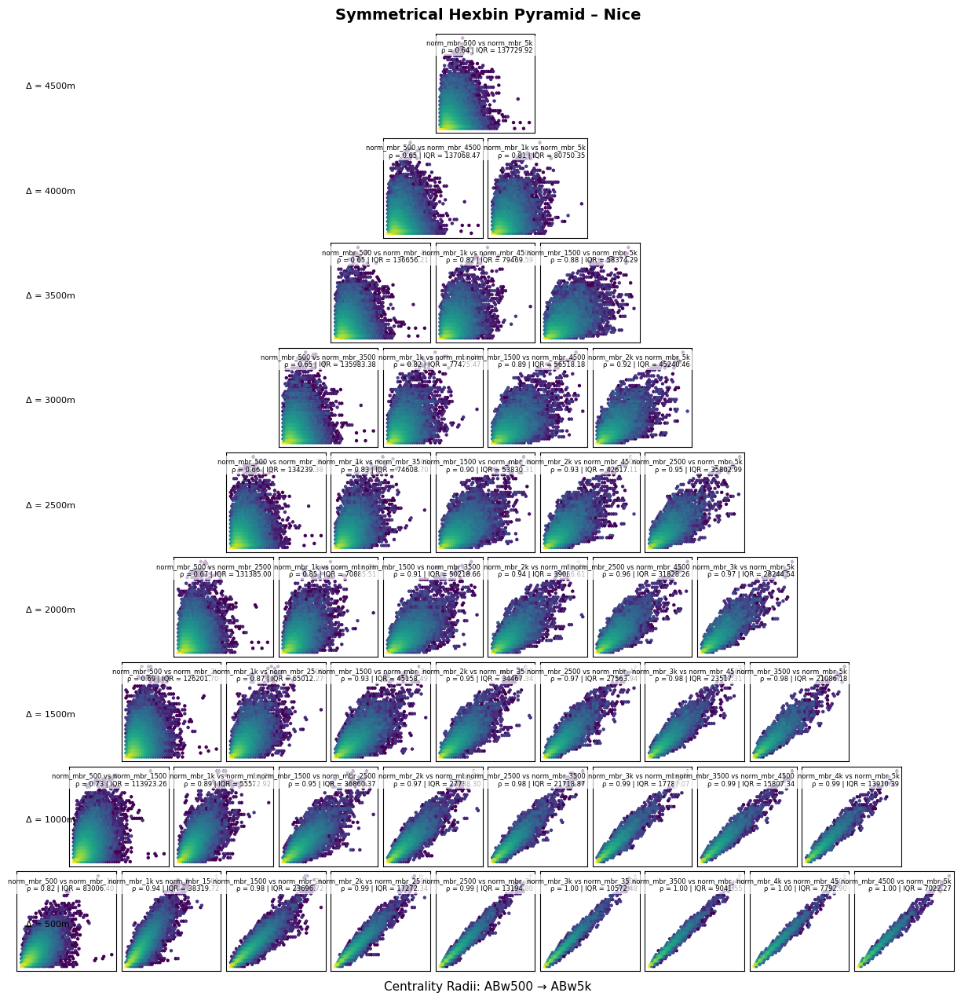


Plotting pyramid for Lille


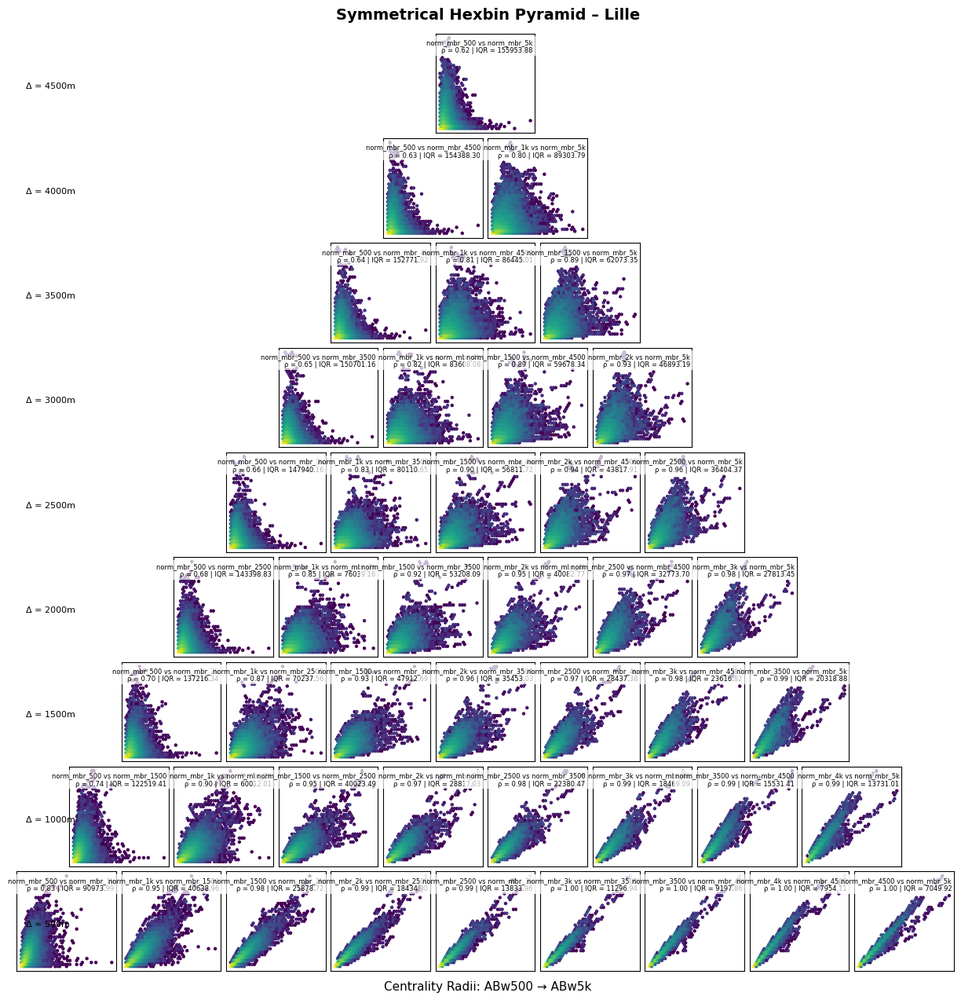


Plotting pyramid for Vienna


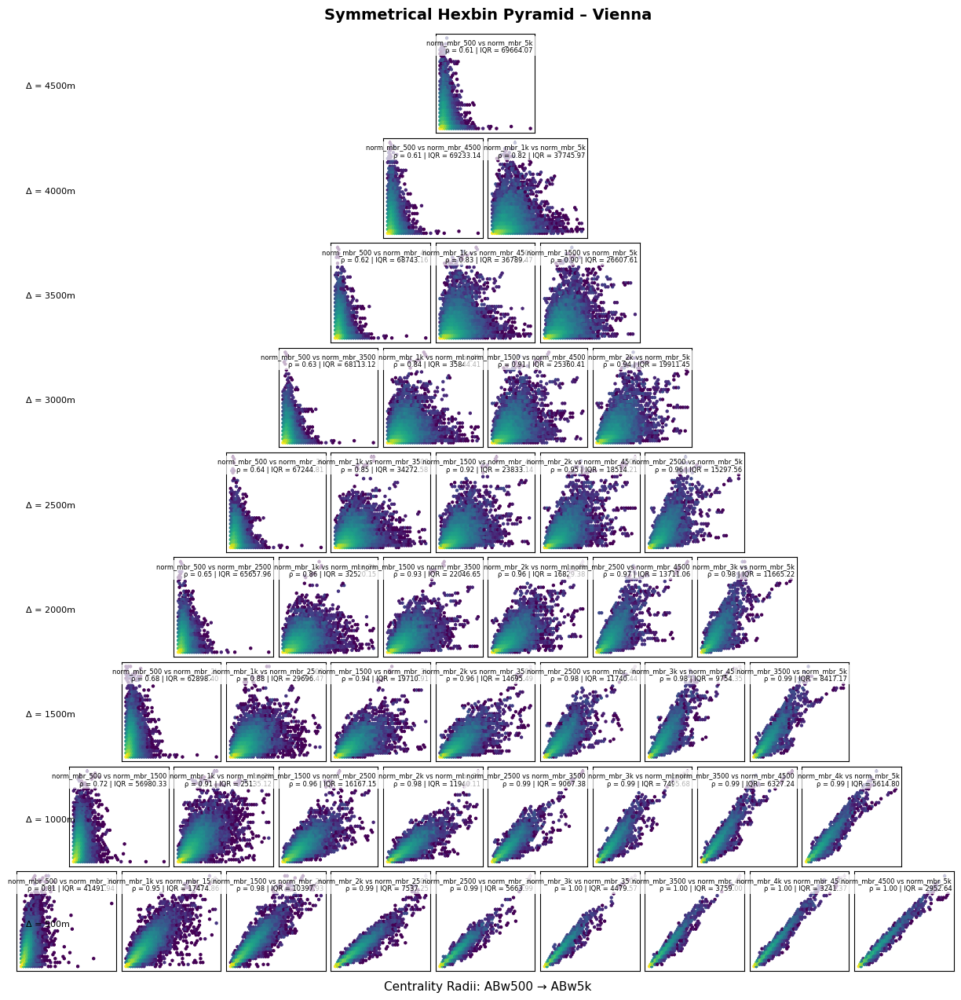


Plotting pyramid for Gothenburg


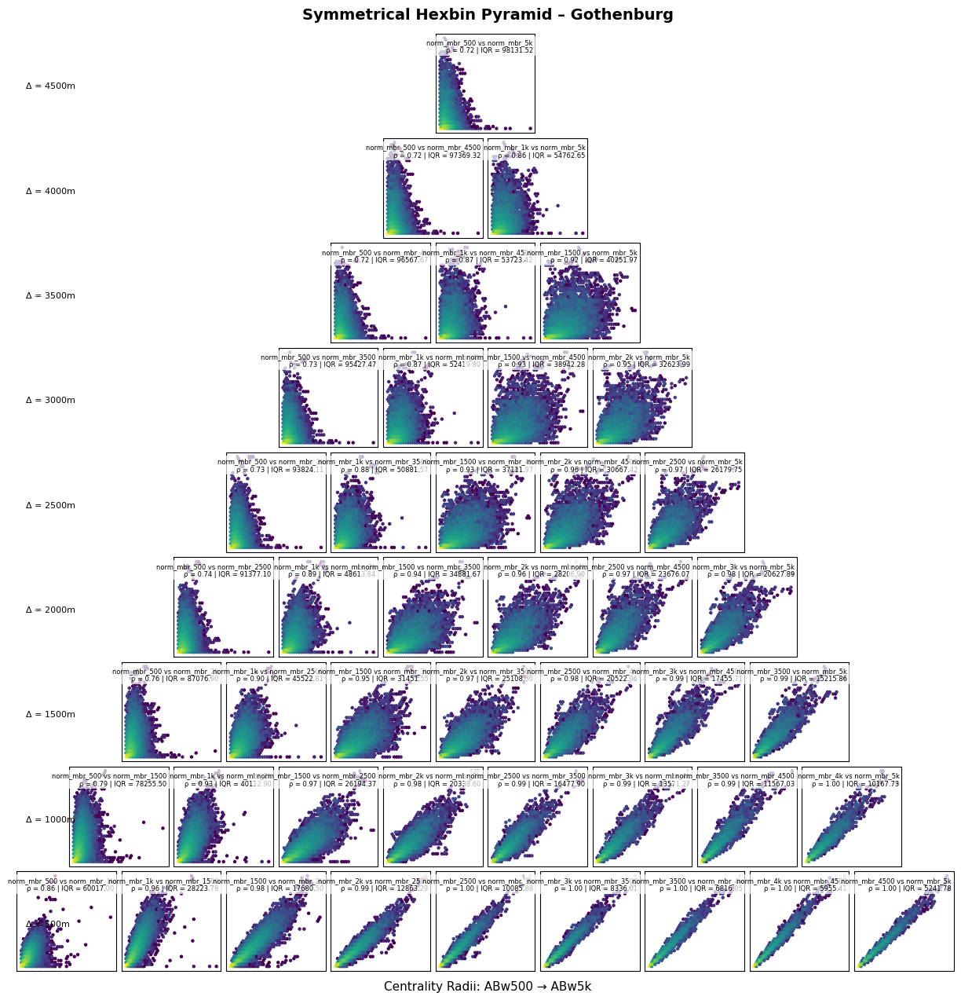


Plotting pyramid for Versilia


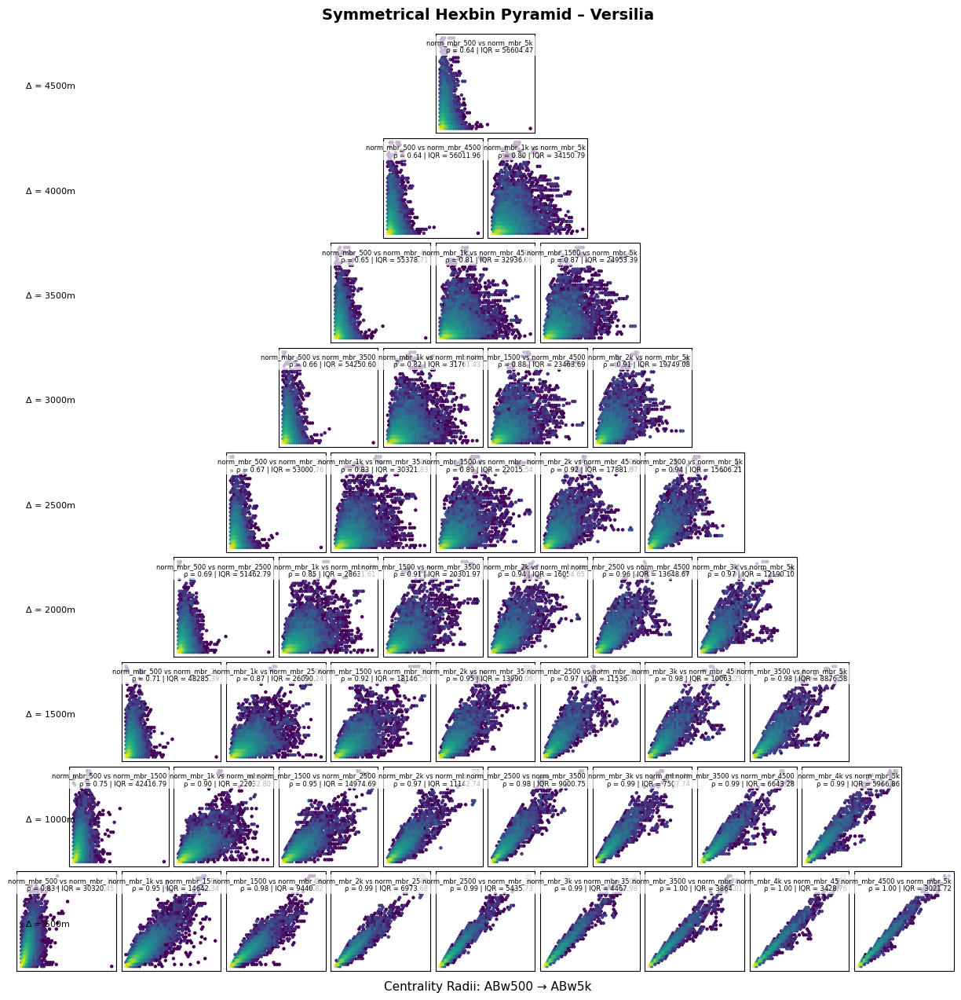

In [38]:

# Define radius columns and mapping
radius_columns = [
        'norm_mbr_500', 'norm_mbr_1k', 'norm_mbr_1500',
       'norm_mbr_2k', 'norm_mbr_2500', 'norm_mbr_3k', 'norm_mbr_3500',
       'norm_mbr_4k', 'norm_mbr_4500', 'norm_mbr_5k']
radius_values = {
    "norm_mbr_500": 500, "norm_mbr_1k": 1000, "norm_mbr_1500": 1500, "norm_mbr_2k": 2000, "norm_mbr_2500": 2500,
    "norm_mbr_3k": 3000, "norm_mbr_3500": 3500, "norm_mbr_4k": 4000, "norm_mbr_4500": 4500, "norm_mbr_5k": 5000
}

# Generate pairings grouped by gap
pair_groups = {}
for col1, col2 in itertools.combinations(radius_columns, 2):
    gap = abs(radius_values[col1] - radius_values[col2])
    pair_groups.setdefault(gap, []).append((col1, col2))

sorted_gaps = sorted(pair_groups.keys(), reverse=True)
max_plots = max(len(pairs) for pairs in pair_groups.values())
n_rows = len(sorted_gaps)

# Group by city
cities = gdf["city"].dropna().unique()

# Plot each city
for city in cities:
    print(f"\nPlotting pyramid for {city}")
    df = gdf[gdf["city"] == city][radius_columns].dropna()

    if df.empty:
        print(f"Skipping {city} due to missing data.")
        continue

    plot_size = 1.0 / max_plots
    fig_height = plot_size * n_rows * 1.05
    fig = plt.figure(figsize=(12, 12))  # Square output

    for row_idx, gap in enumerate(sorted_gaps):
        pairs = pair_groups[gap]
        n = len(pairs)
        row_bottom = 1 - ((row_idx + 1) * plot_size)

        for i, (col1, col2) in enumerate(pairs):
            total_plot_width = n * plot_size
            left = (1 - total_plot_width) / 2 + i * plot_size

            ax = fig.add_axes([left, row_bottom, plot_size * 0.95, plot_size * 0.95])
            ax.hexbin(df[col1], df[col2], gridsize=40, cmap='viridis', bins='log')
            ax.set_xticks([])
            ax.set_yticks([])

            # Compute Spearman correlation
            rho, _ = spearmanr(df[col1], df[col2])

            # Compute dispersion as IQR of residuals on ranked data
            x_ranked = df[col1].rank().values
            y_ranked = df[col2].rank().values
            coeffs = np.polyfit(x_ranked, y_ranked, deg=1)
            predicted = np.polyval(coeffs, x_ranked)
            residuals = y_ranked - predicted
            q75, q25 = np.percentile(residuals, [75, 25])
            dispersion = q75 - q25  # IQR

            ax.text(0.98, 0.95,
                    f"{col1} vs {col2}\nρ = {rho:.2f} | IQR = {dispersion:.2f}",
                    fontsize=6, ha='right', va='top',
                    transform=ax.transAxes,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2))

        # Gap value label on Y
        fig.text(0.01, row_bottom + plot_size * 0.45, f"Δ = {gap}m", va='center', fontsize=8)

    # Global title and axis info
    fig.text(0.5, 1.01, f"Symmetrical Hexbin Pyramid – {city}", ha='center', fontsize=14, weight='bold')
    fig.text(0.5, -0.02, "Centrality Radii: ABw500 → ABw5k", ha='center', fontsize=11)

    plt.show()


## 2) EDA of Street Type Clusterings

In [39]:
import geopandas as gpd

# Load the layers
Om = gpd.read_file(r"C:/Users/aaraldi/Desktop/EMC2_Streetscape/FLAVIA_Results_2506/1_original_method_results/s4_om_scal_nms_combined.gpkg")
Nch = gpd.read_file(r"C:/Users/aaraldi/Desktop/EMC2_Streetscape/FLAVIA_Results_2506/5_nach_scaled/s4_nach_scal_nms_combined.gpkg")
Mbr = gpd.read_file(r"C:/Users/aaraldi/Desktop/EMC2_Streetscape/FLAVIA_Results_2005/paper_foreground_street_network/4_betweenness_meanrb_scaled_results/s4_mbr_scal_nms_combined.gpkg")
Brl = gpd.read_file(r"C:/Users/aaraldi/Desktop/EMC2_Streetscape/FLAVIA_Results_2506/2_betweenness_reach_results/s4_brl_scal_nms_combined.gpkg")

# Rename columns to include layer suffix
Om = Om.rename(columns={col: f"{col}_Om" for col in Om.columns if col not in ['id', 'city', 'geometry']})
Nch = Nch.rename(columns={col: f"{col}_Nch" for col in Nch.columns if col not in ['id', 'city', 'geometry']})
Mbr = Mbr.rename(columns={col: f"{col}_Mbr" for col in Mbr.columns if col not in ['id', 'city', 'geometry']})
Brl = Brl.rename(columns={col: f"{col}_Brl" for col in Brl.columns if col not in ['id', 'city', 'geometry']})

# Perform successive joins on id and city
merged = Om.merge(Nch, on=['id', 'city', 'geometry'], how='outer')
merged = merged.merge(Mbr, on=['id', 'city', 'geometry'], how='outer')
merged = merged.merge(Brl, on=['id', 'city', 'geometry'], how='outer')

# Save the merged file
merged.to_file("C:/Users/aaraldi/Desktop/EMC2_Streetscape/FLAVIA_Results_2506/merged_layers.gpkg", driver="GPKG")


In [40]:
# Replace cluster_4 categorical values
merged['cluster_4_Om'] = merged['cluster_4_Om'].replace({0:4, 1:3, 2:2, 3:1})
merged['cluster_4_Nch'] = merged['cluster_4_Nch'].replace({0:3, 1:4, 2:1, 3:2})
merged['cluster_4_Mbr'] = merged['cluster_4_Mbr'].replace({0:3, 1:2, 2:4, 3:1})
merged['cluster_4_Brl'] = merged['cluster_4_Brl'].replace({0:4, 1:3, 2:1, 3:2})

In [41]:
merged['cluster_4_Mbr'] = merged['cluster_4_Mbr'].fillna(-1).astype(int)
merged['cluster_4_Brl'] = merged['cluster_4_Brl'].fillna(-1).astype(int)


# Compute contingency matrices, excluding rows with -1 in either column being compared

# Filter data for Om vs Nch
filtered_Om_Nch = merged[(merged['cluster_4_Om'] != -1) & (merged['cluster_4_Nch'] != -1)]
labels_Om_Nch = sorted(list(set(filtered_Om_Nch['cluster_4_Om'].unique()).union(set(filtered_Om_Nch['cluster_4_Nch'].unique()))))
contingency_Om_Nch = pd.DataFrame(confusion_matrix(filtered_Om_Nch['cluster_4_Om'], filtered_Om_Nch['cluster_4_Nch'], labels=labels_Om_Nch),
                                  index=labels_Om_Nch,
                                  columns=labels_Om_Nch)

# Filter data for Om vs Mbr
filtered_Om_Mbr = merged[(merged['cluster_4_Om'] != -1) & (merged['cluster_4_Mbr'] != -1)]
labels_Om_Mbr = sorted(list(set(filtered_Om_Mbr['cluster_4_Om'].unique()).union(set(filtered_Om_Mbr['cluster_4_Mbr'].unique()))))
contingency_Om_Mbr = pd.DataFrame(confusion_matrix(filtered_Om_Mbr['cluster_4_Om'], filtered_Om_Mbr['cluster_4_Mbr'], labels=labels_Om_Mbr),
                                  index=labels_Om_Mbr,
                                  columns=labels_Om_Mbr)

# Filter data for Om vs Brl
filtered_Om_Brl = merged[(merged['cluster_4_Om'] != -1) & (merged['cluster_4_Brl'] != -1)]
labels_Om_Brl = sorted(list(set(filtered_Om_Brl['cluster_4_Om'].unique()).union(set(filtered_Om_Brl['cluster_4_Brl'].unique()))))
contingency_Om_Brl = pd.DataFrame(confusion_matrix(filtered_Om_Brl['cluster_4_Om'], filtered_Om_Brl['cluster_4_Brl'], labels=labels_Om_Brl),
                                  index=labels_Om_Brl,
                                  columns=labels_Om_Brl)


print("Contingency Matrix Om vs Nch:")
print(contingency_Om_Nch)

print("Contingency Matrix Om vs Mbr:")
print(contingency_Om_Mbr)

print("Contingency Matrix Om vs Brl:")


# Function to calculate percentages for a contingency matrix
def calculate_percentage_matrix(matrix):
    return matrix.div(matrix.sum(axis=1), axis=0) * 100

# Calculate percentage matrices
percentage_Om_Nch = calculate_percentage_matrix(contingency_Om_Nch)
percentage_Om_Mbr = calculate_percentage_matrix(contingency_Om_Mbr)
percentage_Om_Brl = calculate_percentage_matrix(contingency_Om_Brl)


print(contingency_Om_Brl)

Contingency Matrix Om vs Nch:
        1       2       3      4
1   78283    2596    2023      0
2   86584   37917    3472      0
3   49681  180647   95679      0
4  180390  305101  618009  87521
Contingency Matrix Om vs Mbr:
       1       2       3       4
1  68047    4440    7796    2619
2  34285   75385    8537    9766
3   9191   81415  171460   63941
4  37710  112845  420690  619775
Contingency Matrix Om vs Brl:
       1       2       3       4
1  73641    4730    1987    2544
2  13740  101800    7239    5194
3  10891   41157  232499   41460
4  48238   91434  125192  926156


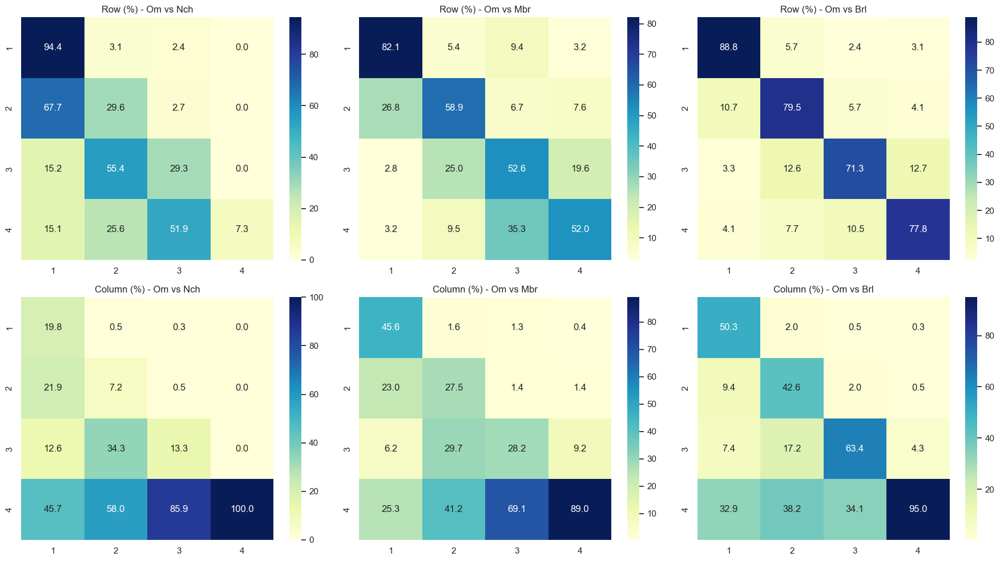

In [42]:
# CONTINGENCY TABLES (COUNT)---------------------------------------------

# ===================
# 1. Prepare data
# ===================
# Fill non-finite values and convert float labels to integers
merged['cluster_4_Mbr'] = merged['cluster_4_Mbr'].fillna(-1).astype(int)
merged['cluster_4_Brl'] = merged['cluster_4_Brl'].fillna(-1).astype(int)

# ===================
# 2. Build contingency tables
# ===================
filtered_Om_Nch = merged[(merged['cluster_4_Om'] != -1) & (merged['cluster_4_Nch'] != -1)]
labels_Om_Nch = sorted(set(filtered_Om_Nch['cluster_4_Om']) | set(filtered_Om_Nch['cluster_4_Nch']))
contingency_Om_Nch = pd.DataFrame(
    confusion_matrix(filtered_Om_Nch['cluster_4_Om'], filtered_Om_Nch['cluster_4_Nch'], labels=labels_Om_Nch),
    index=labels_Om_Nch, columns=labels_Om_Nch
)

filtered_Om_Mbr = merged[(merged['cluster_4_Om'] != -1) & (merged['cluster_4_Mbr'] != -1)]
labels_Om_Mbr = sorted(set(filtered_Om_Mbr['cluster_4_Om']) | set(filtered_Om_Mbr['cluster_4_Mbr']))
contingency_Om_Mbr = pd.DataFrame(
    confusion_matrix(filtered_Om_Mbr['cluster_4_Om'], filtered_Om_Mbr['cluster_4_Mbr'], labels=labels_Om_Mbr),
    index=labels_Om_Mbr, columns=labels_Om_Mbr
)

filtered_Om_Brl = merged[(merged['cluster_4_Om'] != -1) & (merged['cluster_4_Brl'] != -1)]
labels_Om_Brl = sorted(set(filtered_Om_Brl['cluster_4_Om']) | set(filtered_Om_Brl['cluster_4_Brl']))
contingency_Om_Brl = pd.DataFrame(
    confusion_matrix(filtered_Om_Brl['cluster_4_Om'], filtered_Om_Brl['cluster_4_Brl'], labels=labels_Om_Brl),
    index=labels_Om_Brl, columns=labels_Om_Brl
)

# ===================
# 3. Compute normalized (%)
# ===================
def normalize_rows(df):
    return df.div(df.sum(axis=1), axis=0) * 100

def normalize_cols(df):
    return df.div(df.sum(axis=0), axis=1) * 100

row_percentage_Om_Nch = normalize_rows(contingency_Om_Nch)
col_percentage_Om_Nch = normalize_cols(contingency_Om_Nch)

row_percentage_Om_Mbr = normalize_rows(contingency_Om_Mbr)
col_percentage_Om_Mbr = normalize_cols(contingency_Om_Mbr)

row_percentage_Om_Brl = normalize_rows(contingency_Om_Brl)
col_percentage_Om_Brl = normalize_cols(contingency_Om_Brl)

# ===================
# 4. Plot heatmaps side-by-side
# ===================
sns.set(style='whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.heatmap(row_percentage_Om_Nch, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 0])
axes[0, 0].set_title('Row (%) - Om vs Nch')
sns.heatmap(col_percentage_Om_Nch, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 0])
axes[1, 0].set_title('Column (%) - Om vs Nch')

sns.heatmap(row_percentage_Om_Mbr, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 1])
axes[0, 1].set_title('Row (%) - Om vs Mbr')
sns.heatmap(col_percentage_Om_Mbr, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 1])
axes[1, 1].set_title('Column (%) - Om vs Mbr')

sns.heatmap(row_percentage_Om_Brl, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 2])
axes[0, 2].set_title('Row (%) - Om vs Brl')
sns.heatmap(col_percentage_Om_Brl, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 2])
axes[1, 2].set_title('Column (%) - Om vs Brl')

plt.tight_layout()
plt.show()


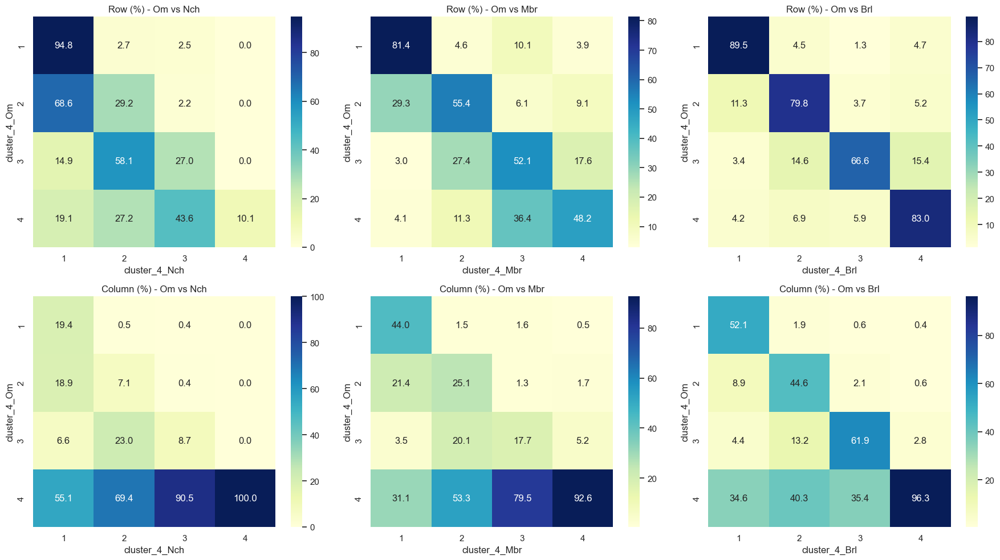

In [43]:
# CONTINGENCY TABLES (Weighted by Length)---------------------------------------------

# ===================
# 1. Compute lengths
# ===================
merged['length'] = merged.geometry.length

# Fill NA and set up the label columns
merged['cluster_4_Mbr'] = merged['cluster_4_Mbr'].fillna(-1).astype(int)
merged['cluster_4_Brl'] = merged['cluster_4_Brl'].fillna(-1).astype(int)

# ===================
# 2. Helper to build length-weighted contingency
# ===================
def build_length_weighted_matrix(df, col_x, col_y):
    filtered = df[(df[col_x] != -1) & (df[col_y] != -1)]
    # sum length for each cluster pair
    length_matrix = filtered.groupby([col_x, col_y])['length'].sum().unstack(fill_value=0)
    # Fill missing columns/index with all unique labels
    all_x_labels = sorted(
        set(filtered[col_x]).union(set(filtered[col_y]))
    )
    length_matrix = length_matrix.reindex(
        index=all_x_labels,
        columns=all_x_labels,
        fill_value=0
    )
    return length_matrix

# ===================
# 3. Build matrices
# ===================
contingency_Om_Nch = build_length_weighted_matrix(merged, 'cluster_4_Om', 'cluster_4_Nch')
contingency_Om_Mbr = build_length_weighted_matrix(merged, 'cluster_4_Om', 'cluster_4_Mbr')
contingency_Om_Brl = build_length_weighted_matrix(merged, 'cluster_4_Om', 'cluster_4_Brl')

# ===================
# 4. Normalize (%)
# ===================
def normalize_rows(df):
    return df.div(df.sum(axis=1), axis=0) * 100

def normalize_cols(df):
    return df.div(df.sum(axis=0), axis=1) * 100

row_percentage_Om_Nch = normalize_rows(contingency_Om_Nch)
col_percentage_Om_Nch = normalize_cols(contingency_Om_Nch)

row_percentage_Om_Mbr = normalize_rows(contingency_Om_Mbr)
col_percentage_Om_Mbr = normalize_cols(contingency_Om_Mbr)

row_percentage_Om_Brl = normalize_rows(contingency_Om_Brl)
col_percentage_Om_Brl = normalize_cols(contingency_Om_Brl)

# ===================
# 5. Plot heatmaps
# ===================
sns.set(style='whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.heatmap(row_percentage_Om_Nch, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 0])
axes[0, 0].set_title('Row (%) - Om vs Nch')
sns.heatmap(col_percentage_Om_Nch, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 0])
axes[1, 0].set_title('Column (%) - Om vs Nch')

sns.heatmap(row_percentage_Om_Mbr, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 1])
axes[0, 1].set_title('Row (%) - Om vs Mbr')
sns.heatmap(col_percentage_Om_Mbr, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 1])
axes[1, 1].set_title('Column (%) - Om vs Mbr')

sns.heatmap(row_percentage_Om_Brl, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 2])
axes[0, 2].set_title('Row (%) - Om vs Brl')
sns.heatmap(col_percentage_Om_Brl, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 2])
axes[1, 2].set_title('Column (%) - Om vs Brl')

plt.tight_layout()
plt.show()


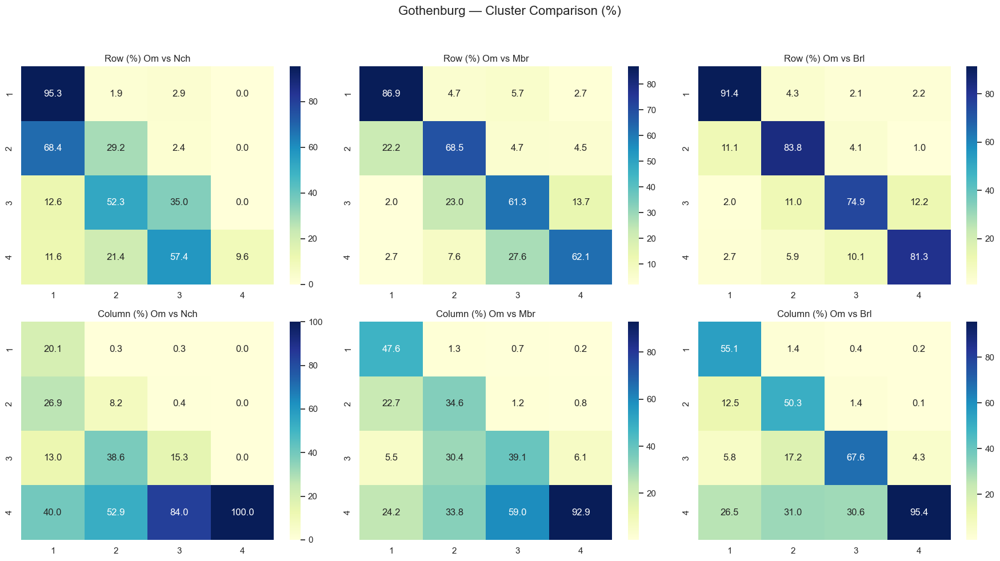

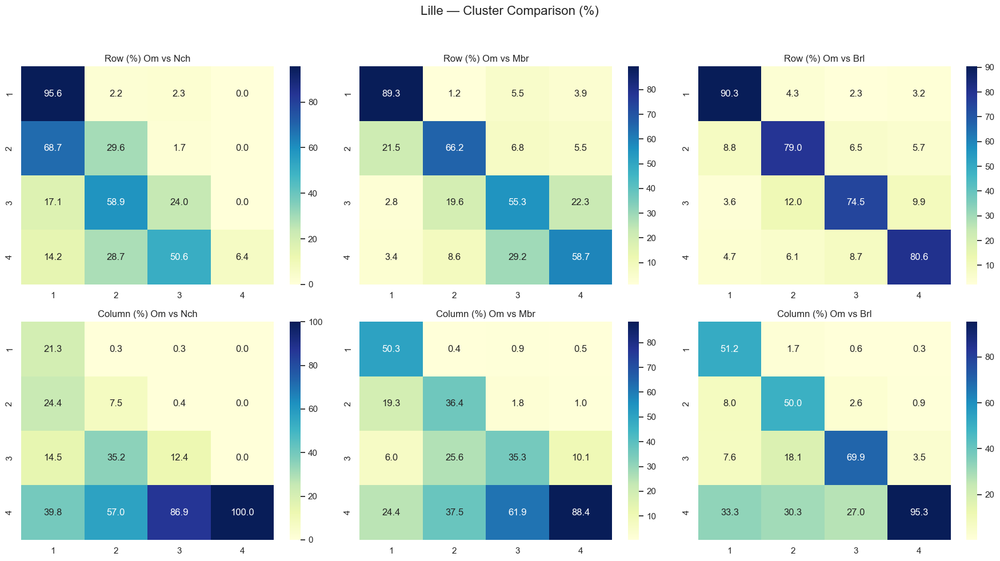

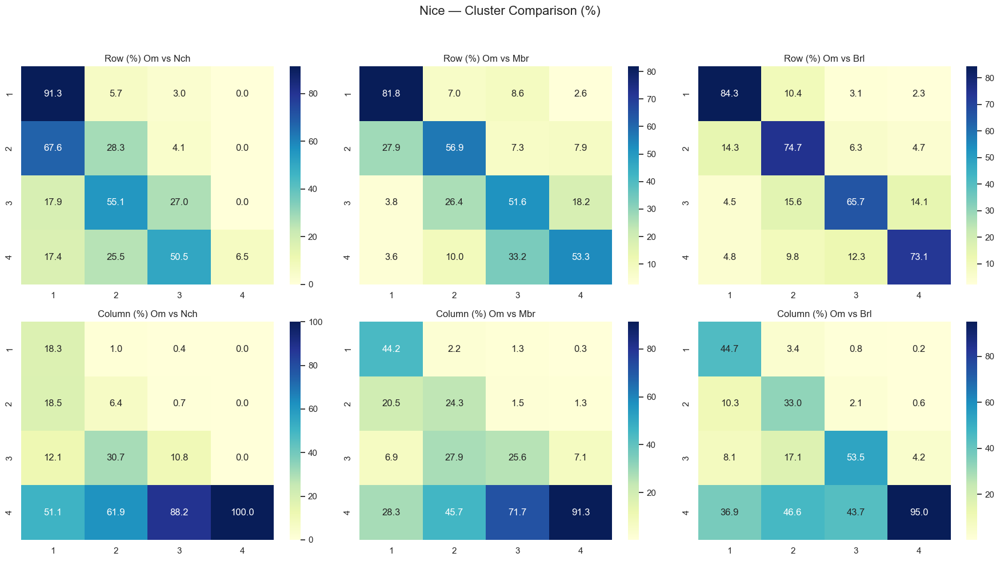

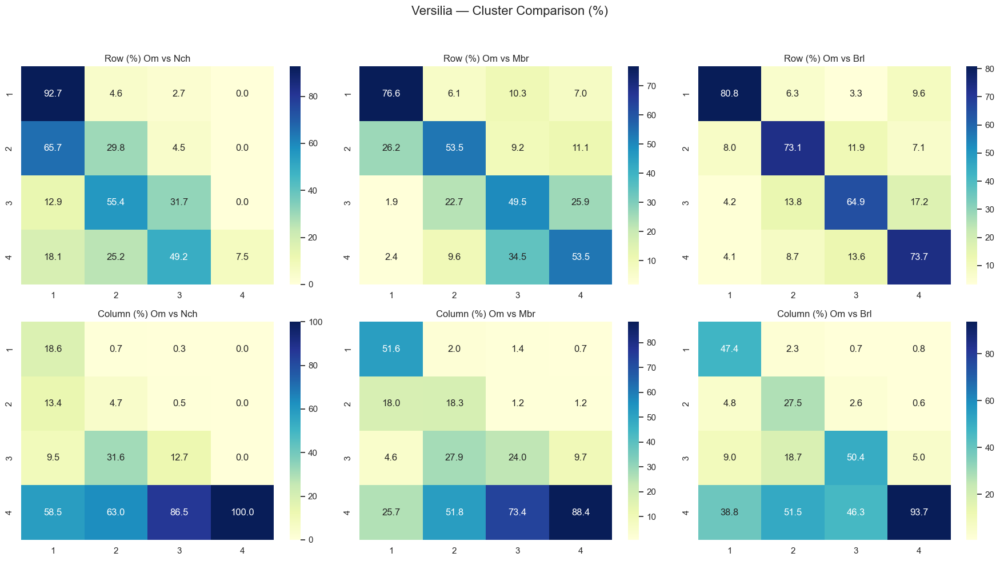

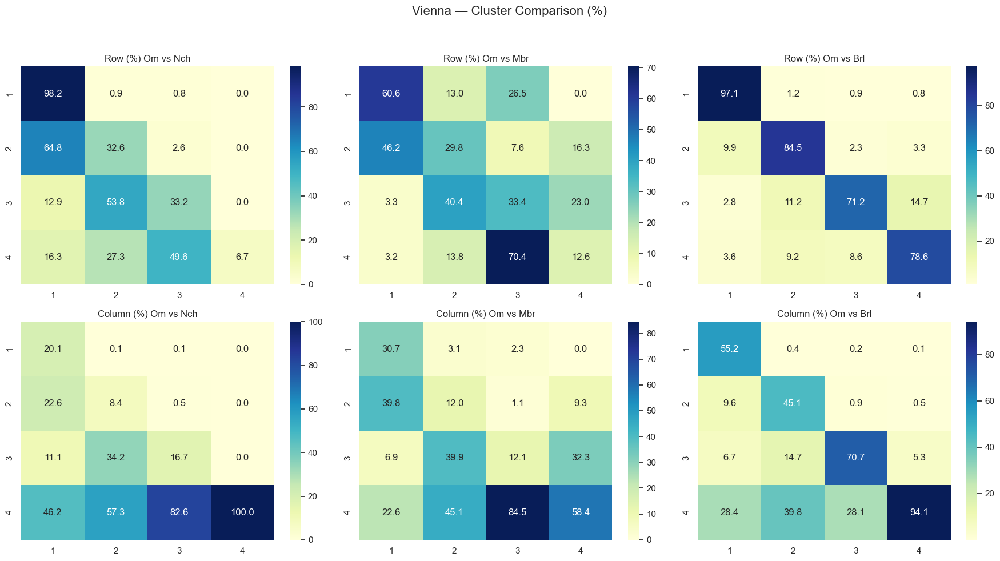

In [46]:
# CONTINGENCY TABLES (COUNT) by CITY ---------------------------------------------

# Helper normalization
def normalize_rows(df):
    return df.div(df.sum(axis=1), axis=0) * 100

def normalize_cols(df):
    return df.div(df.sum(axis=0), axis=1) * 100

sns.set(style='whitegrid')

# Get list of cities
cities = merged['city'].unique()

# Loop over each city
for city_name in cities:
    city_df = merged[merged['city'] == city_name]

    # Filter & build contingency tables
    filtered_Om_Nch = city_df[(city_df['cluster_4_Om'] != -1) & (city_df['cluster_4_Nch'] != -1)]
    labels_Om_Nch = sorted(
        set(filtered_Om_Nch['cluster_4_Om']) | set(filtered_Om_Nch['cluster_4_Nch'])
    )
    contingency_Om_Nch = pd.DataFrame(
        confusion_matrix(
            filtered_Om_Nch['cluster_4_Om'], filtered_Om_Nch['cluster_4_Nch'], labels=labels_Om_Nch
        ),
        index=labels_Om_Nch, columns=labels_Om_Nch
    )

    filtered_Om_Mbr = city_df[(city_df['cluster_4_Om'] != -1) & (city_df['cluster_4_Mbr'] != -1)]
    labels_Om_Mbr = sorted(
        set(filtered_Om_Mbr['cluster_4_Om']) | set(filtered_Om_Mbr['cluster_4_Mbr'])
    )
    contingency_Om_Mbr = pd.DataFrame(
        confusion_matrix(
            filtered_Om_Mbr['cluster_4_Om'], filtered_Om_Mbr['cluster_4_Mbr'], labels=labels_Om_Mbr
        ),
        index=labels_Om_Mbr, columns=labels_Om_Mbr
    )

    filtered_Om_Brl = city_df[(city_df['cluster_4_Om'] != -1) & (city_df['cluster_4_Brl'] != -1)]
    labels_Om_Brl = sorted(
        set(filtered_Om_Brl['cluster_4_Om']) | set(filtered_Om_Brl['cluster_4_Brl'])
    )
    contingency_Om_Brl = pd.DataFrame(
        confusion_matrix(
            filtered_Om_Brl['cluster_4_Om'], filtered_Om_Brl['cluster_4_Brl'], labels=labels_Om_Brl
        ),
        index=labels_Om_Brl, columns=labels_Om_Brl
    )

    # Normalize
    row_Om_Nch = normalize_rows(contingency_Om_Nch)
    col_Om_Nch = normalize_cols(contingency_Om_Nch)
    row_Om_Mbr = normalize_rows(contingency_Om_Mbr)
    col_Om_Mbr = normalize_cols(contingency_Om_Mbr)
    row_Om_Brl = normalize_rows(contingency_Om_Brl)
    col_Om_Brl = normalize_cols(contingency_Om_Brl)

    # Plot all six heatmaps
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(f"{city_name} — Cluster Comparison (%)", fontsize=16)

    sns.heatmap(row_Om_Nch, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 0])
    axes[0, 0].set_title('Row (%) Om vs Nch')
    sns.heatmap(col_Om_Nch, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 0])
    axes[1, 0].set_title('Column (%) Om vs Nch')

    sns.heatmap(row_Om_Mbr, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 1])
    axes[0, 1].set_title('Row (%) Om vs Mbr')
    sns.heatmap(col_Om_Mbr, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 1])
    axes[1, 1].set_title('Column (%) Om vs Mbr')

    sns.heatmap(row_Om_Brl, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 2])
    axes[0, 2].set_title('Row (%) Om vs Brl')
    sns.heatmap(col_Om_Brl, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 2])
    axes[1, 2].set_title('Column (%) Om vs Brl')

    plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for suptitle
    plt.show()


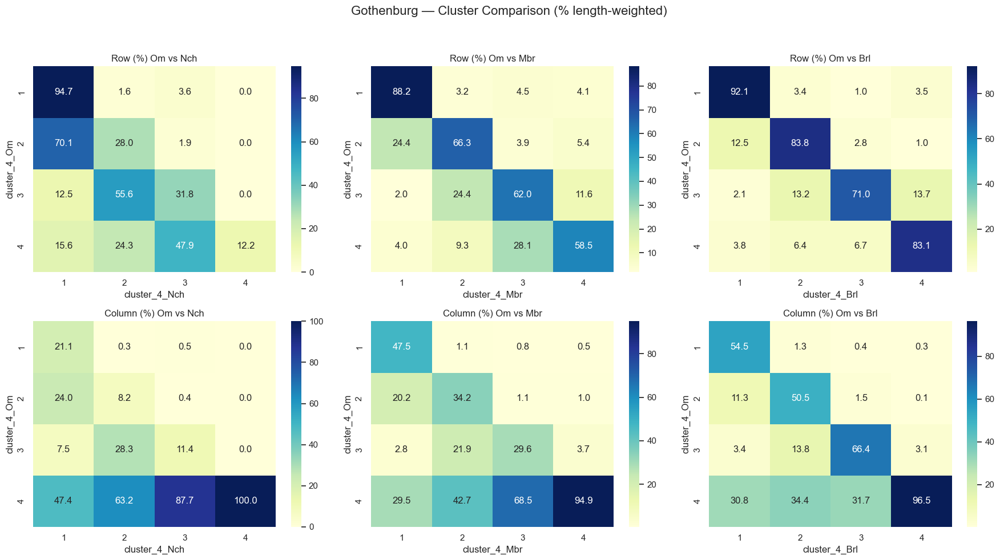

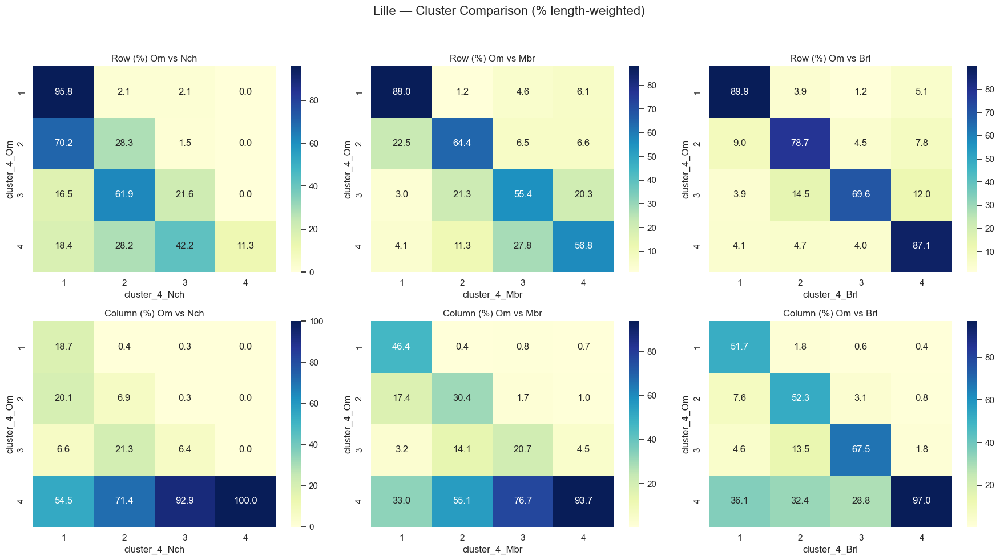

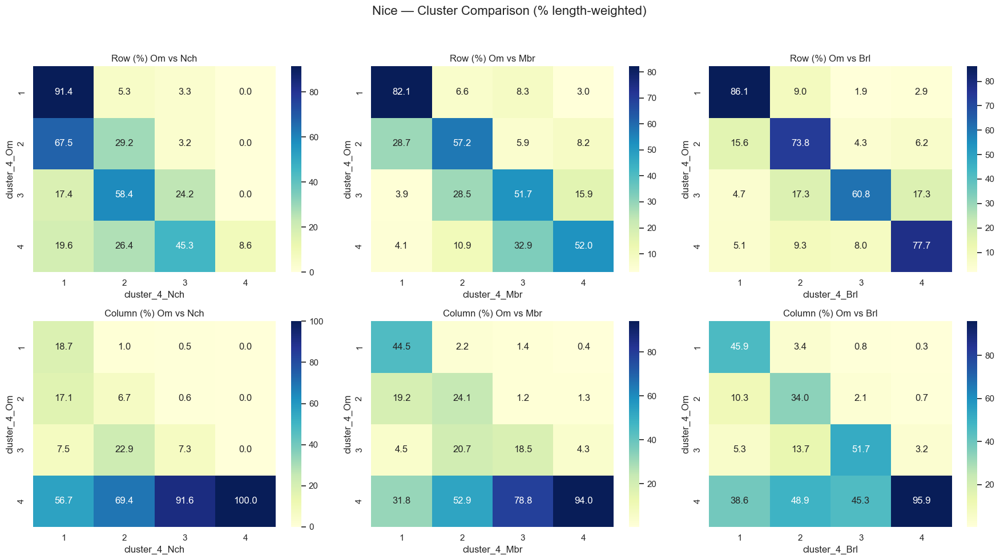

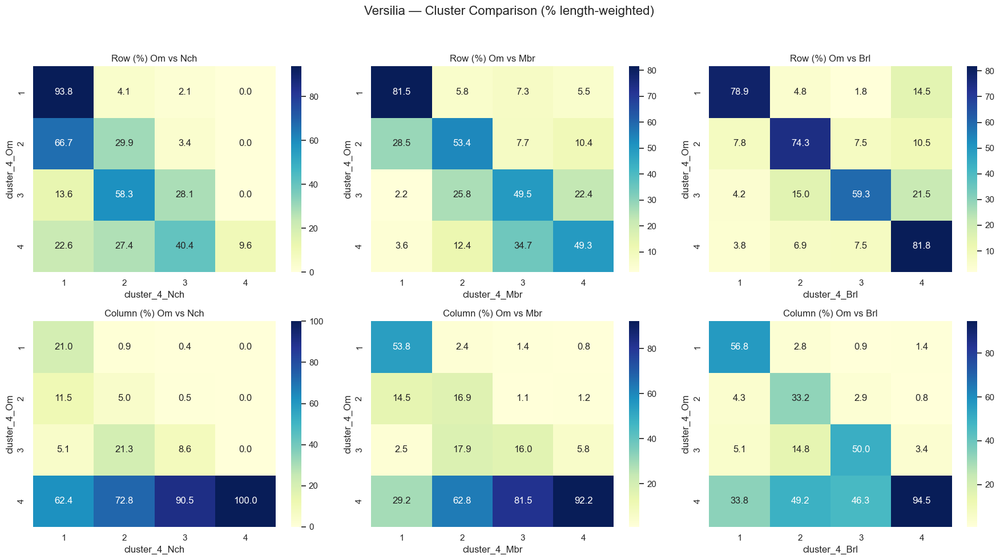

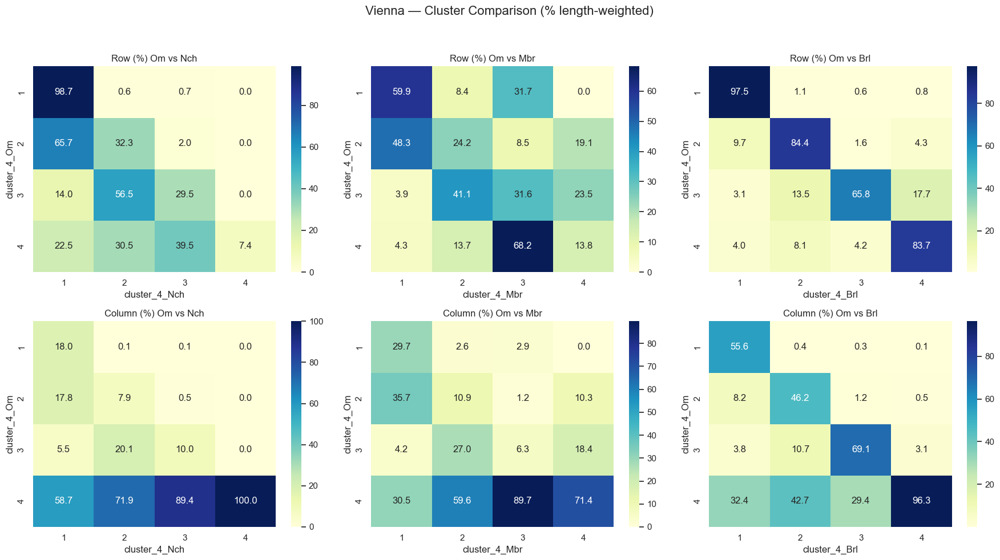

In [47]:
# CONTINGENCY TABLES (LENGTH) by CITY ---------------------------------------------


# Helper normalization
def normalize_rows(df):
    return df.div(df.sum(axis=1), axis=0) * 100

def normalize_cols(df):
    return df.div(df.sum(axis=0), axis=1) * 100

# Helper to build a length-weighted matrix
def build_length_weighted_matrix(df, col_x, col_y):
    filtered = df[(df[col_x] != -1) & (df[col_y] != -1)].copy()
    length_matrix = (
        filtered.groupby([col_x, col_y])['geometry'].apply(lambda g: g.length.sum()).unstack(fill_value=0)
    )
    all_labels = sorted(
        set(filtered[col_x]).union(set(filtered[col_y]))
    )
    length_matrix = length_matrix.reindex(
        index=all_labels,
        columns=all_labels,
        fill_value=0
    )
    return length_matrix

sns.set(style='whitegrid')

# Get list of cities
cities = merged['city'].unique()

# Loop over each city
for city_name in cities:
    city_df = merged[merged['city'] == city_name]

    # Build length-weighted contingency tables
    contingency_Om_Nch = build_length_weighted_matrix(city_df, 'cluster_4_Om', 'cluster_4_Nch')
    contingency_Om_Mbr = build_length_weighted_matrix(city_df, 'cluster_4_Om', 'cluster_4_Mbr')
    contingency_Om_Brl = build_length_weighted_matrix(city_df, 'cluster_4_Om', 'cluster_4_Brl')

    # Normalize
    row_Om_Nch = normalize_rows(contingency_Om_Nch)
    col_Om_Nch = normalize_cols(contingency_Om_Nch)

    row_Om_Mbr = normalize_rows(contingency_Om_Mbr)
    col_Om_Mbr = normalize_cols(contingency_Om_Mbr)

    row_Om_Brl = normalize_rows(contingency_Om_Brl)
    col_Om_Brl = normalize_cols(contingency_Om_Brl)

    # Plot all six heatmaps
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(f"{city_name} — Cluster Comparison (% length-weighted)", fontsize=16)

    sns.heatmap(row_Om_Nch, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 0])
    axes[0, 0].set_title('Row (%) Om vs Nch')
    sns.heatmap(col_Om_Nch, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 0])
    axes[1, 0].set_title('Column (%) Om vs Nch')

    sns.heatmap(row_Om_Mbr, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 1])
    axes[0, 1].set_title('Row (%) Om vs Mbr')
    sns.heatmap(col_Om_Mbr, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 1])
    axes[1, 1].set_title('Column (%) Om vs Mbr')

    sns.heatmap(row_Om_Brl, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[0, 2])
    axes[0, 2].set_title('Row (%) Om vs Brl')
    sns.heatmap(col_Om_Brl, annot=True, fmt=".1f", cmap='YlGnBu', ax=axes[1, 2])
    axes[1, 2].set_title('Column (%) Om vs Brl')

    plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for suptitle
    plt.show()


# 3) OBSERVING DIFFERENCES BETWEEN CORRECTION METHODS

In [49]:
# UGLY VIOLIN PLOTS

###  ORIGINAL METHOD OM and REACH corrected method

C:\Users\aaraldi\AppData\Local\Temp\ipykernel_30792\1008955499.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


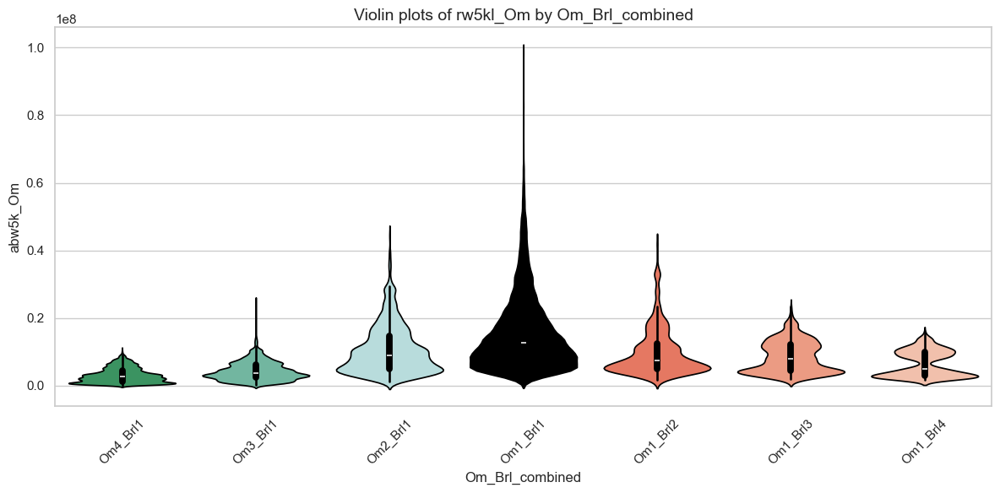

In [50]:
merged['Om_Brl_combined'] = merged.apply(
    lambda row: f"Om{row['cluster_4_Om']}_Brl{row['cluster_4_Brl']}", axis=1
)


conf= 'rw5kl_Om'
conf= 'abw5k_Om'
# Desired categories
categories = [
    "Om4_Brl1",
    "Om3_Brl1",
    "Om2_Brl1",
    "Om1_Brl1",
    "Om1_Brl2",
    "Om1_Brl3",
    "Om1_Brl4"
]

# Filter the data
filtered_df = merged[merged['Om_Brl_combined'].isin(categories)]

# Custom color palette:
# greens for Om4_Brl1, Om3_Brl1, Om2_Brl1
# black for Om1_Brl1
# red scale for Om1_Brl2, Om1_Brl3, Om1_Brl4
palette = {
    "Om4_Brl1": "#2ca25f",  # dark green
    "Om3_Brl1": "#66c2a4",  # mid green
    "Om2_Brl1": "#b2e2e2",  # light green
    "Om1_Brl1": "#000000",  # black
    "Om1_Brl2": "#fb6a4c",  # dark red
    "Om1_Brl3": "#fc9272",  # mid red
    "Om1_Brl4": "#fcbba1"   # light red
}

# Plot the violin
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=filtered_df,
    x='Om_Brl_combined',
    y=conf,
    order=categories,
    palette=palette
)
plt.title('Violin plots of rw5kl_Om by Om_Brl_combined', fontsize=14)
plt.xlabel('Om_Brl_combined')
plt.ylabel(conf)
#plt.yscale('log')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


C:\Users\aaraldi\AppData\Local\Temp\ipykernel_30792\3170009789.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


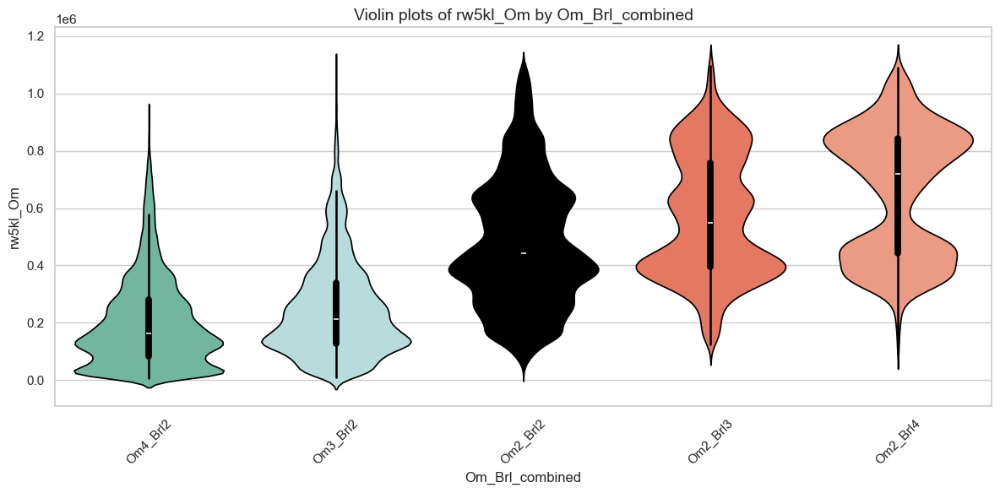

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

conf= 'rw5kl_Om'
#conf= 'abw5k_Om'
# Desired categories
categories = [
    "Om4_Brl2",
    "Om3_Brl2",
    "Om2_Brl2",
    "Om2_Brl3",
    "Om2_Brl4"]

# Filter the data
filtered_df = merged[merged['Om_Brl_combined'].isin(categories)]

# Custom color palette:
# greens for Om4_Brl1, Om3_Brl1, Om2_Brl1
# black for Om1_Brl1
# red scale for Om1_Brl2, Om1_Brl3, Om1_Brl4
palette = {
#    "Om4_Brl1": "#2ca25f",  # dark green
    "Om4_Brl2": "#66c2a4",  # mid green
    "Om3_Brl2": "#b2e2e2",  # light green
    "Om2_Brl2": "#000000",  # black
    "Om2_Brl3": "#fb6a4c",  # dark red
    "Om2_Brl4": "#fc9272",  # mid red
#    "Om1_Brl4": "#fcbba1"   # light red
}

# Plot the violin
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=filtered_df,
    x='Om_Brl_combined',
    y=conf,
    order=categories,
    palette=palette
)
plt.title('Violin plots of rw5kl_Om by Om_Brl_combined', fontsize=14)
plt.xlabel('Om_Brl_combined')
plt.ylabel(conf)
#plt.yscale('log')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# Select desired columns
subset = merged[['id', 'geometry', 'Om_Brl_combined']]

# Save to a GeoPackage file
subset.to_file("C:/Users/aaraldi/Desktop/EMC2_Streetscape/FLAVIA_Results_2506/merged_layers.gpkg", layer='merged_clusters', driver='GPKG')


### ORIGINAL METHOD OM and Mean Betw. corrected method

C:\Users\aaraldi\AppData\Local\Temp\ipykernel_30792\3230766324.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


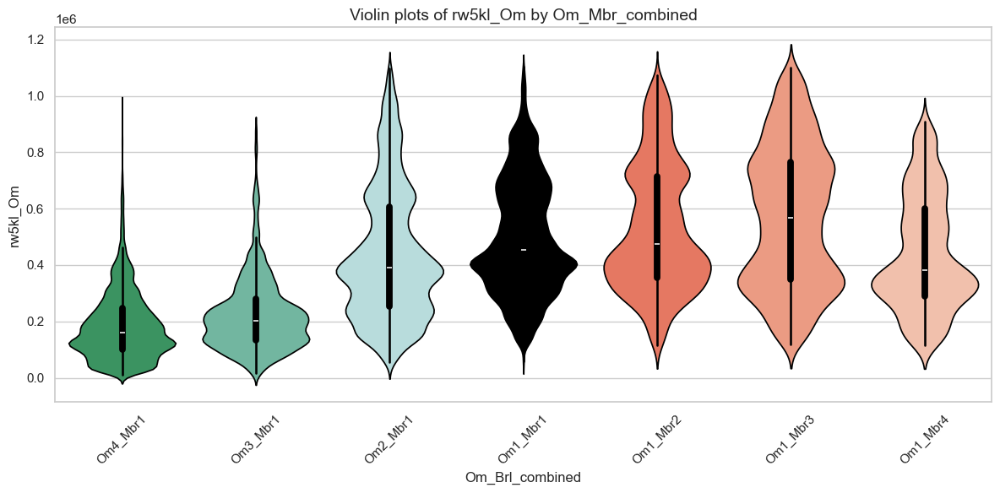

In [53]:
merged['Om_Mbr_combined'] = merged.apply(
    lambda row: f"Om{row['cluster_4_Om']}_Mbr{row['cluster_4_Mbr']}", axis=1
)


conf= 'rw5kl_Om'
#conf= 'abw5k_Om'
# Desired categories
categories = [
    "Om4_Mbr1",
    "Om3_Mbr1",
    "Om2_Mbr1",
    "Om1_Mbr1",
    "Om1_Mbr2",
    "Om1_Mbr3",
    "Om1_Mbr4"
]

# Filter the data
filtered_df = merged[merged['Om_Mbr_combined'].isin(categories)]

# Custom color palette:
# greens for Om4_Brl1, Om3_Brl1, Om2_Brl1
# black for Om1_Brl1
# red scale for Om1_Brl2, Om1_Brl3, Om1_Brl4
palette = {
    "Om4_Mbr1": "#2ca25f",  # dark green
    "Om3_Mbr1": "#66c2a4",  # mid green
    "Om2_Mbr1": "#b2e2e2",  # light green
    "Om1_Mbr1": "#000000",  # black
    "Om1_Mbr2": "#fb6a4c",  # dark red
    "Om1_Mbr3": "#fc9272",  # mid red
    "Om1_Mbr4": "#fcbba1"   # light red
}

# Plot the violin
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=filtered_df,
    x='Om_Mbr_combined',
    y=conf,
    order=categories,
    palette=palette
)
plt.title('Violin plots of rw5kl_Om by Om_Mbr_combined', fontsize=14)
plt.xlabel('Om_Brl_combined')
plt.ylabel(conf)
#plt.yscale('log')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


C:\Users\aaraldi\AppData\Local\Temp\ipykernel_30792\4269900441.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


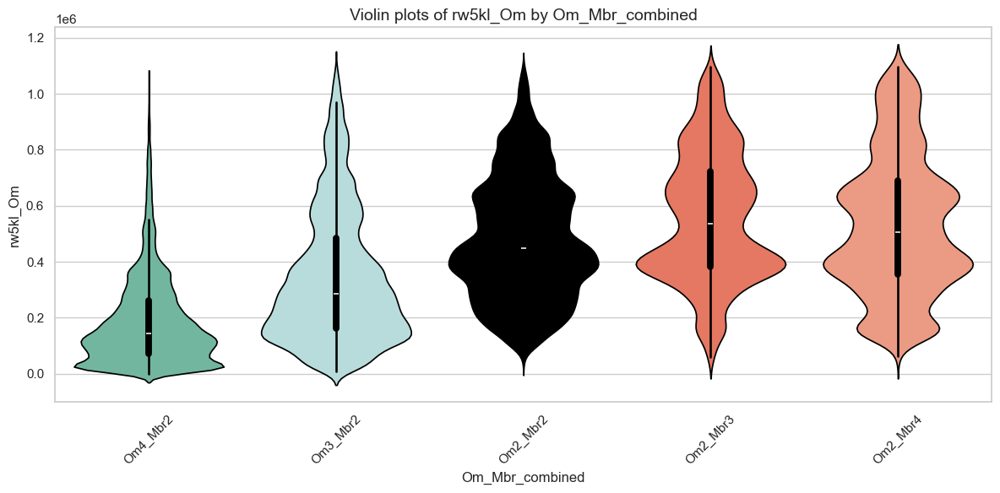

In [54]:

conf= 'rw5kl_Om'
#conf= 'abw5k_Om'
# Desired categories
categories = [
    "Om4_Mbr2",
    "Om3_Mbr2",
    "Om2_Mbr2",
    "Om2_Mbr3",
    "Om2_Mbr4"]

# Filter the data
filtered_df = merged[merged['Om_Mbr_combined'].isin(categories)]

# Custom color palette:
# greens for Om4_Brl1, Om3_Brl1, Om2_Brl1
# black for Om1_Brl1
# red scale for Om1_Brl2, Om1_Brl3, Om1_Brl4
palette = {
#    "Om4_Brl1": "#2ca25f",  # dark green
    "Om4_Mbr2": "#66c2a4",  # mid green
    "Om3_Mbr2": "#b2e2e2",  # light green
    "Om2_Mbr2": "#000000",  # black
    "Om2_Mbr3": "#fb6a4c",  # dark red
    "Om2_Mbr4": "#fc9272",  # mid red
#    "Om1_Brl4": "#fcbba1"   # light red
}

# Plot the violin
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=filtered_df,
    x='Om_Mbr_combined',
    y=conf,
    order=categories,
    palette=palette
)
plt.title('Violin plots of rw5kl_Om by Om_Mbr_combined', fontsize=14)
plt.xlabel('Om_Mbr_combined')
plt.ylabel(conf)
#plt.yscale('log')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [ ]:

# Select desired columns
subset = merged[['id', 'geometry', 'Om_Mbr_combined']]

# Save to a GeoPackage file
subset.to_file("C:/Users/aaraldi/Desktop/EMC2_Streetscape/FLAVIA_Results_2506/merged_layers.gpkg", layer='merged_clusters_MbrOM', driver='GPKG')


In [ ]:
#CONTINGENCY MATRIX OF UP/DOWNGRADING

In [56]:
# HERE BELOW THE CONTINGENCY MATRIXES by Cities where we instead of comparing the clustering types as they are,
#  we compare the up/downgrades of the two methods (reach and mean betw. corrected).


# Define groups for rows and columns
row_groups = {
    'Om2-4_Brl': ['Om2_Brl1', 'Om3_Brl1', 'Om4_Brl1'],
    'Om1_Brl1': ['Om1_Brl1'],
    'Om1_Brl234': ['Om1_Brl2', 'Om1_Brl3', 'Om1_Brl4'],
}
col_groups = {
    'Om2-4_Mbr': ['Om2_Mbr1', 'Om3_Mbr1', 'Om4_Mbr1'],
    'Om1_Mbr1': ['Om1_Mbr1'],
    'Om1_Mbr234': ['Om1_Mbr2', 'Om1_Mbr3', 'Om1_Mbr4'],
}

# Add 'Others' label to groups (they will catch all others)
row_groups['Others_Brl'] = []
col_groups['Others_Mbr'] = []

# Helper to map labels to groups
def map_to_group(label, groups):
    for group_name, labels in groups.items():
        if label in labels:
            return group_name
    return list(groups.keys())[-1]  # last group is 'Others'

cities = merged['city'].unique()

for city_name in cities:
    print(f"\n--- Contingency matrix for city: {city_name} ---")

    city_df = merged[merged['city'] == city_name].copy()
    city_df['row_group'] = city_df['Om_Brl_combined'].apply(lambda x: map_to_group(x, row_groups))
    city_df['col_group'] = city_df['Om_Mbr_combined'].apply(lambda x: map_to_group(x, col_groups))

    contingency = pd.crosstab(city_df['row_group'], city_df['col_group'])

    total = contingency.values.sum()
    others_cell = contingency.at['Others_Brl', 'Others_Mbr'] if ('Others_Brl' in contingency.index and 'Others_Mbr' in contingency.columns) else 0
    percentage_others_cell = (others_cell / total) * 100 if total > 0 else 0

    print(f"Value at ('Others_Brl', 'Others_Mbr') cell: {others_cell} ({percentage_others_cell:.2f}%)")

    # Now build the percentage matrix excluding the Others_Brl/Others_Mbr cell
    total_except_both_others = total - others_cell

    all_row_labels = ['Om2-4_Brl', 'Om1_Brl1', 'Om1_Brl234', 'Others_Brl']
    all_col_labels = ['Om2-4_Mbr', 'Om1_Mbr1', 'Om1_Mbr234', 'Others_Mbr']
    new_df = pd.DataFrame(0.0, index=all_row_labels, columns=all_col_labels)


    for r in all_row_labels:
        for c in all_col_labels:
            val = contingency.at[r, c] if (r in contingency.index and c in contingency.columns) else 0
            if r == 'Others_Brl' and c == 'Others_Mbr':
                new_df.at[r, c] = 0  # Zero only for both Others cell
            else:
                new_df.at[r, c] = (val / total_except_both_others) * 100 if val != 0 else 0

    print(new_df.round(2))



--- Contingency matrix for city: Gothenburg ---
Value at ('Others_Brl', 'Others_Mbr') cell: 369017 (91.05%)
            Om2-4_Mbr  Om1_Mbr1  Om1_Mbr234  Others_Mbr
Om2-4_Brl       25.18      0.00        0.00        9.31
Om1_Brl1         0.00     38.75        3.61        0.00
Om1_Brl234       0.00      1.52        2.48        0.00
Others_Brl      19.14      0.00        0.00        0.00

--- Contingency matrix for city: Lille ---
Value at ('Others_Brl', 'Others_Mbr') cell: 433933 (87.91%)
            Om2-4_Mbr  Om1_Mbr1  Om1_Mbr234  Others_Mbr
Om2-4_Brl       19.94      0.00        0.00       17.72
Om1_Brl1         0.00     36.23        3.24        0.00
Om1_Brl234       0.00      2.82        1.42        0.00
Others_Brl      18.63      0.00        0.00        0.00

--- Contingency matrix for city: Nice ---
Value at ('Others_Brl', 'Others_Mbr') cell: 388224 (87.87%)
            Om2-4_Mbr  Om1_Mbr1  Om1_Mbr234  Others_Mbr
Om2-4_Brl       24.47      0.00        0.00       17.74
Om1_Brl1    

# SANDBOX

# CLUSTERS VS QUANTILES of Centralities (Betw5K)

In [54]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Make sure arw5kab_Om is numeric
merged['arw5kab_Om'] = pd.to_numeric(merged['arw5kab_Om'], errors='coerce')

# Compute decile bins
merged['arw5kab_Om_decile'] = pd.qcut(merged['arw5kab_Om'], q=10, duplicates='drop')



## count%

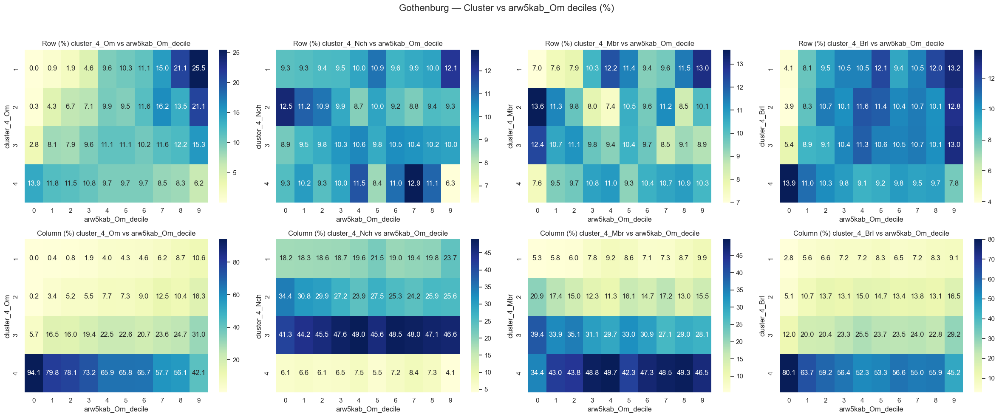

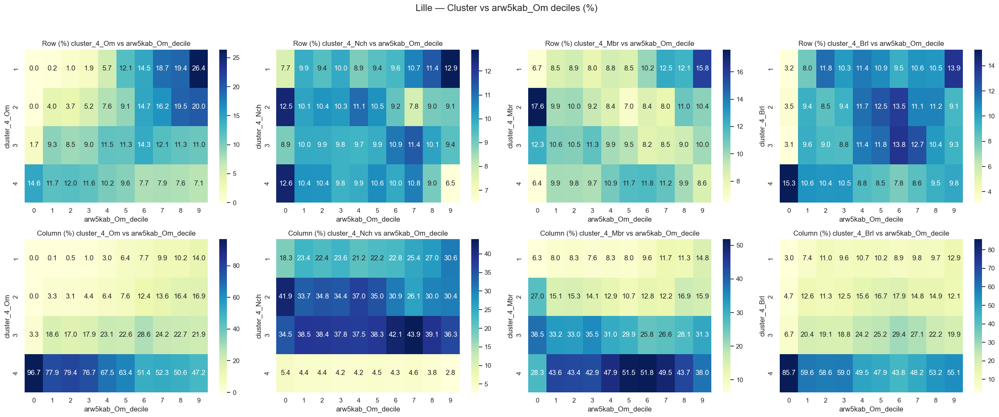

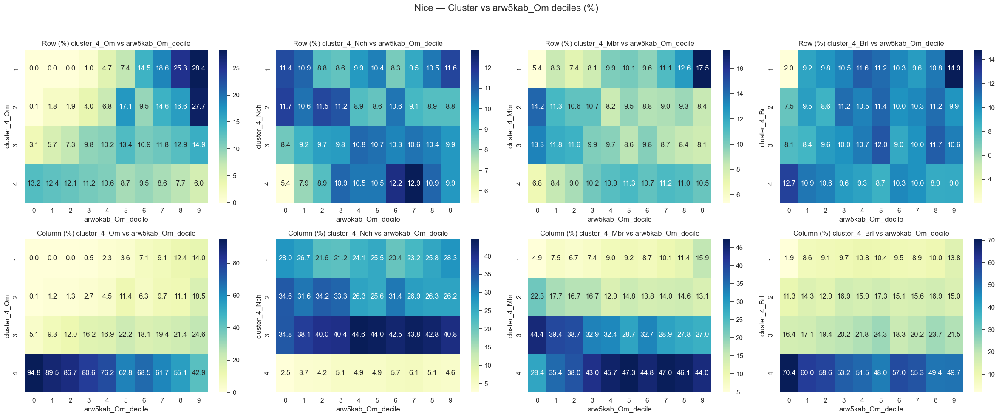

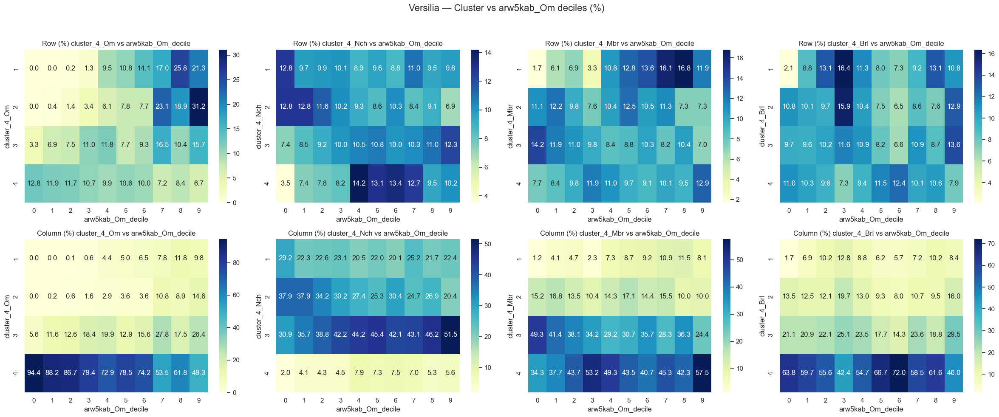

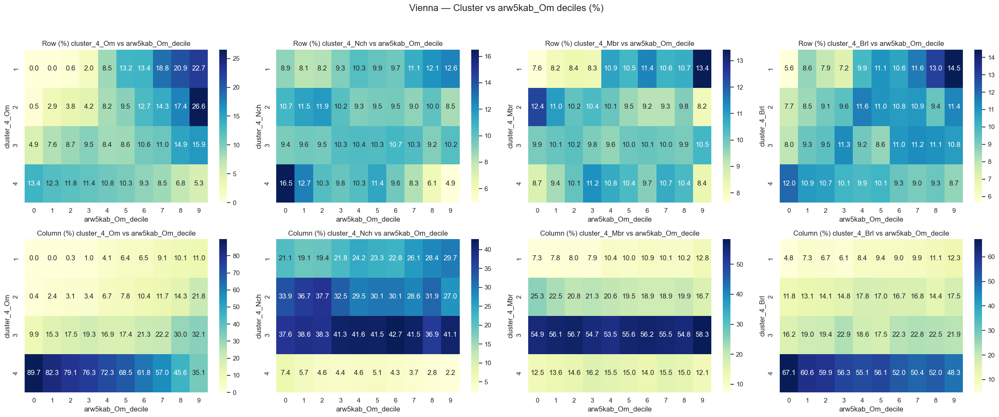

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')

def normalize_rows(df):
    return df.div(df.sum(axis=1), axis=0) * 100

def normalize_cols(df):
    return df.div(df.sum(axis=0), axis=1) * 100

# Loop over each city
cities = merged['city'].unique()

for city_name in cities:
    city_df = merged[merged['city'] == city_name].copy()

    # Compute deciles of arw5kab_Om
    city_df['arw5kab_Om_decile'] = pd.qcut(
        city_df['arw5kab_Om'], q=10, labels=False
    )
    
    fig, axes = plt.subplots(2, 4, figsize=(24, 10))  # 4 clusters => 4 columns
    fig.suptitle(f"{city_name} — Cluster vs arw5kab_Om deciles (%)", fontsize=16)

    for i, cluster_col in enumerate(['cluster_4_Om', 'cluster_4_Nch', 'cluster_4_Mbr', 'cluster_4_Brl']):
        filtered = city_df[city_df[cluster_col] != -1]

        # Contingency table
        contingency = pd.crosstab(
            filtered[cluster_col], filtered['arw5kab_Om_decile']
        )

        # Row-wise normalized (% of each cluster distributed across deciles)
        row_norm = normalize_rows(contingency)
        # Column-wise normalized (% of each decile distributed across clusters)
        col_norm = normalize_cols(contingency)

        # Row-wise heatmap
        sns.heatmap(
            row_norm, annot=True, fmt=".1f",
            cmap='YlGnBu', ax=axes[0, i]
        )
        axes[0, i].set_title(f'Row (%) {cluster_col} vs arw5kab_Om_decile')

        # Column-wise heatmap
        sns.heatmap(
            col_norm, annot=True, fmt=".1f",
            cmap='YlGnBu', ax=axes[1, i]
        )
        axes[1, i].set_title(f'Column (%) {cluster_col} vs arw5kab_Om_decile')

    plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for suptitle
    plt.show()


# length%

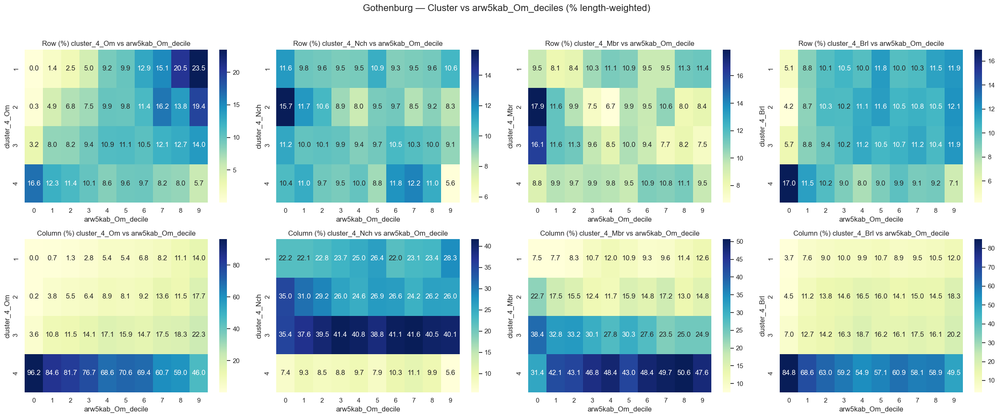

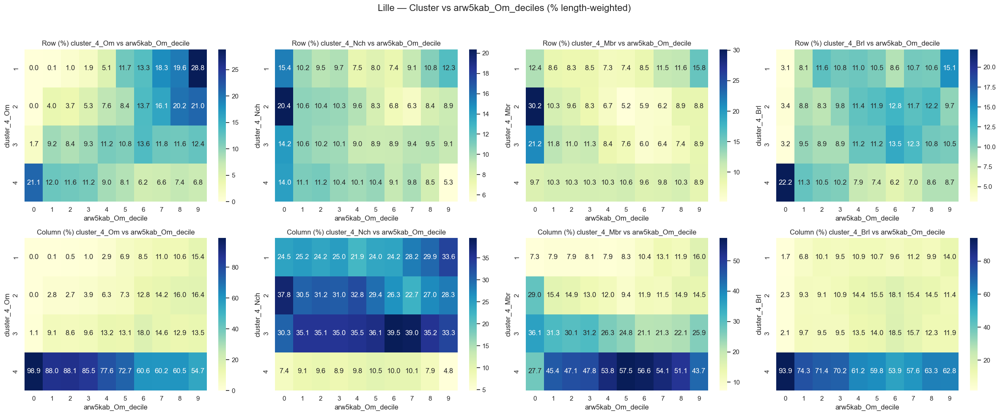

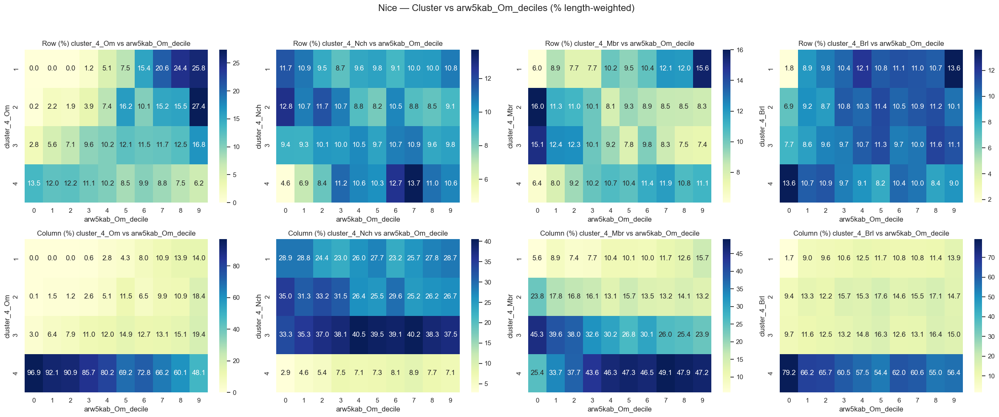

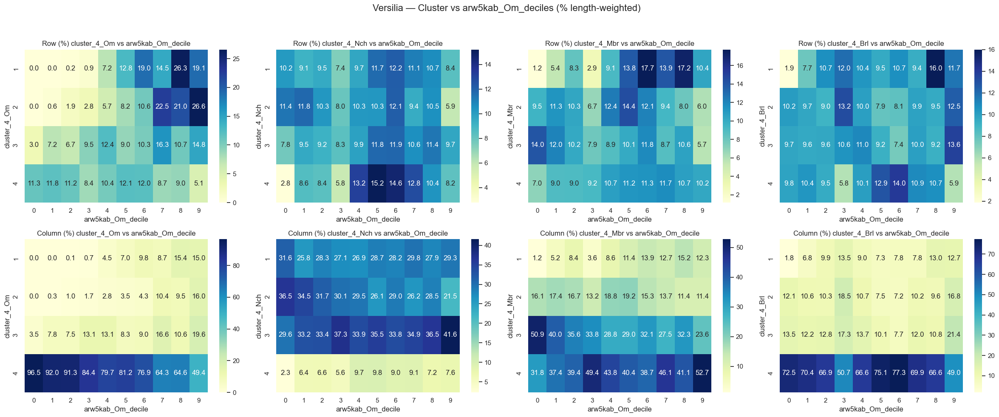

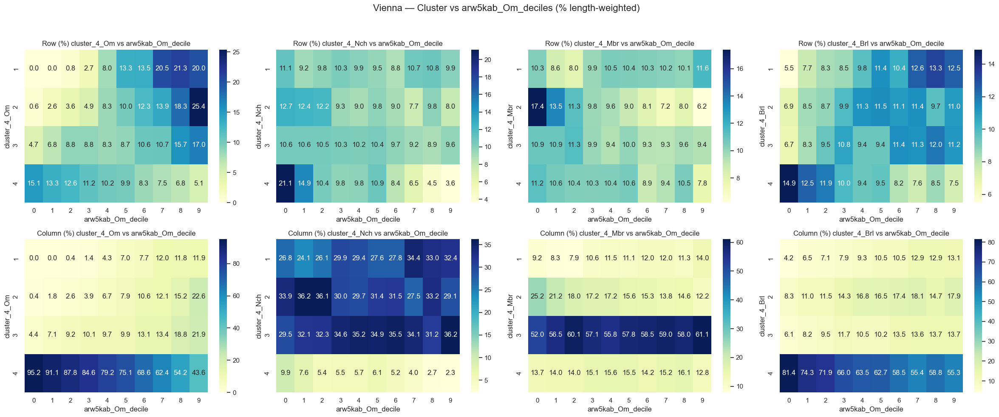

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')

def normalize_rows(df):
    return df.div(df.sum(axis=1), axis=0) * 100

def normalize_cols(df):
    return df.div(df.sum(axis=0), axis=1) * 100

# Loop over each city
cities = merged['city'].unique()

for city_name in cities:
    city_df = merged[merged['city'] == city_name].copy()

    # Compute deciles of arw5kab_Om
    city_df['arw5kab_Om_decile'] = pd.qcut(
        city_df['arw5kab_Om'], q=10, labels=False
    )
    
    fig, axes = plt.subplots(2, 4, figsize=(24, 10))  # 4 clusters => 4 columns
    fig.suptitle(f"{city_name} — Cluster vs arw5kab_Om_deciles (% length-weighted)", fontsize=16)

    for i, cluster_col in enumerate(['cluster_4_Om', 'cluster_4_Nch', 'cluster_4_Mbr', 'cluster_4_Brl']):
        filtered = city_df[city_df[cluster_col] != -1].copy()

        # Length-weighted sum per (cluster, arw5kab_Om_decile)
        length_df = (
            filtered.groupby([cluster_col, 'arw5kab_Om_decile'])['geometry']
            .apply(lambda g: g.length.sum())
            .reset_index()
        )

        # Pivot into contingency table
        contingency = length_df.pivot(
            index=cluster_col,
            columns='arw5kab_Om_decile',
            values='geometry'
        ).fillna(0)

        # Normalize
        row_norm = normalize_rows(contingency)
        col_norm = normalize_cols(contingency)

        # Row-wise heatmap
        sns.heatmap(
            row_norm, annot=True, fmt=".1f",
            cmap='YlGnBu', ax=axes[0, i]
        )
        axes[0, i].set_title(f'Row (%) {cluster_col} vs arw5kab_Om_decile')

        # Column-wise heatmap
        sns.heatmap(
            col_norm, annot=True, fmt=".1f",
            cmap='YlGnBu', ax=axes[1, i]
        )
        axes[1, i].set_title(f'Column (%) {cluster_col} vs arw5kab_Om_decile')

    plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for suptitle
    plt.show()


In [ ]:
# AVEC NACH

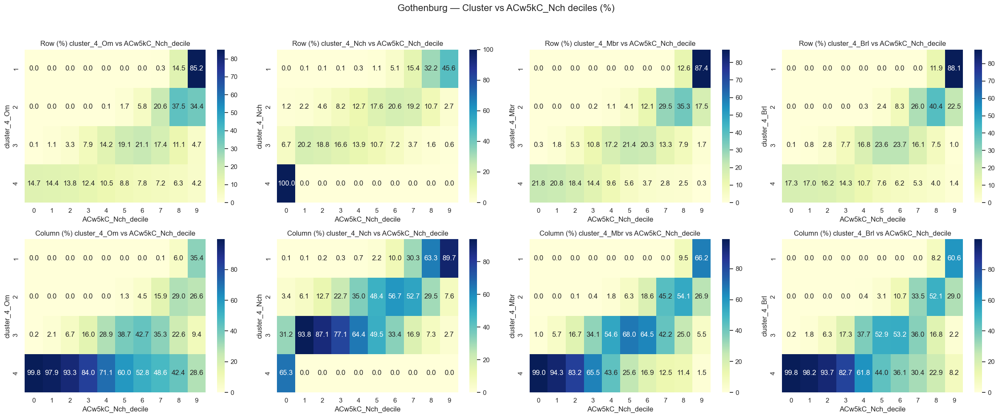

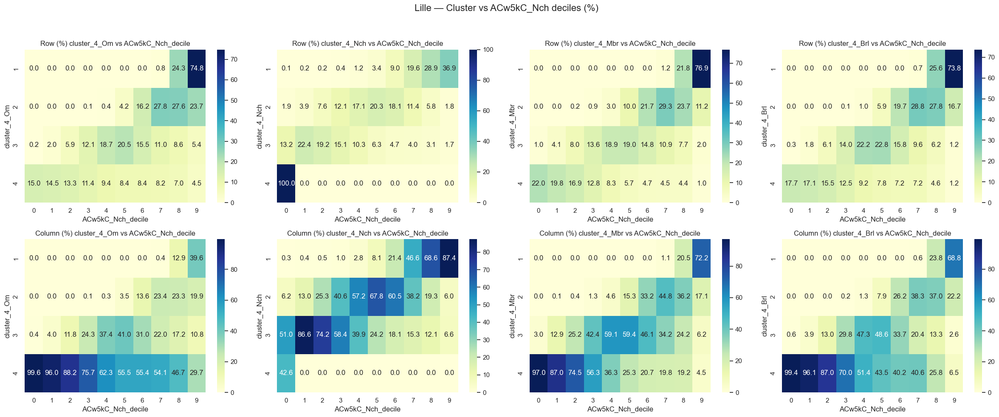

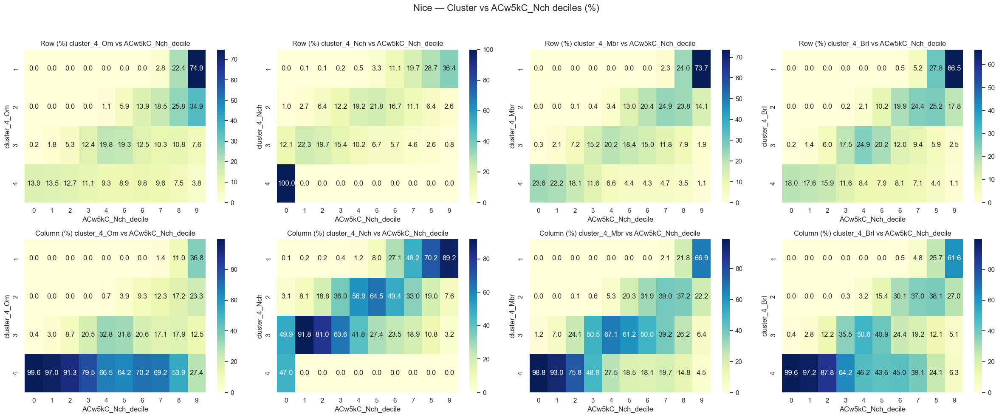

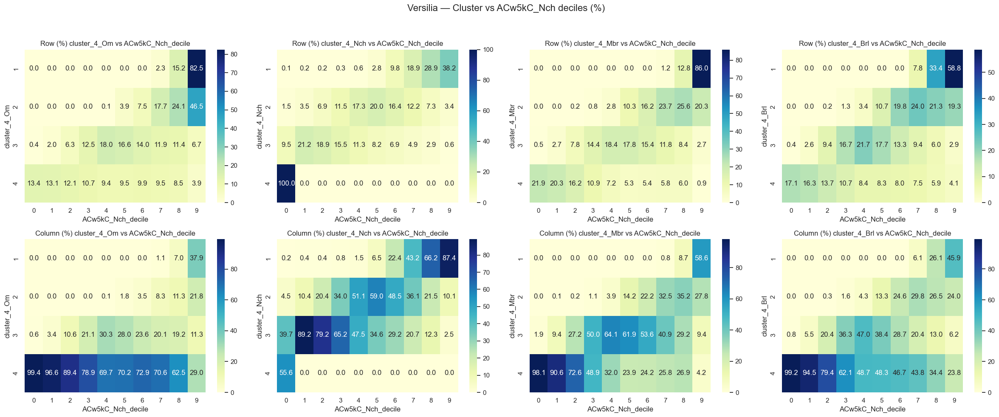

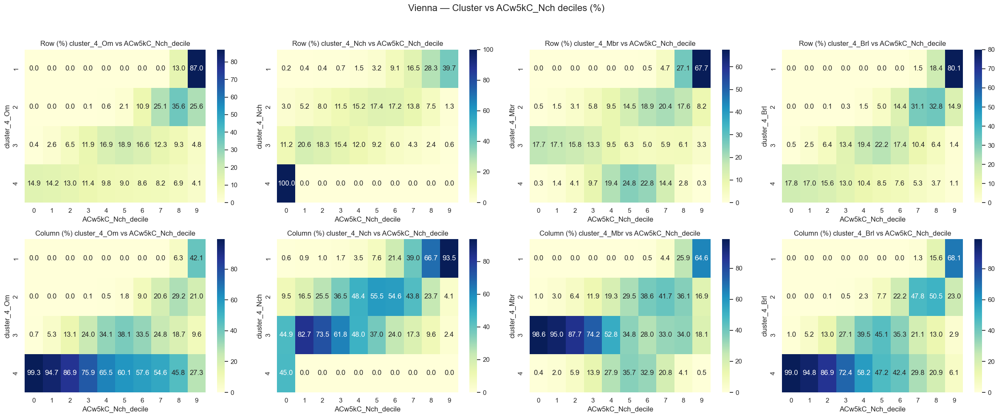

In [58]:
# Choose which column to split into quantiles
quantile_var = 'ACw5kC_Nch'  # <-- Change this to whatever column you want

# Loop over each city
cities = merged['city'].unique()

for city_name in cities:
    city_df = merged[merged['city'] == city_name].copy()

    # Compute deciles of chosen variable
    city_df[quantile_var + '_decile'] = pd.qcut(
        city_df[quantile_var], q=10, labels=False
    )
    
    fig, axes = plt.subplots(2, 4, figsize=(24, 10))  # 4 clusters => 4 columns
    fig.suptitle(f"{city_name} — Cluster vs {quantile_var} deciles (%)", fontsize=16)

    for i, cluster_col in enumerate(
        ['cluster_4_Om', 'cluster_4_Nch', 'cluster_4_Mbr', 'cluster_4_Brl']
    ):
        filtered = city_df[city_df[cluster_col] != -1]

        # Contingency table
        contingency = pd.crosstab(
            filtered[cluster_col], filtered[quantile_var + '_decile']
        )

        # Row-wise normalized (% of each cluster distributed across deciles)
        row_norm = normalize_rows(contingency)
        # Column-wise normalized (% of each decile distributed across clusters)
        col_norm = normalize_cols(contingency)

        # Row-wise heatmap
        sns.heatmap(
            row_norm, annot=True, fmt=".1f",
            cmap='YlGnBu', ax=axes[0, i]
        )
        axes[0, i].set_title(f'Row (%) {cluster_col} vs {quantile_var}_decile')

        # Column-wise heatmap
        sns.heatmap(
            col_norm, annot=True, fmt=".1f",
            cmap='YlGnBu', ax=axes[1, i]
        )
        axes[1, i].set_title(f'Column (%) {cluster_col} vs {quantile_var}_decile')

    plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for suptitle
    plt.show()
